# **Cross-bank analysis of earnings-call Q&A: topics, trajectories, tone and retrieval**

**This notebook was prepared by Dr Gulnaz Aksenova**

**The code was generated with Claude Opus 5.5 (high) following guidance set by the author through mutliple iterations and testing.**

This notebook analyses the question-and-answer sections of the earnings calls of JPMorgan Chase, Citigroup and Bank of America (1Q 2021–2Q 2026). One topic model is estimated on the pooled Q&A of all banks, so that every bank is described with the same topics. The banks are then compared on what is discussed, how the discussion changes over time, and the tone of analysts and management. The final section is a retrieval-augmented generation (RAG) system for querying the corpus with cited answers.

| Section | Content | Main outputs → `EmProject/cross_bank_qa/` |
|---|---|---|
| 1–3 | Setup, Q&A corpus, embeddings | cached embeddings |
| 4–6 | Topic model: selection, final model, quality and stability | `topic_info.csv`, `bertopic_model/` |
| 7 | Topics across banks | `cross_bank_results.xlsx` |
| 8 | Topic trajectories across banks | `topic_trends.csv`, `topic_share_over_time.png`, `agenda_distance.png` |
| 9 | Tone across banks (FinBERT) | `tone_over_time.png`, `tone_differences_between_banks.png` |
| 10 | Themes | `theme_mapping.csv`, `theme_share_over_time.png` |
| 11 | Unusual calls | `unusual_calls.png` |
| 12–13 | Manual review samples, saved outputs | `review_samples.xlsx`, `qa_chunks_topics_tone.parquet` |
| 14 | RAG system | `rag/rag_evaluation.xlsx` |
| 15 | Findings | — |

**Input:** `transcripts_analytical_units.parquet` (speaker turns from the main notebook, 1.10).

**How to run:** select Runtime → Change runtime type → T4 GPU, then Runtime → Run all. Embeddings and FinBERT scores are cached on Drive, so later runs are faster. In section 10, theme names and exclusions are set after the first run (see 10.1).

**Reproducibility:** fixed seeds for every random step, a PCA start for UMAP, cached embeddings that are reused only for identical texts, and greedy (non-random) text generation in the RAG.


## Methodology

**Research design.** The analysis compares banks on a common basis.
- *One topic model for all banks.* Topics are estimated on the pooled Q&A of all banks, so the same topic means the same subject at every bank.
- *Like-for-like periods.* Comparisons of topic prevalence use only quarters covered by every compared bank.
- *Independent units for tone.* Each call contributes one value to tone comparisons, because chunks from the same call are not independent.
- *Each bank as its own reference for anomalies.* Unusual calls are defined against the same bank's history.
- *Multiple testing.* Where many tests are run, p-values are adjusted (Benjamini–Hochberg or Bonferroni).
- *Bank of America.* With two calls, it is included in descriptive comparisons but not in trend tests.

**Data and unit of analysis.** All analyst–management exchanges in the Q&A sections, defined as in the main notebook: an exchange starts when an analyst speaks after another speaker. Questions (all analyst turns of an exchange) and answers (all management turns) are divided separately into chunks of three consecutive sentences, and chunks shorter than 12 words are excluded. The chunk is the unit of analysis. A chunk usually covers one subject and fits within the input limits of the embedding model and FinBERT, and separating questions from answers allows every result to be split by speaker type.

**Topic model (sections 3–6).**
- *Embeddings:* each chunk is embedded with `all-MiniLM-L6-v2`.
- *Dimension reduction:* UMAP reduces the embeddings to five dimensions, starting from a PCA layout with a fixed seed.
- *Clustering:* HDBSCAN forms the topics; the minimum topic size is chosen by comparing candidates on coherence (NPMI), diversity, number of topics and share of outliers.
- *Descriptions:* topics are described with c-TF-IDF, KeyBERT-inspired and maximal-marginal-relevance word lists.
- *Outlier reassignment:* outlier chunks close to a topic centroid are reassigned to it.
- *Checks:* reproducibility (same seed), stability (other seeds, adjusted Rand index) and a topic hierarchy.

**Comparisons between banks (sections 7–11)** are described at the start of each section.

**RAG (section 14).** Hybrid retrieval (embeddings and BM25, combined by reciprocal rank fusion and re-ranked by a cross-encoder) with an open language model, which answers only from cited sources. Retrieval is evaluated against a keyword-based test set, and answers are checked for citations and reviewed manually.

**Limitations.**
- Topics depend on the chunk length, the embedding model and the minimum topic size.
- FinBERT was trained on written financial text, so its scores for spoken Q&A are approximate.
- With 22 calls per bank, the trend and anomaly tests have limited power.
- Topic labels and RAG answers are interpreted only after manual review of the underlying text.
- The chi-square test treats chunks as independent, although chunks from the same call and exchange are related; p-values are therefore understated, and Cramér's V and the ranking of residuals are the main evidence.
-- With 22 calls per bank and correction for about 60 tests, the trend tests detect only strong, consistent changes; tendencies with moderate τ are reported descriptively. The "persistent" class indicates presence in most calls, not the absence of change, and is sensitive to outlier reassignment (28% of trajectories changed).
- Correlations of smoothed shares are not tested for significance, because smoothing introduces dependence between neighbouring quarters; correlations for topics with few chunks at one bank (e.g. consent orders at JPMorgan Chase) are not interpreted. The level of agenda distance includes sampling variation from about 150 chunks per call spread over 34 topics; its trend is the informative measure.

## 1. Setup
### 1.1 Libraries, inputs and settings
All modelling choices are set here; changing a value and re-running the notebook repeats the analysis with that value.

In [2]:
# ------------------------------------------------------------------
# 1.1 SETUP: libraries, inputs and every setting of the analysis
# Self-contained: reads the speaker turns saved by 1.10.
# All modelling choices are set here, so the analysis can be repeated
# with other values by changing this cell and re-running the notebook.
# ------------------------------------------------------------------
!pip install -q bertopic==0.17.4                  # torch, transformers, sentence-transformers are in Colab

from google.colab import drive
drive.mount('/content/drive')

import hashlib
import importlib.metadata
import itertools
import random
import re
import textwrap
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from bertopic import BERTopic
from bertopic.dimensionality import BaseDimensionalityReduction
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance
from bertopic.vectorizers import ClassTfidfTransformer
from hdbscan import HDBSCAN
from scipy.stats import kendalltau, theilslopes
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from sklearn.metrics import adjusted_rand_score
from transformers import pipeline
from umap import UMAP

REPO_ROOT = Path('/content/drive/MyDrive/Colab_Git/saad-muddasser/CamDS2026_EmpProj_Team7')
WORK_DIR  = REPO_ROOT / 'notebooks' / 'EmProject'
OUT_DIR   = WORK_DIR / 'cross_bank_qa'            # outputs of this notebook
OUT_DIR.mkdir(exist_ok=True)

# ---- Documents ----
CHUNK_SENTENCES = 3       # one document = 3 consecutive sentences of a question or an answer
MIN_CHUNK_WORDS = 12      # shorter chunks (greetings, thanks) are excluded
SEED            = 42      # fixes every random step

# ---- Models ----
EMBEDDING_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'   # subject similarity (topics)
FINBERT_MODEL   = 'ProsusAI/finbert'                         # financial tone

# ---- Topic model ----
UMAP_PARAMS     = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine',
                       init='pca')   # PCA start: identical result on every run (spectral start can vary)
SIZE_GRID       = [20, 30, 40, 60, 80]   # minimum topic sizes compared in 4.1
MIN_TOPIC_SIZE  = 40      # value used for the final model (review the grid in 4.1 before fixing it)
MIN_SAMPLES     = 10      # HDBSCAN: higher values give more conservative clusters and more outliers
TOP_N_WORDS     = 10      # words per topic used for labels and quality measures
MIN_DF          = 2       # a word or bigram must occur in the text of at least 2 topics (BERTopic counts per topic)
REASSIGN_OUTLIERS = True  # outlier chunks close enough to a topic centroid are assigned to it (5.1)
SIM_QUANTILE    = 0.05    # 'close enough' = above the 5th percentile of members' similarity to their centroid
STABILITY_SEEDS = [1, 2, 3]   # UMAP seeds used to test the stability of the topics (6.1)

# ---- Trajectories (rules applied in 8.1) ----
ROLL_QUARTERS, RECENT_QUARTERS, MIN_QUARTERS = 4, 4, 8
MIN_TOPIC_CHUNKS, ALPHA = 10, 0.05
RISE_RATIO, FALL_RATIO, CONCENTRATION, PERSISTENCE = 2.0, 0.5, 0.5, 0.75

# ---- Tone ----
FINBERT_BATCH = 32
REVIEW_PER_LABEL = 10     # chunks per FinBERT label in the manual validation sample (12.1)

BANK_COLOURS = {'JPMorgan Chase': '#2a78d6', 'Citigroup': '#eb6834', 'Bank of America': '#1baf7a'}

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

units = pd.read_parquet(WORK_DIR / 'transcripts_analytical_units.parquet')     # speaker turns (1.10)
print(f'{len(units):,} speaker turns | device: {DEVICE}')
print(' | '.join(f'{p} {importlib.metadata.version(p)}' for p in
                 ['bertopic', 'sentence-transformers', 'transformers', 'torch', 'umap-learn', 'hdbscan']))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
4,249 speaker turns | device: cuda
bertopic 0.17.4 | sentence-transformers 5.7.0 | transformers 5.18.0 | torch 2.11.0+cu130 | umap-learn 0.5.12 | hdbscan 0.8.44


## 2. Q&A corpus
### 2.1 Exchanges and chunks for every call of every bank

In [3]:
# ------------------------------------------------------------------
# 2.1 Q&A CORPUS: every exchange of every call, split into chunks
#   - exchange rule as in 1.16.2: a new exchange starts when an analyst
#     speaks after someone else; exchange 0 (operator opening) is dropped
#   - questions (all analyst turns of an exchange) and answers (all
#     management turns) are chunked separately: 3 sentences per chunk
#   - original text is used: the sentence model needs full sentences
# ------------------------------------------------------------------
SENTENCE_SPLIT = re.compile(r'(?<=[.!?])\s+(?=[A-Z"“(])')


def chunks(text, size=CHUNK_SENTENCES):
    """Split a text into consecutive groups of `size` sentences."""
    if not isinstance(text, str):
        return []
    sentences = SENTENCE_SPLIT.split(text.strip())
    return [' '.join(sentences[i:i + size]) for i in range(0, len(sentences), size)]


qa = (units[units['section'].eq('qa')]
      .sort_values(['doc_id', 'turn_number'])
      .reset_index(drop=True))
is_analyst = qa['speaker_type'].eq('analyst')
starts_exchange = is_analyst & ~is_analyst.groupby(qa['doc_id']).shift(fill_value=False)
qa['exchange'] = starts_exchange.astype(int).groupby(qa['doc_id']).cumsum()
qa = qa[qa['exchange'].gt(0) & qa['speaker_type'].isin(['analyst', 'management'])]

CALL_COLS = ['doc_id', 'exchange', 'bank', 'reporting_period', 'announcement_date']
texts = qa.groupby(CALL_COLS + ['speaker_type'], sort=False)['text'].agg(' '.join).reset_index()

rows = []
for r in texts.itertuples(index=False):
    role = 'question' if r.speaker_type == 'analyst' else 'answer'
    for i, chunk in enumerate(chunks(r.text)):
        rows.append({'doc_id': r.doc_id, 'exchange': r.exchange, 'bank': r.bank,
                     'reporting_period': r.reporting_period, 'announcement_date': r.announcement_date,
                     'role': role, 'speaker_type': r.speaker_type, 'chunk_no': i, 'text': chunk})

corpus = pd.DataFrame(rows)
corpus = corpus[corpus['text'].str.split().str.len() >= MIN_CHUNK_WORDS].reset_index(drop=True)
# Calendar quarter reported: calls take place 2-6 weeks after quarter end,
# so 45 days before the announcement date falls inside the reported quarter
corpus['quarter'] = (pd.to_datetime(corpus['announcement_date']) - pd.Timedelta(days=45)).dt.to_period('Q')
docs = corpus['text'].tolist()

overview = pd.DataFrame({
    'calls': corpus.groupby('bank')['doc_id'].nunique(),
    'exchanges': corpus.drop_duplicates(['doc_id', 'exchange']).groupby('bank').size(),
    'chunks': corpus.groupby('bank').size(),
    '% question chunks': corpus.groupby('bank')['role'].apply(lambda s: s.eq('question').mean() * 100).round(1),
    'median words per chunk': corpus.groupby('bank')['text'].apply(lambda s: s.str.split().str.len().median()),
})
print(f'{len(corpus):,} Q&A chunks from {corpus["doc_id"].nunique()} calls')
display(overview)


6,945 Q&A chunks from 46 calls


,calls,exchanges,chunks,% question chunks,median words per chunk
bank,,,,,
Bank of America,2,45,286,27.6,43.5
Citigroup,22,507,3157,30.0,49.0
JPMorgan Chase,22,614,3502,28.5,43.0


## 3. Embeddings
### 3.1 Sentence embeddings for every chunk
Cached on Drive and reused only when the model and the texts are unchanged.

In [4]:
# ------------------------------------------------------------------
# 3.1 EMBEDDINGS: each chunk becomes a vector of meaning
# Cached on Drive; reused only if the model and the exact texts are
# unchanged (checked with a fingerprint of all chunks).
# ------------------------------------------------------------------
embedder = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)

fingerprint = hashlib.sha256((EMBEDDING_MODEL + '\n'.join(docs)).encode()).hexdigest()[:16]
emb_path = WORK_DIR / f'all_qa_chunk_embeddings_{fingerprint}.npy'   # cache shared with earlier runs on the same texts

if emb_path.exists():
    embeddings = np.load(emb_path)
    print(f'Loaded cached embeddings ({emb_path.name})')
else:
    embeddings = embedder.encode(docs, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
    np.save(emb_path, embeddings)
    print(f'Computed and saved embeddings ({emb_path.name})')
print('Embedding matrix:', embeddings.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded cached embeddings (all_qa_chunk_embeddings_271bf05db5fe8622.npy)
Embedding matrix: (6945, 384)


## 4. Model selection
UMAP is fitted once and its output is reused, so that the candidates differ only in the minimum topic size. Each candidate is assessed on:
- **number of topics** and **% outliers**;
- **% of chunks in the largest topic**;
- **coherence (NPMI):** whether a topic's top words occur in the same chunks more often than chance (−1 never, 0 independent, +1 always together);
- **diversity:** the share of unique words among all topics' top words.

No single measure decides the choice. The value is fixed in 1.1 after reviewing the grid together with the topic words.
### 4.1 Candidate minimum topic sizes

In [5]:
# ------------------------------------------------------------------
# 4.1 MODEL SELECTION: minimum topic size
# - UMAP is fitted once (fixed seed); its 5-dimensional output is reused
#   for every candidate, so candidates differ only in the topic size.
# - For each size: number of topics, % outliers, size of the largest
#   topic, coherence (NPMI) and diversity of the topic words.
#   NPMI: do a topic's top words occur in the same chunks more often than
#   chance? (-1 never together, 0 independent, +1 always together)
#   Diversity: share of unique words across all topics' top words
#   (1 = no word repeated between topics).
# ------------------------------------------------------------------
CALL_WORDS = {'question', 'questions', 'call', 'morning', 'afternoon', 'thank', 'thanks', 'yeah', 'okay', 'ok',
              'lot', 'bit', 'kind', 'sort', 'way', 'thing', 'things', 'think', 'going', 'just', 'know', 'like',
              'really', 'yes', 'right', 'good', 'great', 'sure', 'little', 'said', 'say', 'look', 'mean', 'don',
              've', 'll', 're', 'got', 'guys', 'people', 'obviously', 'cetera', 'etc', 'maybe', 'want', 'actually'}
BANK_WORDS = {'jpmorgan', 'chase', 'jpm', 'citi', 'citigroup', 'citibank', 'bofa', 'america'}
NAME_WORDS = {w.lower().strip('.,') for name in units['speaker'].dropna().unique() for w in name.split()}
TOPIC_STOPWORDS = sorted(set(ENGLISH_STOP_WORDS) | CALL_WORDS | BANK_WORDS | NAME_WORDS)
# Stopwords only affect the words that DESCRIBE topics; the grouping uses the embeddings of full sentences.


def make_vectorizer(min_df=MIN_DF):
    """Word and bigram counter used to describe topics (same settings everywhere in this notebook)."""
    return CountVectorizer(stop_words=TOPIC_STOPWORDS, ngram_range=(1, 2), min_df=min_df)


def make_clusterer(min_size):
    """HDBSCAN with the settings of this notebook and a given minimum topic size."""
    return HDBSCAN(min_cluster_size=min_size, min_samples=min(MIN_SAMPLES, min_size), metric='euclidean',
                   cluster_selection_method='eom', prediction_data=True)


# Binary chunk x term matrix for coherence: does a word occur in a chunk?
term_vectorizer = make_vectorizer(min_df=1).fit(docs)        # every topic word must be found
presence = (term_vectorizer.transform(docs) > 0).astype(np.float32).tocsc()
term_index = {w: i for i, w in enumerate(term_vectorizer.get_feature_names_out())}


def npmi(words):
    """Mean normalised pointwise mutual information over all pairs of `words`, counted within chunks."""
    idx = [term_index[w] for w in words if w in term_index]
    if len(idx) < 2:
        return np.nan
    sub = presence[:, idx]
    n = presence.shape[0]
    p = np.asarray(sub.sum(axis=0)).ravel() / n                    # P(word)
    joint = (sub.T @ sub).toarray() / n                            # P(word i and word j)
    scores = []
    for i, j in itertools.combinations(range(len(idx)), 2):
        pij = joint[i, j]
        scores.append(-1.0 if pij == 0 else 1.0 if pij >= 1 else
                      np.log(pij / (p[i] * p[j])) / -np.log(pij))
    return float(np.mean(scores))


def topic_quality(model):
    """Mean NPMI coherence and word diversity of a fitted BERTopic model (outliers excluded)."""
    word_lists = [[w for w, _ in model.get_topic(t)][:TOP_N_WORDS]
                  for t in sorted(model.get_topics()) if t >= 0]
    word_lists = [ws for ws in word_lists if ws and ws[0]]
    all_words = [w for ws in word_lists for w in ws]
    coherence = np.nanmean([npmi(ws) for ws in word_lists]) if word_lists else np.nan
    diversity = len(set(all_words)) / len(all_words) if all_words else np.nan
    return coherence, diversity


def fit_topics(min_size, reduced_embeddings, **extra):
    """Fit BERTopic on pre-reduced embeddings; returns (model, topic per chunk)."""
    model = BERTopic(umap_model=BaseDimensionalityReduction(),        # UMAP already applied
                     hdbscan_model=make_clusterer(min_size),
                     vectorizer_model=make_vectorizer(),
                     ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
                     top_n_words=TOP_N_WORDS, verbose=False, **extra)
    topics, _ = model.fit_transform(docs, embeddings=reduced_embeddings)
    return model, np.asarray(topics)


reduced = UMAP(**UMAP_PARAMS, random_state=SEED).fit_transform(embeddings)

grid_rows = []
for size in SIZE_GRID:
    try:
        model, labels = fit_topics(size, reduced)
    except (ValueError, TypeError) as err:                         # e.g. a size so large that < 2 topics remain
        grid_rows.append({'min_topic_size': size, 'note': f'not fitted: {err}'})
        continue
    coherence, diversity = topic_quality(model)
    counts = pd.Series(labels[labels >= 0]).value_counts()
    grid_rows.append({'min_topic_size': size, 'topics': labels.max() + 1,
                      '% outliers': 100 * (labels == -1).mean(),
                      '% in largest topic': 100 * counts.max() / len(labels) if len(counts) else np.nan,
                      'coherence (NPMI)': coherence, 'diversity': diversity})
grid = pd.DataFrame(grid_rows)
print(f'Candidates compared on {len(docs):,} chunks (value used: MIN_TOPIC_SIZE = {MIN_TOPIC_SIZE}):')
display(grid.style.format({'% outliers': '{:.1f}', '% in largest topic': '{:.1f}',
                           'coherence (NPMI)': '{:.3f}', 'diversity': '{:.2f}'})
            .apply(lambda r: ['font-weight: bold' if r['min_topic_size'] == MIN_TOPIC_SIZE else ''] * len(r), axis=1))


Candidates compared on 6,945 chunks (value used: MIN_TOPIC_SIZE = 40):


,min_topic_size,topics,% outliers,% in largest topic,coherence (NPMI),diversity
0,20,59,37.5,5.0,-0.146,0.96
1,30,43,33.9,9.0,-0.104,0.98
2,40,34,34.6,9.0,-0.037,0.98
3,60,26,36.2,9.0,0.052,0.98
4,80,2,0.6,97.4,-0.097,1.00


This table compares five versions of the topic model. Each row uses the same data and the same UMAP output; only the minimum topic size changes, which is the smallest number of chunks HDBSCAN accepts as a topic. The goal is to pick the size that gives topics that are interpretable, distinct and coherent.

Five minimum topic sizes were compared. A size of 80 produced a degenerate solution (one topic containing 97% of chunks). Between 20 and 60, the share of outliers (34–37%) and topic diversity (0.96–0.98) varied little, while coherence increased with topic size (NPMI −0.146 to 0.052). A size of 40 (34 topics) was selected to retain subjects relevant to the cross-bank comparison as separate topics; results were checked against a size of 60.

**2 size was selected as the most optimal for topic modelling.**

## 5. Final topic model
- *Main description:* c-TF-IDF words most specific to each topic, used for the labels.
- *Additional descriptions:* KeyBERT-inspired words (closest in meaning to the topic's chunks) and maximal marginal relevance (fewer near-duplicate words).
- *Stopwords:* courtesies, bank names and speaker names are removed from the descriptions only, not from the clustering.
- *Outlier reassignment:* an outlier chunk joins the nearest topic centroid if its cosine similarity is at least the 5th percentile of the member chunks' similarity to their own centroid.
### 5.1 Fit, describe and reassign

In [6]:
# ------------------------------------------------------------------
# 5.1 FINAL TOPIC MODEL
# - Same reduced embeddings and clustering as the grid, with MIN_TOPIC_SIZE.
# - Three descriptions per topic:
#     Main     c-TF-IDF: words most specific to the topic (used for labels)
#     KeyBERT  words whose meaning is closest to the topic's chunks
#     MMR      Main words re-ranked to reduce near-duplicates
# - Outlier reassignment (if REASSIGN_OUTLIERS): an outlier chunk is
#   assigned to the nearest topic centroid when its cosine similarity is
#   above the SIM_QUANTILE percentile of members' similarity to their own
#   centroid; topic words are then recalculated.
# ------------------------------------------------------------------
REPRESENTATION = {'KeyBERT': KeyBERTInspired(top_n_words=TOP_N_WORDS, random_state=SEED),
                  'MMR': MaximalMarginalRelevance(diversity=0.3, top_n_words=TOP_N_WORDS)}

topic_model, topics_initial = fit_topics(MIN_TOPIC_SIZE, reduced, embedding_model=embedder,
                                         representation_model=REPRESENTATION)
corpus['topic_initial'] = topics_initial
TOPICS = sorted(t for t in set(topics_initial) if t >= 0)

# Topic centroids in the original embedding space (unit vectors, so dot product = cosine similarity)
centroids = np.vstack([embeddings[topics_initial == t].mean(axis=0) for t in TOPICS])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
position = {t: i for i, t in enumerate(TOPICS)}
members = topics_initial >= 0
own_similarity = (embeddings[members] * centroids[[position[t] for t in topics_initial[members]]]).sum(axis=1)
MIN_SIMILARITY = float(np.quantile(own_similarity, SIM_QUANTILE))

similarity = embeddings @ centroids.T
corpus['similarity'] = similarity.max(axis=1)
nearest = np.array(TOPICS)[similarity.argmax(axis=1)]
reassign = REASSIGN_OUTLIERS & (topics_initial == -1) & (corpus['similarity'].to_numpy() >= MIN_SIMILARITY)
corpus['topic'] = np.where(reassign, nearest, topics_initial)

if reassign.any():                                                # BERTopic warns here; expected, as no topic reduction follows
    topic_model.update_topics(docs, topics=corpus['topic'].tolist(), top_n_words=TOP_N_WORDS,
                              vectorizer_model=make_vectorizer(),
                              ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
                              representation_model=REPRESENTATION)

topic_info = topic_model.get_topic_info()
LABEL = {row.Topic: ('outliers' if row.Topic == -1 else
                     f"{row.Topic}: " + ', '.join([w for w, _ in topic_model.get_topic(row.Topic) if w][:4]))
         for row in topic_info.itertuples()}
corpus['topic_label'] = corpus['topic'].map(LABEL)
TOPIC_ORDER = [LABEL[t] for t in TOPICS]


def in_topic_order(table):
    """Sort the rows of a topic-indexed table by topic number."""
    return table.loc[[label for label in TOPIC_ORDER if label in table.index]]


def words(cell, n=6):
    """Join the first n words of a BERTopic representation list."""
    return ', '.join([w for w in cell if w][:n]) if isinstance(cell, (list, np.ndarray)) else ''


print(f'{len(TOPICS)} topics | outliers before reassignment: {(topics_initial == -1).mean():.1%} '
      f'| after: {(corpus["topic"] == -1).mean():.1%} | minimum similarity: {MIN_SIMILARITY:.3f}')
topic_table = topic_info.assign(label=topic_info['Topic'].map(LABEL),
                                keybert=topic_info['KeyBERT'].apply(words),
                                mmr=topic_info['MMR'].apply(words))[['Topic', 'Count', 'label', 'keybert', 'mmr']]
display(topic_table)


2026-10-06 19:11:32,200 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


34 topics | outliers before reassignment: 34.6% | after: 3.7% | minimum similarity: 0.390


,Topic,Count,label,keybert,mmr
0,-1,254,outliers,"executive, incentive, incentive comp, leadersh...","numbers, brands, national security, subprime, ..."
1,0,889,"0: expense, expenses, transformation, billion","expense guidance, expense base, expenses, expe...","expense, expenses, transformation, costs, reve..."
2,1,365,"1: nii, ex markets, markets nii, ex","nii markets, markets nii, nii growth, billion ...","nii, ex markets, markets nii, nii outlook, nii..."
3,2,425,"2: buybacks, capital, stock, dividend","capital return, return capital, capital genera...","buybacks, deploy capital, dividends, buying st..."
4,3,561,"3: clients, client, wealth, services","new clients, existing clients, securities serv...","clients, wealth, services, capabilities, platf..."
5,4,249,"4: joining, ir, reach ir, joining today","joining today, reach ir, ir, joining follow, t...","joining, ir, reach ir, joining today, follow r..."
6,5,291,"5: card, cards, branded, branded cards","cards retail, card loans, card loan, card reve...","branded cards, loss rates, credit card, paymen..."
7,6,278,"6: deposits, deposit, deposit growth, bearing","deposit growth, consumer deposits, deposit rat...","deposits, deposit, deposit growth, yield seeki..."
8,7,272,"7: banks, bank, banking, fintech","banking business, banking industry, large bank...","fintech, commercial bank, retail bank, digital..."
9,8,212,"8: ai, data, tech, technology","productivity, efficiencies, efficiency, regula...","ai, data, tech, cloud, automation, tools"


HDBSCAN found 34 topics with the minimum topic size of 40

About 2,400 of 6,945 chunks didn't fit clearly into any topic and were labelled −1

After reassignment, only about 260 chunks remain unassigned. About 2,150 chunks (31%) were moved into a topic

Summary: HDBSCAN left 34.6% of chunks unassigned. Outlier chunks were assigned to the nearest topic centroid when their cosine similarity was at least 0.39, the 5th percentile of the similarities of member chunks to their own centroid; this reduced the unassigned share to 3.7%. The robustness of the topic trajectories to this step is reported in section 8

Guidance:
How the 0.390 bar was set. For every topic, the notebook takes its centre point (the average meaning of its chunks). It measures how close each original member is to that centre (cosine similarity: 1 = identical meaning, 0 = unrelated). The 5% least typical members score below 0.390. An outlier is moved into its nearest topic only if it's at least as close to that topic's centre as those least typical original members.

## 6. Topic quality and stability
- *Reproducibility:* refitting UMAP with the same seed must give an identical partition (adjusted Rand index, ARI = 1).
- *Stability:* refits with three other seeds are compared with the main partition by ARI (1 = identical, 0 = chance agreement).
- *Hierarchy:* the topic hierarchy shows which topics are closest in vocabulary.
### 6.1 Coherence, reproducibility, stability and hierarchy

In [7]:
# ------------------------------------------------------------------
# 6.1 TOPIC QUALITY AND STABILITY
# a) Coherence and diversity of the final topics (as in 4.1).
# b) Reproducibility and stability: UMAP is refitted with the same seed
#    (the result must be identical: ARI = 1) and with other seeds, and the chunks are
#    clustered again with the same settings. The adjusted Rand index (ARI)
#    compares each new partition with the main one (1 = identical,
#    0 = no more agreement than chance). Outliers count as one group.
# c) Topic hierarchy: which topics are closest to each other, as a guide
#    for interpreting topics that may describe the same subject.
# ------------------------------------------------------------------
coherence, diversity = topic_quality(topic_model)
print(f'a) Final model: coherence (NPMI) {coherence:.3f} | diversity {diversity:.2f}')

stability_rows = []
for s in [SEED] + STABILITY_SEEDS:                                 # SEED first: reproducibility check (ARI = 1)
    reduced_s = UMAP(**UMAP_PARAMS, random_state=s).fit_transform(embeddings)
    labels_s = make_clusterer(MIN_TOPIC_SIZE).fit_predict(reduced_s)
    stability_rows.append({'umap_seed': s, 'topics': labels_s.max() + 1,
                           '% outliers': round(100 * (labels_s == -1).mean(), 1),
                           'ARI vs main model': adjusted_rand_score(topics_initial, labels_s)})
stability = pd.DataFrame(stability_rows)
print(f'b) Reproducibility (seed {SEED}) and stability (other seeds); main model: {len(TOPICS)} topics')
display(stability.style.format({'ARI vs main model': '{:.2f}'}))
print(f'   mean ARI over other seeds: {stability.loc[stability["umap_seed"] != SEED, "ARI vs main model"].mean():.2f}')

hierarchy = topic_model.hierarchical_topics(docs)
print('c) Topic hierarchy (topics joined lower in the tree are more similar):')
print(topic_model.get_topic_tree(hierarchy))


a) Final model: coherence (NPMI) -0.005 | diversity 0.96
b) Reproducibility (seed 42) and stability (other seeds); main model: 34 topics


,umap_seed,topics,% outliers,ARI vs main model
0,42,34,34.600000,1.00
1,1,34,37.700000,0.64
2,2,40,40.200000,0.62
3,3,35,36.800000,0.71


   mean ARI over other seeds: 0.66


100%|██████████| 33/33 [00:00<00:00, 178.92it/s]


c) Topic hierarchy (topics joined lower in the tree are more similar):
.
├─nii_rates_deposit_credit_card
│    ├─nii_deposit_rates_card_deposits
│    │    ├─■──betas_beta_terminal_deposit betas_reached ── Topic: 32
│    │    └─nii_deposit_rates_card_deposits
│    │         ├─nii_card_rates_deposit_loan
│    │         │    ├─card_loan_cards_loan growth_lending
│    │         │    │    ├─pipeline_quarter_investment banking_half_dcm
│    │         │    │    │    ├─■──pipeline_dcm_investment banking_ecm_balance sheet ── Topic: 12
│    │         │    │    │    └─■──quarter_half_seasonality_fourth_fourth quarter ── Topic: 13
│    │         │    │    └─card_loan_cards_loan growth_lending
│    │         │    │         ├─■──card_cards_branded_branded cards_retail services ── Topic: 5
│    │         │    │         └─■──lending_loan_loan growth_loans_mortgage ── Topic: 10
│    │         │    └─nii_deposit_deposits_curve_rate
│    │         │         ├─nii_deposit_deposits_deposit growth_ex markets

The final model (34 topics) had a coherence of −0.005 (NPMI) and a diversity of 0.96. Refitting with the same seed reproduced the partition exactly (ARI = 1.00). With three other seeds, the number of topics ranged from 34 to 40 and agreement with the main model was moderate (mean ARI = 0.66): the main subjects recurred, while boundaries between closely related topics varied. The topic hierarchy grouped related topics consistently with the subject matter, for example deposits with net interest income, and recession with credit quality and reserves.

## 7. Topics across banks
- **Prevalence:** the share of each bank's chunks per topic, and the share of each topic's chunks that are analyst questions.
- **Test:** a chi-square test of independence on the bank × topic counts, restricted to the quarters covered by every compared bank.
  - *Adjusted standardised residuals* show which topics a bank discusses more (> 0) or less (< 0) than expected if all banks had the same topic mix.
  - *Bonferroni:* residuals beyond the Bonferroni-corrected critical value are marked.
  - *Cramér's V* measures the overall strength of the association (0 to 1).
- **Two comparisons:** (i) the banks with a full series over all their common quarters; (ii) all banks over the quarters they share. The second is descriptive, as Bank of America has two calls.
### 7.1 Topics by bank and speaker type

In [8]:
# ------------------------------------------------------------------
# 7.1 TOPICS BY BANK AND SPEAKER TYPE
# a) % of each bank's chunks per topic (columns sum to 100 with outliers)
# b) % of each topic's chunks that are analyst questions:
#    high = topic mainly raised by analysts, low = mainly in answers
# ------------------------------------------------------------------
by_bank = (pd.crosstab(corpus['topic_label'], corpus['bank'], normalize='columns')
             .mul(100).pipe(in_topic_order))
print('a) % of each bank\'s Q&A chunks per topic:')
display(by_bank.style.background_gradient(cmap='Blues', axis=None).format('{:.1f}'))

by_role = (corpus[corpus['topic'] >= 0]
           .groupby('topic_label')
           .agg(chunks=('text', 'size'), pct_questions=('role', lambda s: 100 * s.eq('question').mean()))
           .pipe(in_topic_order))
print(f'b) Share of analyst questions per topic (all chunks: {corpus["role"].eq("question").mean():.0%}):')
display(by_role.style.background_gradient(cmap='RdBu_r', subset=['pct_questions'], vmin=0, vmax=100)
                .format({'pct_questions': '{:.0f}'}))


a) % of each bank's Q&A chunks per topic:


bank,Bank of America,Citigroup,JPMorgan Chase
topic_label,,,
"0: expense, expenses, transformation, billion",8.7,15.5,10.7
"1: nii, ex markets, markets nii, ex",12.9,4.6,5.2
"2: buybacks, capital, stock, dividend",3.1,5.3,7.1
"3: clients, client, wealth, services",5.6,11.0,5.7
"4: joining, ir, reach ir, joining today",1.0,3.1,4.2
"5: card, cards, branded, branded cards",0.7,5.2,3.5
"6: deposits, deposit, deposit growth, bearing",7.3,2.3,5.2
"7: banks, bank, banking, fintech",1.4,2.5,5.4
"8: ai, data, tech, technology",9.8,2.3,3.1


b) Share of analyst questions per topic (all chunks: 29%):


,chunks,pct_questions
topic_label,,
"0: expense, expenses, transformation, billion",889,24
"1: nii, ex markets, markets nii, ex",365,41
"2: buybacks, capital, stock, dividend",425,34
"3: clients, client, wealth, services",561,15
"4: joining, ir, reach ir, joining today",249,30
"5: card, cards, branded, branded cards",291,34
"6: deposits, deposit, deposit growth, bearing",278,33
"7: banks, bank, banking, fintech",272,26
"8: ai, data, tech, technology",212,18


## Bank Q&A Analysis Summary

| Bank | Largest topics (percentage share) |
|---|---|
| **JPMorgan Chase** | expenses (10.7), buybacks (7.1), clients (5.7), banks/fintech (5.4), NII (5.2), deposits (5.2) |
| **Citigroup** | expenses and transformation (15.5), clients/wealth/services (11.0), buybacks (5.3), cards (5.2), NII (4.6), Banamex (4.6) |
| **Bank of America** | NII ex markets (12.9), AI and technology (9.8), expenses (8.7), quarterly seasonality (8.4), deposits (7.3) |

*Expenses is the largest topic at all three banks. That's the shared core of earnings-call Q&A.*

43 for consent orders means 43% of the chunks in that topic come from analyst questions; the rest come from management answers.

Management answers are longer than questions, so overall only 29% of chunks are questions. That's the base rate.

Well above 29%: analysts raise the topic and management answers briefly. The topic is analyst-driven.
Well below 29%: management develops the topic at length, often beyond what was asked. The topic is management-driven.

Expenses was the largest topic at all banks. Citigroup's Q&A gave larger shares to firm-specific restructuring subjects (Banamex, legacy franchises, consent orders, services), whereas JPMorgan Chase's Q&A gave larger shares to macroeconomic conditions and the balance sheet. Relative to the 29% base rate, analyst questions were concentrated in guidance and regulatory topics (e.g. NII, capital targets, Basel III endgame), while management answers dominated strategy, technology and macroeconomic commentary.

### Analyst-Driven vs. Management-Driven Topics

This table categorizes topics based on the share of chunks that are analyst questions, compared against the base rate of **29%**.

| **Analyst-Driven Topics** (Above 29% questions) | % | **Management-Driven Topics** (Below 29% questions) | % |
| :--- | :---: | :--- | :---: |
| **Stagflation** | 59 | **Legacy franchises** | 9 |
| **Token services** | 46 | **Clients/wealth** | 15 |
| **IB pipeline** | 44 | **Inflation/wages** | 15 |
| **Consent orders** | 43 | **AI/tech** | 18 |
| **NII** | 41 | **Risk/geopolitics** | 20 |
| **CET1/RoTCE targets** | 41 | **Earnings review** | 22 |
| **Basel** | 39 | **Expenses** | 24 |

### 7.2 Topics distinctive for each bank

In [9]:
# ------------------------------------------------------------------
# 7.2 WHICH TOPICS ARE DISTINCTIVE FOR EACH BANK?
# Chi-square test of independence on bank x topic chunk counts.
# - Only quarters covered by every compared bank are used, so that
#   differences between banks are not differences between periods.
# - Adjusted standardised residual per cell: > 0 = the bank discusses the
#   topic more than expected if all banks had the same topic mix; < 0 = less.
#   Residuals beyond the Bonferroni-corrected critical value are shown in bold.
# - Cramer's V = overall strength of the bank-topic association (0 to 1).
# Comparison (i): banks with a full series over all their common quarters.
# Comparison (ii): all banks over the quarters common to all (descriptive:
#   Bank of America has 2 calls).
# ------------------------------------------------------------------
from scipy.stats import chi2_contingency, norm

all_banks  = sorted(corpus['bank'].unique())
full_banks = [b for b, n in corpus.groupby('bank')['quarter'].nunique().items() if n >= MIN_QUARTERS]


def prevalence_test(df, col, labels_order, banks):
    """Chi-square test of bank x category (topic or theme) counts over the quarters shared by all `banks`."""
    sub = df[df['bank'].isin(banks) & (df[col] >= 0)]
    common = set.intersection(*[set(sub.loc[sub['bank'] == b, 'quarter']) for b in banks])
    sub = sub[sub['quarter'].isin(common)]
    table = pd.crosstab(sub[f'{col}_label'], sub['bank']).reindex(columns=banks, fill_value=0)
    table = table.loc[[label for label in labels_order if label in table.index]]
    table = table[table.sum(axis=1) > 0]
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    row_p = table.sum(axis=1).to_numpy()[:, None] / n
    col_p = table.sum(axis=0).to_numpy()[None, :] / n
    residuals = (table - expected) / np.sqrt(expected * (1 - row_p) * (1 - col_p))
    return {'table': table, 'residuals': residuals, 'chi2': chi2, 'p': p, 'dof': dof,
            'cramers_v': np.sqrt(chi2 / (n * (min(table.shape) - 1))),
            'critical': norm.ppf(1 - ALPHA / (2 * table.size)),
            'quarters': sorted(common), 'small_expected': (expected < 5).mean()}


def show_prevalence(res, title):
    """Print the test, the % of each bank's chunks per category and the residuals; list distinctive categories."""
    share = res['table'].div(res['table'].sum(axis=0), axis=1).mul(100)
    print(f"{title}: {len(res['quarters'])} common quarters | chi2 = {res['chi2']:.1f}, df = {res['dof']}, "
          f"p = {res['p']:.2g} | Cramer's V = {res['cramers_v']:.2f} | critical |residual| = {res['critical']:.2f}")
    if res['small_expected'] > 0.2:
        print('   Note: more than 20% of expected counts are below 5, so the chi-square p-value is approximate.')
    lim = max(float(res['residuals'].abs().to_numpy().max()), res['critical'])
    display(share.style.background_gradient(cmap='Blues', axis=None).format('{:.1f}'))
    display(res['residuals'].style.background_gradient(cmap='RdBu_r', vmin=-lim, vmax=lim, axis=None)
                            .format('{:+.1f}')
                            .map(lambda v: 'font-weight: bold' if abs(v) > res['critical'] else ''))
    for bank in res['table'].columns:
        over = res['residuals'].index[res['residuals'][bank] > res['critical']].tolist()
        print(f'   More than expected at {bank}: ' + ('; '.join(over) if over else 'none'))


prevalence_full = prevalence_test(corpus, 'topic', TOPIC_ORDER, full_banks)
show_prevalence(prevalence_full, f'(i) {" vs ".join(full_banks)}')
if len(all_banks) > len(full_banks):
    prevalence_all = prevalence_test(corpus, 'topic', TOPIC_ORDER, all_banks)
    show_prevalence(prevalence_all, f'(ii) all banks ({", ".join(all_banks)})')


(i) Citigroup vs JPMorgan Chase: 22 common quarters | chi2 = 1030.5, df = 33, p = 3.7e-195 | Cramer's V = 0.40 | critical |residual| = 3.38


bank,Citigroup,JPMorgan Chase
topic_label,,
"0: expense, expenses, transformation, billion",15.9,11.2
"1: nii, ex markets, markets nii, ex",4.7,5.5
"2: buybacks, capital, stock, dividend",5.4,7.5
"3: clients, client, wealth, services",11.3,6.0
"4: joining, ir, reach ir, joining today",3.2,4.4
"5: card, cards, branded, branded cards",5.4,3.7
"6: deposits, deposit, deposit growth, bearing",2.4,5.5
"7: banks, bank, banking, fintech",2.6,5.7
"8: ai, data, tech, technology",2.4,3.3


bank,Citigroup,JPMorgan Chase
topic_label,,
"0: expense, expenses, transformation, billion",+5.5,-5.5
"1: nii, ex markets, markets nii, ex",-1.3,+1.3
"2: buybacks, capital, stock, dividend",-3.3,+3.3
"3: clients, client, wealth, services",+7.6,-7.6
"4: joining, ir, reach ir, joining today",-2.6,+2.6
"5: card, cards, branded, branded cards",+3.2,-3.2
"6: deposits, deposit, deposit growth, bearing",-6.3,+6.3
"7: banks, bank, banking, fintech",-6.2,+6.2
"8: ai, data, tech, technology",-2.1,+2.1


   More than expected at Citigroup: 0: expense, expenses, transformation, billion; 3: clients, client, wealth, services; 9: ipo, banamex, mexico, dta; 14: vision, token services, statements, token; 15: earnings, earnings review, review, 2021; 19: franchise, parts franchise, franchises, legacy; 21: investor, investor day, day, investments; 30: consent, consent order, order, orders
   More than expected at JPMorgan Chase: 6: deposits, deposit, deposit growth, bearing; 7: banks, bank, banking, fintech; 10: lending, loan, loan growth, loans; 16: curve, rates, yield curve, rate; 20: risk, volatility, risks, geopolitical; 22: credit, credit cycle, underwriting, consumer credit; 24: basel, basel iii, iii, endgame; 26: recession, consumer, economy, shape; 27: stagflation, stay, hurts, broader market; 29: qt, qe, rrp, tapering; 31: private credit, private, credit, lending; 33: inflation, wage, wages, inflationary
(ii) all banks (Bank of America, Citigroup, JPMorgan Chase): 2 common quarters | c

bank,Bank of America,Citigroup,JPMorgan Chase
topic_label,,,
"0: expense, expenses, transformation, billion",9.0,12.0,11.1
"1: nii, ex markets, markets nii, ex",13.3,3.6,2.5
"2: buybacks, capital, stock, dividend",3.2,2.8,6.9
"3: clients, client, wealth, services",5.8,11.7,9.1
"4: joining, ir, reach ir, joining today",1.1,4.6,4.0
"5: card, cards, branded, branded cards",0.7,4.8,0.7
"6: deposits, deposit, deposit growth, bearing",7.6,3.3,5.2
"7: banks, bank, banking, fintech",1.4,0.5,7.7
"8: ai, data, tech, technology",10.1,5.1,8.1


bank,Bank of America,Citigroup,JPMorgan Chase
topic_label,,,
"0: expense, expenses, transformation, billion",-1.2,+0.9,+0.2
"1: nii, ex markets, markets nii, ex",+6.4,-2.3,-3.5
"2: buybacks, capital, stock, dividend",-1.1,-2.0,+3.0
"3: clients, client, wealth, services",-2.3,+2.2,-0.1
"4: joining, ir, reach ir, joining today",-2.5,+1.6,+0.7
"5: card, cards, branded, branded cards",-2.0,+4.4,-2.6
"6: deposits, deposit, deposit growth, bearing",+2.1,-2.0,+0.1
"7: banks, bank, banking, fintech",-2.1,-4.0,+5.9
"8: ai, data, tech, technology",+1.9,-2.3,+0.6


   More than expected at Bank of America: 1: nii, ex markets, markets nii, ex
   More than expected at Citigroup: 5: card, cards, branded, branded cards; 9: ipo, banamex, mexico, dta; 14: vision, token services, statements, token; 15: earnings, earnings review, review, 2021; 21: investor, investor day, day, investments; 30: consent, consent order, order, orders
   More than expected at JPMorgan Chase: 7: banks, bank, banking, fintech; 27: stagflation, stay, hurts, broader market; 31: private credit, private, credit, lending


This text confirms the findings from the previous cell.

Citigroup's distinctive topics are all about its own restructuring: costs and transformation, divestments (Banamex, legacy franchises), consent orders, investor-day targets and the services business.

JPMorgan Chase's distinctive topics are about the economy (recession, inflation, stagflation, geopolitics), the balance sheet (deposits, lending, rates, QT), credit (credit cycle, private credit) and capital regulation (Basel III endgame).

Shared ground: both banks are asked about earnings drivers (NII, the IB pipeline, reserves) to a similar extent.



**Distinctive topics, tested (7.2).**

*(i) Citigroup vs JPMorgan Chase, 22 common quarters.*
- *Overall:* the topic mixes differed (χ² = 1030.5, df = 33, p < 0.001), with a medium-to-large association between bank and topic (Cramér's V = 0.40).
- *Citigroup (adjusted residuals beyond the Bonferroni-corrected ±3.38):* earnings review (+12.3), token services (+11.0), Banamex/IPO (+10.6), clients/wealth/services (+7.6), consent orders (+6.7), expenses/transformation (+5.5), investor day (+4.9), legacy franchises (+4.7).
- *JPMorgan Chase:* lending/loan growth (+8.9), stagflation (+6.8), inflation/wages (+6.6), recession (+6.4), deposits (+6.3), banks/fintech (+6.2), risk/geopolitics (+5.8), QT/QE (+5.1), private credit (+5.1), yield curve (+4.5), credit cycle (+4.5), Basel III endgame (+4.3).
- *No significant difference:* NII, reserves, the investment-banking pipeline, stress capital buffer/G-SIB, RWA optimisation and quarterly seasonality. Buybacks, cards and CET1 targets were close to the threshold.

Citigroup's distinctive topics relate to its restructuring programme: costs, divestments, consent orders, strategic targets and the services business. JPMorgan Chase's relate to macroeconomic conditions, the balance sheet, credit and capital regulation. Core earnings drivers were discussed to a similar extent at both banks.

*(ii) All banks, 2 common quarters (1Q–2Q 2026); descriptive.*
- *Overall:* χ² = 388.6, df = 66, Cramér's V = 0.42. More than 20% of expected counts were below 5, so the p-value is approximate.
- *Significantly more than expected:* Bank of America for NII ex markets (+6.4). Citigroup for Banamex (+6.2), investor day (+6.0), earnings review (+4.6), cards (+4.4), token services (+4.4) and consent orders (+3.5). JPMorgan Chase for banks/fintech (+5.9), private credit (+4.1) and stagflation (+3.7).
- *Persistence:* Citigroup's firm-specific profile persisted in 2026.

## 8. Topic trajectories across banks
**Per bank (8.1).**
- *Share:* topic chunks ÷ all Q&A chunks in the call × 100, with 0 for calls where the topic does not occur.
- *Smoothing:* a four-call rolling mean.
- *Trend test:* the Mann–Kendall test (Kendall's τ between share and call order) and the Theil–Sen slope; p-values are adjusted with Benjamini–Hochberg (q-values).
- *Classes:* each bank × topic is assigned the first class that applies:

| Order | Trajectory | Rule |
|---|---|---|
| 0 | insufficient data | fewer than 10 chunks at the bank |
| 1 | emerging | q < 0.05, τ > 0, and mean share in the last 4 calls ≥ 2 × mean of earlier calls |
| 2 | fading | q < 0.05, τ < 0, and mean share in the last 4 calls ≤ 0.5 × peak smoothed share |
| 3 | episodic | ≥ 50% of the topic's chunks fall in its two highest calls |
| 4 | persistent | present in ≥ 75% of calls |
| 5 | no consistent pattern | none of the above |

- *Robustness:* the classes are recomputed with the topics before outlier reassignment.

**Across banks (8.2).**
- *Pairs of banks:* for each topic, the trajectory at each bank, the lag between first appearances, and the Spearman correlation of the smoothed shares.
- *Pattern per topic:* **shared** (same trajectory at every bank with a full series) or **bank-specific** (emerging, fading or episodic at some banks only).
- *Agenda distance:* the Jensen–Shannon distance between two banks' topic mixes in each common quarter (0 = same mix, 1 = no topic in common). A Mann–Kendall test shows whether the agendas converge (falling distance) or diverge (rising distance).
### 8.1 Trajectories per bank

Number of topics per trajectory:


bank,Citigroup,JPMorgan Chase
trajectory,,
emerging,1,0
episodic,2,0
persistent,20,24
no consistent pattern,8,7
insufficient data,3,3


Same trajectory before and after outlier reassignment: 72% of bank x topic rows


,bank,topic_label,trajectory,first_quarter,peak_quarter,chunks,early_mean,recent_mean,slope_pp_per_quarter,tau,q_value,robust
0,Citigroup,"8: ai, data, tech, technology",emerging,2021Q1,2024Q2,74,1.7,4.1,+0.20,+0.55,0.031,True
1,Citigroup,"31: private credit, private, credit, lending",episodic,2022Q4,2025Q3,10,0.2,0.9,+0.00,+0.29,0.360,False
2,Citigroup,"26: recession, consumer, economy, shape",episodic,2021Q1,2022Q2,21,0.8,0.2,+0.00,-0.27,0.373,True
3,Citigroup,"19: franchise, parts franchise, franchises, legacy",persistent,2021Q1,2021Q2,75,2.7,1.7,-0.16,-0.39,0.244,True
4,Citigroup,"13: quarter, half, seasonality, fourth",persistent,2021Q1,2026Q2,109,3.1,4.3,+0.12,+0.31,0.325,True
5,Citigroup,"9: ipo, banamex, mexico, dta",persistent,2021Q1,2024Q3,144,4.3,5.3,+0.15,+0.28,0.352,True
6,Citigroup,"15: earnings, earnings review, review, 2021",persistent,2021Q1,2022Q4,137,4.5,4.0,-0.08,-0.28,0.352,True
7,Citigroup,"2: buybacks, capital, stock, dividend",persistent,2021Q1,2021Q2,167,6.3,2.5,-0.20,-0.26,0.360,True
8,Citigroup,"16: curve, rates, yield curve, rate",persistent,2021Q1,2023Q2,63,2.3,1.0,-0.09,-0.23,0.396,False
9,Citigroup,"6: deposits, deposit, deposit growth, bearing",persistent,2021Q1,2023Q1,74,2.0,3.7,+0.06,+0.22,0.407,False


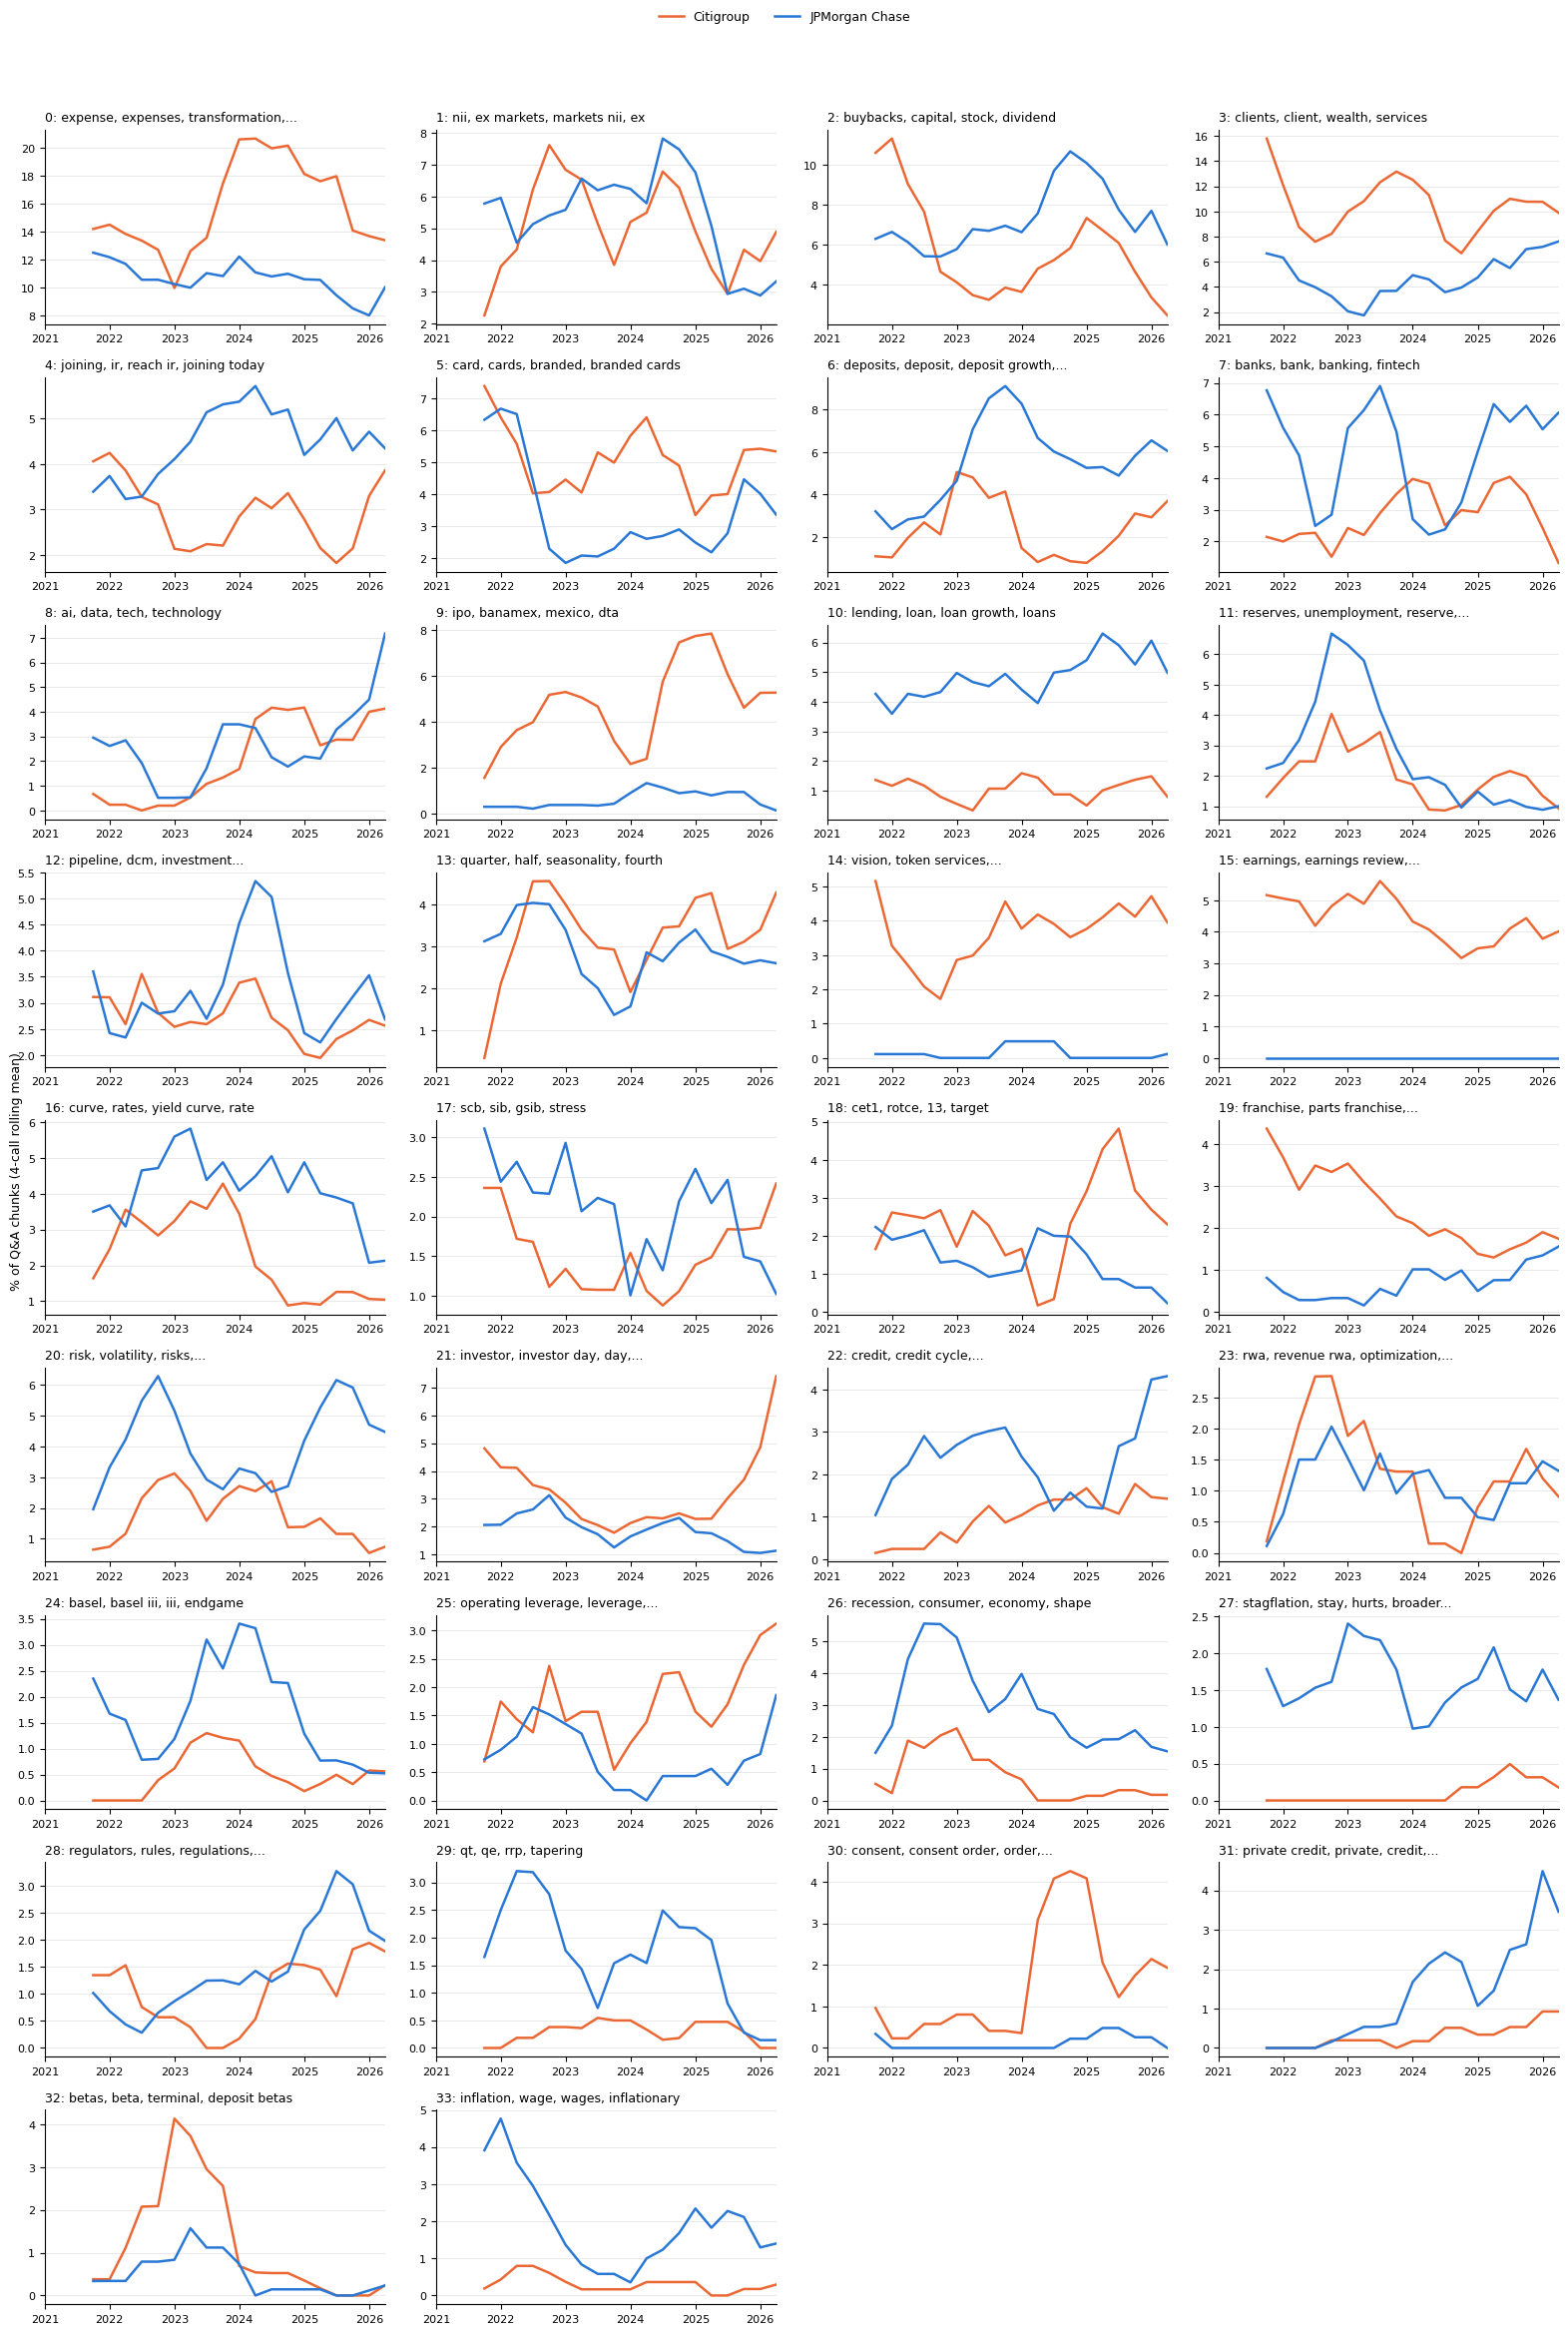

In [10]:
# ------------------------------------------------------------------
# 8.1 TOPIC TRAJECTORIES OVER TIME
# share = topic chunks / all Q&A chunks in the call x 100 (absent = 0)
# smoothed = rolling mean over ROLL_QUARTERS calls
# Mann-Kendall test (Kendall's tau vs call order), Theil-Sen slope,
# Benjamini-Hochberg q-values, and classes applied in the order of classify().
# Robustness: classes recomputed with the topics before outlier reassignment.
# ------------------------------------------------------------------
def topic_shares(df, topic_col='topic'):
    """Return one row per bank x call x topic with chunk count, share (%) and smoothed share."""
    calls = (df.groupby(['bank', 'quarter', 'announcement_date'])
               .size().rename('call_chunks').reset_index()
               .sort_values(['bank', 'announcement_date']))
    calls['t'] = calls.groupby('bank').cumcount()                  # call order within bank
    counts = (df[df[topic_col] >= 0].groupby(['bank', 'quarter', topic_col])
                .size().rename('chunks').reset_index().rename(columns={topic_col: 'topic'}))
    grid_ = (calls.merge(pd.DataFrame({'topic': TOPICS}), how='cross')
                  .merge(counts, on=['bank', 'quarter', 'topic'], how='left')
                  .fillna({'chunks': 0}))
    grid_['chunks'] = grid_['chunks'].astype(int)
    grid_['share'] = 100 * grid_['chunks'] / grid_['call_chunks']
    grid_ = grid_.sort_values(['bank', 'topic', 't']).reset_index(drop=True)
    grid_['smoothed'] = (grid_.groupby(['bank', 'topic'])['share']
                              .transform(lambda s: s.rolling(ROLL_QUARTERS, min_periods=ROLL_QUARTERS).mean()))
    grid_['topic_label'] = grid_['topic'].map(LABEL)
    return grid_


def bh_adjust(p):
    """Benjamini-Hochberg adjusted p-values; NaN where no test was run."""
    p = np.asarray(p, dtype=float)
    q = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    n = ok.sum()
    if n:
        order = np.argsort(p[ok])
        ranked = p[ok][order] * n / np.arange(1, n + 1)
        adjusted = np.minimum.accumulate(ranked[::-1])[::-1]       # keep q-values monotone
        q_ok = np.empty(n)
        q_ok[order] = np.minimum(adjusted, 1)
        q[ok] = q_ok
    return q


def classify(r):
    """Assign one trajectory to a bank x topic row (rules checked in this order)."""
    if r['chunks'] < MIN_TOPIC_CHUNKS:
        return 'insufficient data'
    significant = r['q_value'] < ALPHA
    if significant and r['tau'] > 0 and r['recent_mean'] >= RISE_RATIO * r['early_mean']:
        return 'emerging'
    if significant and r['tau'] < 0 and r['recent_mean'] <= FALL_RATIO * r['peak_smoothed']:
        return 'fading'
    if r['top2_concentration'] >= CONCENTRATION:
        return 'episodic'
    if r['presence'] >= PERSISTENCE:
        return 'persistent'
    return 'no consistent pattern'


def trend_table(shares_df):
    """Return one row per tested bank x topic with trend measures, q-value and trajectory."""
    records = []
    for (bank, topic), g in shares_df[shares_df['bank'].isin(tested_banks)].groupby(['bank', 'topic']):
        g = g.sort_values('t')
        share, t, n_chunks = g['share'].to_numpy(), g['t'].to_numpy(), g['chunks'].to_numpy()
        varies = n_chunks.sum() > 0 and np.ptp(share) > 0           # a constant series cannot be tested
        tau, p = kendalltau(t, share) if varies else (np.nan, np.nan)
        present = g[g['chunks'] > 0]
        records.append({
            'bank': bank, 'topic': topic, 'topic_label': LABEL[topic], 'chunks': int(n_chunks.sum()),
            'first_quarter': str(present['quarter'].iloc[0]) if len(present) else None,
            'peak_quarter': str(g.loc[g['share'].idxmax(), 'quarter']) if len(present) else None,
            'presence': (n_chunks > 0).mean(),
            'early_mean': share[:-RECENT_QUARTERS].mean(), 'recent_mean': share[-RECENT_QUARTERS:].mean(),
            'peak_smoothed': g['smoothed'].max(),
            'top2_concentration': np.sort(n_chunks)[-2:].sum() / n_chunks.sum() if n_chunks.sum() else np.nan,
            'tau': tau, 'p_value': p,
            'slope_pp_per_quarter': float(theilslopes(share, t)[0]) + 0.0 if varies else 0.0,
        })
    out = pd.DataFrame(records)
    out['q_value'] = bh_adjust(out['p_value'].where(out['chunks'] >= MIN_TOPIC_CHUNKS))
    out['trajectory'] = out.apply(classify, axis=1)
    return out


shares = topic_shares(corpus)
tested_banks = [b for b, n in shares.groupby('bank')['t'].max().add(1).items() if n >= MIN_QUARTERS]

trends = trend_table(shares)
trends_initial = trend_table(topic_shares(corpus, 'topic_initial'))
trends = trends.merge(trends_initial[['bank', 'topic', 'trajectory']]
                      .rename(columns={'trajectory': 'trajectory_before_reassignment'}), on=['bank', 'topic'])
trends['robust'] = trends['trajectory'].eq(trends['trajectory_before_reassignment'])

CLASS_ORDER = ['emerging', 'fading', 'episodic', 'persistent', 'no consistent pattern', 'insufficient data']
trends['trajectory'] = pd.Categorical(trends['trajectory'], CLASS_ORDER, ordered=True)
trends = trends.sort_values(['bank', 'trajectory', 'q_value']).reset_index(drop=True)

print('Number of topics per trajectory:')
display(pd.crosstab(trends['trajectory'], trends['bank']))
print(f'Same trajectory before and after outlier reassignment: {trends["robust"].mean():.0%} of bank x topic rows')
SHOW = ['bank', 'topic_label', 'trajectory', 'first_quarter', 'peak_quarter', 'chunks',
        'early_mean', 'recent_mean', 'slope_pp_per_quarter', 'tau', 'q_value', 'robust']
display(trends[SHOW].style.format({'early_mean': '{:.1f}', 'recent_mean': '{:.1f}', 'slope_pp_per_quarter': '{:+.2f}',
                                   'tau': '{:+.2f}', 'q_value': '{:.3f}'}, na_rep='–'))

# Small multiples: smoothed share per topic and bank
ncols = 4
nrows = int(np.ceil(len(TOPICS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows), squeeze=False)
x_range = (shares['quarter'].min().to_timestamp(), shares['quarter'].max().to_timestamp())
for ax, topic in zip(axes.flat, TOPICS):
    for bank in tested_banks:
        line = shares[(shares['bank'] == bank) & (shares['topic'] == topic)]
        ax.plot(line['quarter'].dt.to_timestamp(), line['smoothed'],
                color=BANK_COLOURS.get(bank, '#6b6b6b'), linewidth=1.8, label=bank)
    ax.set_title(textwrap.shorten(LABEL[topic], 40, placeholder='...'), fontsize=9, loc='left')
    ax.set_xlim(x_range)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
    ax.tick_params(labelsize=8)
for ax in list(axes.flat)[len(TOPICS):]:
    ax.set_visible(False)
fig.supylabel(f'% of Q&A chunks ({ROLL_QUARTERS}-call rolling mean)', fontsize=9)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='upper center', ncol=len(tested_banks),
           frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(OUT_DIR / 'topic_share_over_time.png', dpi=200, bbox_inches='tight')
plt.show()


**Trajectories per bank (8.1).**

| Trajectory | Citigroup | JPMorgan Chase |
|---|---|---|
| emerging | 1 | 0 |
| episodic | 2 | 0 |
| persistent | 20 | 24 |
| no consistent pattern | 8 | 7 |
| insufficient data | 3 | 3 |

- *Stable agenda:* most topics were present in at least 75% of calls at both banks.
- *Significant trend:* after Benjamini–Hochberg correction, one trend was significant: AI and technology at Citigroup increased (1.7% → 4.1% of chunks; τ = +0.55, q = 0.031; unchanged before outlier reassignment). No topic met the criteria for fading.
- *Directional tendencies (not significant after correction):*
  - *Increasing:* private credit at JPMorgan Chase (0.9% → 3.5%; τ = +0.48, q = 0.09), AI and technology at JPMorgan Chase (2.1% → 7.2%; τ = +0.28; not robust to outlier reassignment), regulation at JPMorgan Chase, and credit cycle and consent orders at Citigroup.
  - *Decreasing:* legacy franchises (τ = −0.39) and buybacks (τ = −0.26) at Citigroup; reserves/CECL, QT/QE, CET1/RoTCE targets, stress capital buffer and inflation at JPMorgan Chase (τ between −0.26 and −0.32).
- *Timing:*
  - Private credit first appeared in 4Q 2022 at both banks.
  - Peak quarters coincided across banks for deposit betas (1Q–2Q 2023) and recession (2Q 2022).
  - The Basel III endgame peaked in 2Q 2023 at Citigroup and in 1Q 2024 at JPMorgan Chase.
- *Robustness:* 72% of bank × topic trajectories were unchanged when the reassigned outlier chunks were excluded. Changes mainly affected the "persistent" class, as reassigned chunks increase the number of calls in which a topic is present.

Agenda distance between banks: mean X; trend τ = X (p = X).

Per quarter, the distance ranged from about 0.39 to 0.61, with the 4-quarter rolling mean between 0.48 and 0.55. The lowest values, around 1Q 2022, indicate quarters in which both banks' Q&A concentrated on the same subjects. The highest, around late 2022 and mid-2024, indicate quarters dominated by bank-specific subjects. Quarter-level values include sampling variation and are interpreted together with the topic shares of the quarters concerned.

In [16]:
# Which topics make the two banks' agendas differ in one quarter? (self-contained: needs sections 1-5)
from scipy.spatial.distance import jensenshannon

QUARTER = '2024Q2'                                    # change to any quarter of interest
q = pd.Period(QUARTER, 'Q')
topic_counts = (corpus[corpus['topic'] >= 0].groupby(['bank', 'quarter', 'topic']).size()
                .unstack('topic', fill_value=0).reindex(columns=TOPICS, fill_value=0))
counts_q = topic_counts.xs(q, level='quarter').loc[['Citigroup', 'JPMorgan Chase']]
distance_q = jensenshannon(counts_q.loc['Citigroup'], counts_q.loc['JPMorgan Chase'], base=2)

share_q = counts_q.div(counts_q.sum(axis=1), axis=0).mul(100).T      # % of each bank's chunks per topic
share_q.index = share_q.index.map(LABEL)
share_q['difference (pp)'] = share_q['Citigroup'] - share_q['JPMorgan Chase']
print(f'{QUARTER}: agenda distance {distance_q:.2f}')
display(share_q.reindex(share_q['difference (pp)'].abs().sort_values(ascending=False).index).head(8)
        .style.format('{:+.1f}', subset=['difference (pp)']).format('{:.1f}', subset=['Citigroup', 'JPMorgan Chase']))

2024Q2: agenda distance 0.60


bank,Citigroup,JPMorgan Chase,difference (pp)
topic,,,
"0: expense, expenses, transformation, billion",18.4,4.5,+13.9
"30: consent, consent order, order, orders",11.0,0.0,+11.0
"8: ai, data, tech, technology",9.6,0.9,+8.7
"2: buybacks, capital, stock, dividend",8.1,16.1,-8.0
"6: deposits, deposit, deposit growth, bearing",0.0,6.2,-6.2
"16: curve, rates, yield curve, rate",0.7,6.2,-5.5
"18: cet1, rotce, 13, target",0.0,5.4,-5.4
"3: clients, client, wealth, services",5.1,0.9,+4.3


### 8.2 Trajectories across banks and agenda distance

a) Trajectories by pair of banks:


,topic_label,bank_a,bank_b,trajectory_a,trajectory_b,same_trajectory,first_a,first_b,lag_quarters,spearman_rho
0,"0: expense, expenses, transformation, billion",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,+0.43
1,"1: nii, ex markets, markets nii, ex",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,+0.43
2,"2: buybacks, capital, stock, dividend",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,+0.05
3,"3: clients, client, wealth, services",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,+0.25
4,"4: joining, ir, reach ir, joining today",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,-0.32
5,"5: card, cards, branded, branded cards",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,+0.55
6,"6: deposits, deposit, deposit growth, bearing",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,+0.33
7,"7: banks, bank, banking, fintech",Citigroup,JPMorgan Chase,persistent,persistent,True,2021Q1,2021Q1,+0,-0.12
8,"8: ai, data, tech, technology",Citigroup,JPMorgan Chase,emerging,persistent,False,2021Q1,2021Q1,+0,+0.48
9,"9: ipo, banamex, mexico, dta",Citigroup,JPMorgan Chase,persistent,no consistent pattern,False,2021Q1,2021Q3,+2,+0.29


b) Shared and bank-specific topic trajectories:


,topics
pattern,
no shared pattern,16
shared,15
bank-specific,3


,topic_label,pattern
0,"0: expense, expenses, transformation, billion",shared: persistent
1,"1: nii, ex markets, markets nii, ex",shared: persistent
2,"2: buybacks, capital, stock, dividend",shared: persistent
3,"3: clients, client, wealth, services",shared: persistent
4,"4: joining, ir, reach ir, joining today",shared: persistent
5,"5: card, cards, branded, branded cards",shared: persistent
6,"6: deposits, deposit, deposit growth, bearing",shared: persistent
7,"7: banks, bank, banking, fintech",shared: persistent
8,"8: ai, data, tech, technology",bank-specific: Citigroup emerging
9,"9: ipo, banamex, mexico, dta",no shared pattern


c) Citigroup vs JPMorgan Chase: mean agenda distance 0.52 | Mann-Kendall tau -0.11, p = 0.503 | Theil-Sen slope -0.0015 per quarter


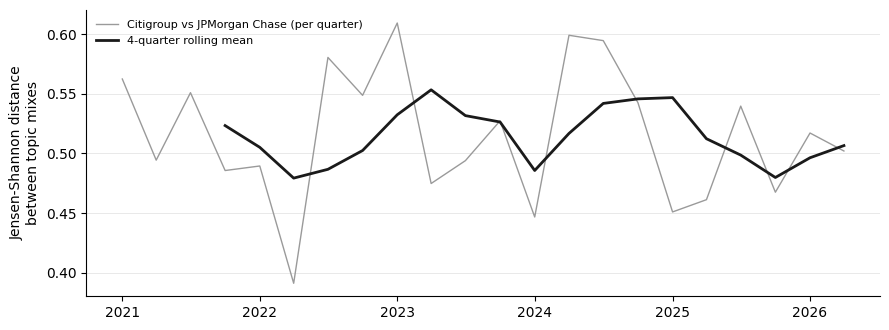

In [15]:
# ------------------------------------------------------------------
# 8.2 TRAJECTORIES ACROSS BANKS
# a) Each topic and pair of banks: trajectory at each bank, lag between
#    first appearances (quarters; positive = second bank later), and
#    Spearman correlation of the smoothed shares over common quarters
# b) Pattern per topic: 'shared' = same trajectory at every bank with a
#    full series; 'bank-specific' = emerging, fading or episodic at some
#    banks only; otherwise 'no shared pattern'
# c) Agenda distance: Jensen-Shannon distance between two banks' topic
#    mixes in each common quarter (0 = same mix, 1 = no topic in common);
#    Mann-Kendall test: falling = agendas converge, rising = diverge
# ------------------------------------------------------------------
from scipy.spatial.distance import jensenshannon
from scipy.stats import spearmanr

SIGNAL = ['emerging', 'fading', 'episodic']

pair_rows = []
for bank_a, bank_b in itertools.combinations(tested_banks, 2):
    for topic in TOPICS:
        a = trends[(trends['bank'] == bank_a) & (trends['topic'] == topic)].iloc[0]
        b = trends[(trends['bank'] == bank_b) & (trends['topic'] == topic)].iloc[0]
        lag = ((pd.Period(b['first_quarter'], 'Q') - pd.Period(a['first_quarter'], 'Q')).n
               if a['first_quarter'] and b['first_quarter'] else np.nan)
        both = (shares[shares['topic'] == topic]
                .pivot_table(index='quarter', columns='bank', values='smoothed')[[bank_a, bank_b]].dropna())
        rho = spearmanr(both[bank_a], both[bank_b])[0] if len(both) >= 3 and both.std().gt(0).all() else np.nan
        pair_rows.append({'topic_label': LABEL[topic], 'bank_a': bank_a, 'bank_b': bank_b,
                          'trajectory_a': str(a['trajectory']), 'trajectory_b': str(b['trajectory']),
                          'same_trajectory': str(a['trajectory']) == str(b['trajectory']),
                          'first_a': a['first_quarter'], 'first_b': b['first_quarter'],
                          'lag_quarters': lag, 'spearman_rho': rho})
cross_trajectories = pd.DataFrame(pair_rows)
print('a) Trajectories by pair of banks:')
display(cross_trajectories.style.format({'lag_quarters': '{:+.0f}', 'spearman_rho': '{:+.2f}'}, na_rep='–'))

pattern_rows = []
for label, g in trends.groupby('topic_label', sort=False, observed=True):
    traj = g['trajectory'].astype(str)
    if traj.nunique() == 1 and traj.iloc[0] in SIGNAL + ['persistent']:
        pattern = f'shared: {traj.iloc[0]}'
    elif traj.isin(SIGNAL).any():
        pattern = 'bank-specific: ' + '; '.join(f'{b} {t}' for b, t in zip(g['bank'], traj) if t in SIGNAL)
    else:
        pattern = 'no shared pattern'
    pattern_rows.append({'topic_label': label, 'pattern': pattern})
cross_patterns = pd.DataFrame(pattern_rows).set_index('topic_label').pipe(in_topic_order).reset_index()
print('b) Shared and bank-specific topic trajectories:')
display(cross_patterns['pattern'].str.split(':').str[0].value_counts().rename('topics').to_frame())
display(cross_patterns)

topic_counts = (corpus[corpus['topic'] >= 0].groupby(['bank', 'quarter', 'topic']).size()
                .unstack('topic', fill_value=0).reindex(columns=TOPICS, fill_value=0))
dist_rows = []
for bank_a, bank_b in itertools.combinations(tested_banks, 2):
    a_counts, b_counts = topic_counts.xs(bank_a, level='bank'), topic_counts.xs(bank_b, level='bank')
    for q in sorted(set(a_counts.index) & set(b_counts.index)):
        dist_rows.append({'pair': f'{bank_a} vs {bank_b}', 'quarter': q,
                          'agenda_distance': jensenshannon(a_counts.loc[q], b_counts.loc[q], base=2)})
agenda_distance = pd.DataFrame(dist_rows)

fig, ax = plt.subplots(figsize=(9, 3.4))
for pair, g in agenda_distance.groupby('pair'):
    g = g.sort_values('quarter')
    tau, p = kendalltau(np.arange(len(g)), g['agenda_distance'])
    slope = theilslopes(g['agenda_distance'], np.arange(len(g)))[0]
    print(f'c) {pair}: mean agenda distance {g["agenda_distance"].mean():.2f} | Mann-Kendall tau {tau:+.2f}, '
          f'p = {p:.3f} | Theil-Sen slope {slope:+.4f} per quarter')
    x = g['quarter'].dt.to_timestamp()
    ax.plot(x, g['agenda_distance'], color='#9a9a9a', linewidth=1, label=f'{pair} (per quarter)')
    ax.plot(x, g['agenda_distance'].rolling(ROLL_QUARTERS, min_periods=ROLL_QUARTERS).mean(),
            color='#1a1a1a', linewidth=2, label=f'{ROLL_QUARTERS}-quarter rolling mean')
ax.set_ylabel('Jensen-Shannon distance\nbetween topic mixes')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / 'agenda_distance.png', dpi=200, bbox_inches='tight')
plt.show()


\\\\**Trajectories across banks (8.2).**

*Co-movement of topic shares (Spearman ρ of smoothed shares, descriptive).*
- *Strong (ρ ≥ 0.6), market- and credit-related topics:* private credit (0.86), deposit betas (0.85), recession (0.68), reserves/CECL (0.67), RWA optimisation (0.63).
- *Moderate (0.4–0.6):* cards, investment-banking pipeline, inflation, AI and technology, quarterly seasonality, expenses, NII and yield curve.
- *None or negative, firm-specific topics:* CET1/RoTCE targets (−0.48), legacy franchises (−0.53), buybacks (0.05), investor day (0.06), lending (−0.22).

Topics linked to common market and credit conditions were discussed at both banks at the same time. Capital targets, capital return and restructuring followed bank-specific timing.

*Timing.*
- Private credit first appeared at both banks in 4Q 2022 and had the highest co-movement.
- The Basel III endgame (7 quarters), QT/QE (5 quarters), inflation and deposit betas (3 quarters each) appeared earlier at JPMorgan Chase.
- First appearances are based on single mentions and are interpreted together with the share trajectories.

*Trajectory classes.*
- *Counts:* 15 topics shared the same class (all persistent), 3 were classified as bank-specific (Citigroup: AI emerging; recession and private credit episodic), and 16 had no shared pattern, mainly Citigroup-specific topics and topics with too few chunks at one bank.
- *Classes and co-movement:* the classes understate shared dynamics. AI also increased at JPMorgan Chase (not significant; ρ = 0.48), and private credit and recession moved together at both banks (ρ = 0.86 and 0.68).

*Agenda distance.* The Jensen–Shannon distance between the banks' topic mixes averaged 0.52 per quarter and showed no trend (Mann–Kendall τ = −0.11, p = 0.50; Theil–Sen slope −0.0015 per quarter). The banks' agendas neither converged nor diverged over 2021–2026.

Linking it to events

Both patterns fit what happened just before these calls, in mid-July 2024. Confirm the details from the transcripts or press releases before you cite them:

Citigroup: in early July 2024, US regulators (the Federal Reserve and the OCC) fined Citi for insufficient progress on the data-management remediation required by its 2020 consent orders. That explains why consent orders, expenses and transformation, and data dominate its 2Q 2024 Q&A. It's also the same call that section 11 flagged as unusual.
JPMorgan Chase: the 2Q 2024 call came shortly after the 2024 stress test results, when banks announce dividends and buyback plans. That fits the focus on buybacks, CET1 targets and excess capital.


The largest distance occurred in 2Q 2024 (0.60).
- *Citigroup:* the Q&A concentrated on expenses and transformation (18.4% vs 4.5% at JPMorgan Chase), consent orders (11.0% vs 0.0%) and data and technology (9.6% vs 0.9%). This is consistent with the regulatory action concerning Citigroup's consent-order remediation shortly before the call.
- *JPMorgan Chase:* the Q&A concentrated on buybacks and dividends (16.1% vs 8.1%), deposits (6.2% vs 0.0%), the yield curve (6.2% vs 0.7%) and CET1/RoTCE targets (5.4% vs 0.0%), consistent with capital-return announcements following the 2024 stress tests.

The divergence therefore reflects a firm-specific regulatory agenda at Citigroup alongside capital and balance-sheet topics at JPMorgan Chase. The content of topic 8 in this quarter (AI or data remediation) is to be confirmed from the review sample.

## 9. Tone across banks
- *Scores:* FinBERT (`ProsusAI/finbert`) gives each chunk probabilities of positive, negative and neutral tone. Net tone = P(positive) − P(negative), from −1 to +1.
- *Topic and time (9.1):* mean net tone per topic for analysts and management, with 95% confidence intervals, and mean tone per call over time.
- *Between banks (9.2):* each call contributes one mean value, because chunks from the same call are not independent. Banks are compared with Welch's t-test on call means, overall and per topic and speaker type. Differences are reported with 95% confidence intervals and Benjamini–Hochberg q-values, and shown in a forest plot (dark = q < 0.05).
### 9.1 Tone per topic, speaker type and call

Loaded cached FinBERT scores (all_qa_chunk_finbert_287533bce5dacad8.parquet)
FinBERT labels (% of chunks): {'neutral': 73.7, 'positive': 17.7, 'negative': 8.6}
a) Mean net tone per topic (-1 negative ... +1 positive)


speaker_type,analyst,management,gap (management - analyst)
topic_label,,,
"0: expense, expenses, transformation, billion",+0.01,+0.15,+0.15
"1: nii, ex markets, markets nii, ex",+0.06,+0.06,-0.01
"2: buybacks, capital, stock, dividend",+0.06,+0.16,+0.10
"3: clients, client, wealth, services",+0.12,+0.31,+0.19
"4: joining, ir, reach ir, joining today",+0.08,+0.07,-0.01
"5: card, cards, branded, branded cards",+0.05,+0.21,+0.16
"6: deposits, deposit, deposit growth, bearing",+0.05,+0.14,+0.09
"7: banks, bank, banking, fintech",+0.07,+0.15,+0.08
"8: ai, data, tech, technology",+0.05,+0.17,+0.12


   95% confidence half-widths (the mean lies within +/- this value):


speaker_type,analyst,management
topic_label,,
"0: expense, expenses, transformation, billion",0.05,0.03
"1: nii, ex markets, markets nii, ex",0.06,0.06
"2: buybacks, capital, stock, dividend",0.04,0.04
"3: clients, client, wealth, services",0.04,0.03
"4: joining, ir, reach ir, joining today",0.07,0.03
"5: card, cards, branded, branded cards",0.07,0.07
"6: deposits, deposit, deposit growth, bearing",0.08,0.06
"7: banks, bank, banking, fintech",0.05,0.05
"8: ai, data, tech, technology",0.08,0.05


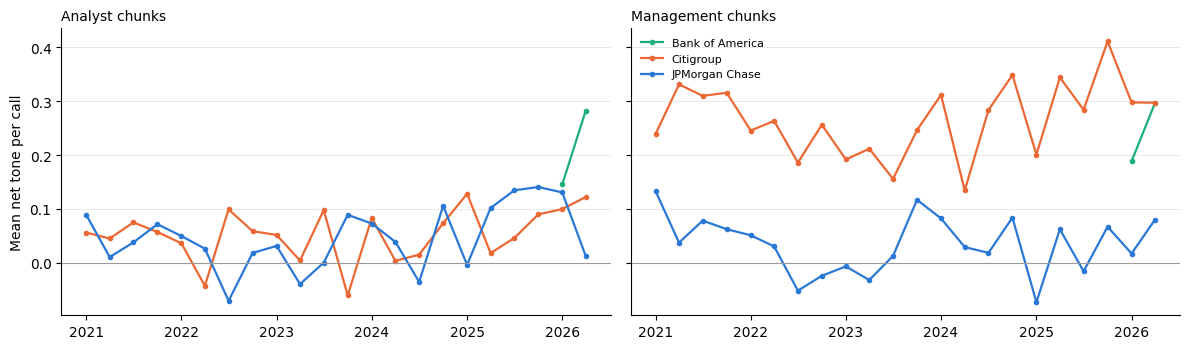

In [17]:
# ------------------------------------------------------------------
# 9.1 FINBERT TONE
# Each chunk gets P(positive), P(negative), P(neutral); scores are cached.
# net tone = P(positive) - P(negative), from -1 to +1.
# a) mean net tone per topic for analysts and management, with 95%
#    confidence intervals (mean +/- 1.96 x standard error)
# b) mean net tone per call over time, per bank and speaker type
# ------------------------------------------------------------------
tone_fp = hashlib.sha256((FINBERT_MODEL + '\n'.join(docs)).encode()).hexdigest()[:16]
tone_path = WORK_DIR / f'all_qa_chunk_finbert_{tone_fp}.parquet'

if tone_path.exists():
    probs = pd.read_parquet(tone_path)
    print(f'Loaded cached FinBERT scores ({tone_path.name})')
else:
    finbert = pipeline('text-classification', model=FINBERT_MODEL, top_k=None, truncation=True,
                       max_length=512, device=0 if DEVICE == 'cuda' else -1)
    scores = finbert(docs, batch_size=FINBERT_BATCH)                 # 3 label scores per chunk
    probs = pd.DataFrame([{s['label'].lower(): s['score'] for s in chunk} for chunk in scores])
    probs = probs[['positive', 'negative', 'neutral']]
    probs.to_parquet(tone_path, index=False)
    print(f'Scored and saved FinBERT probabilities ({tone_path.name})')

corpus[['positive', 'negative', 'neutral']] = probs[['positive', 'negative', 'neutral']].to_numpy()
corpus['net_tone'] = corpus['positive'] - corpus['negative']
corpus['finbert_label'] = probs[['positive', 'negative', 'neutral']].idxmax(axis=1).to_numpy()
print('FinBERT labels (% of chunks):', corpus['finbert_label'].value_counts(normalize=True).mul(100).round(1).to_dict())


def mean_ci(s):
    """Mean, 95% confidence half-width (1.96 x standard error) and n of a series."""
    n = s.count()
    return pd.Series({'mean': s.mean(), 'ci95': 1.96 * s.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan, 'n': n})


tone_topic = (corpus[corpus['topic'] >= 0]
              .groupby(['topic_label', 'speaker_type'])['net_tone'].apply(mean_ci).unstack())
tone_wide = tone_topic['mean'].unstack().reindex(columns=['analyst', 'management']).pipe(in_topic_order)
tone_wide['gap (management - analyst)'] = tone_wide['management'] - tone_wide['analyst']
ci_wide = tone_topic['ci95'].unstack().reindex(columns=['analyst', 'management']).pipe(in_topic_order)
print('a) Mean net tone per topic (-1 negative ... +1 positive)')
display(tone_wide.style.background_gradient(cmap='RdBu', vmin=-1, vmax=1, axis=None).format('{:+.2f}', na_rep='–'))
print('   95% confidence half-widths (the mean lies within +/- this value):')
display(ci_wide.style.format('{:.2f}', na_rep='–'))

tone_time = (corpus.groupby(['bank', 'quarter', 'speaker_type'])['net_tone'].mean()
                   .rename('net_tone').reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, speaker in zip(axes, ['analyst', 'management']):
    for bank, g in tone_time[tone_time['speaker_type'] == speaker].groupby('bank'):
        ax.plot(g['quarter'].dt.to_timestamp(), g['net_tone'], marker='o', markersize=3,
                color=BANK_COLOURS.get(bank, '#6b6b6b'), linewidth=1.6, label=bank)
    ax.axhline(0, color='#9a9a9a', linewidth=0.8)
    ax.set_title(f'{speaker.capitalize()} chunks', fontsize=10, loc='left')
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
axes[0].set_ylabel('Mean net tone per call')
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / 'tone_over_time.png', dpi=200, bbox_inches='tight')
plt.show()


**Tone per topic and speaker type (9.1).**

*Overall:* 73.7% of chunks were classified as neutral, 17.7% as positive and 8.6% as negative; mean net tone was therefore close to zero, and differences of 0.1–0.2 are substantive.

*Management more positive than analysts (gap exceeding the combined 95% confidence interval).* This applied to strategy and progress topics:
- legacy franchises (+0.17 / +0.41) and operating leverage (+0.18 / +0.40);
- clients and services (+0.12 / +0.31), investor day (+0.12 / +0.30) and token services (+0.07 / +0.30);
- earnings review (−0.01 / +0.27) and Banamex (+0.00 / +0.24);
- cards, expenses, AI and technology, and buybacks (gaps +0.10 to +0.16).

Many of these are Citigroup-specific topics associated with its transformation programme.

*Negative for both speaker types:* macroeconomic and credit-risk topics: recession (−0.13 / −0.14), QT/QE (−0.10 / −0.19), inflation, the credit cycle and reserves. This tone partly reflects the vocabulary of the subjects themselves.

*Similar tone for both:* technical and regulatory topics, including NII, the yield curve, the stress capital buffer, the Basel III endgame, regulation and consent orders.

*Risk topics:* on stagflation, private credit and deposit betas, management tone was slightly below analyst tone. These differences were not significant individually.

Confidence intervals in 9.1 are based on chunks and are therefore narrower than intervals based on calls; differences between banks are tested at call level in 9.2.

### 9.2 Differences in tone between banks

a) Mean net tone per bank (mean of call means, 95% CI half-width, number of calls):


b) Differences in mean net tone between banks (call level; tests: 53):


,comparison,speaker_type,topic_label,calls_a,calls_b,mean_a,mean_b,difference,ci_low,ci_high,p_value,q_value
23,Citigroup - JPMorgan Chase,management,all topics,22,22,+0.27,+0.03,+0.23,+0.19,+0.27,0.000,0.000
47,Citigroup - JPMorgan Chase,management,"25: operating leverage, leverage, operating, positive operating",15,13,+0.54,+0.04,+0.49,+0.31,+0.68,0.000,0.000
36,Citigroup - JPMorgan Chase,management,"12: pipeline, dcm, investment banking, ecm",20,19,+0.52,+0.07,+0.45,+0.25,+0.65,0.000,0.001
27,Citigroup - JPMorgan Chase,management,"3: clients, client, wealth, services",22,20,+0.40,+0.19,+0.21,+0.12,+0.31,0.000,0.001
31,Citigroup - JPMorgan Chase,management,"7: banks, bank, banking, fintech",17,22,+0.41,+0.06,+0.35,+0.19,+0.51,0.000,0.002
28,Citigroup - JPMorgan Chase,management,"4: joining, ir, reach ir, joining today",21,22,+0.15,+0.02,+0.13,+0.07,+0.20,0.000,0.002
24,Citigroup - JPMorgan Chase,management,"0: expense, expenses, transformation, billion",22,22,+0.21,+0.08,+0.13,+0.06,+0.19,0.000,0.002
26,Citigroup - JPMorgan Chase,management,"2: buybacks, capital, stock, dividend",22,22,+0.34,+0.07,+0.26,+0.12,+0.40,0.001,0.004
45,Citigroup - JPMorgan Chase,management,"23: rwa, revenue rwa, optimization, rwa optimization",10,13,+0.39,-0.02,+0.41,+0.19,+0.64,0.001,0.006
35,Citigroup - JPMorgan Chase,management,"11: reserves, unemployment, reserve, downside",14,19,+0.17,-0.14,+0.31,+0.12,+0.50,0.002,0.010


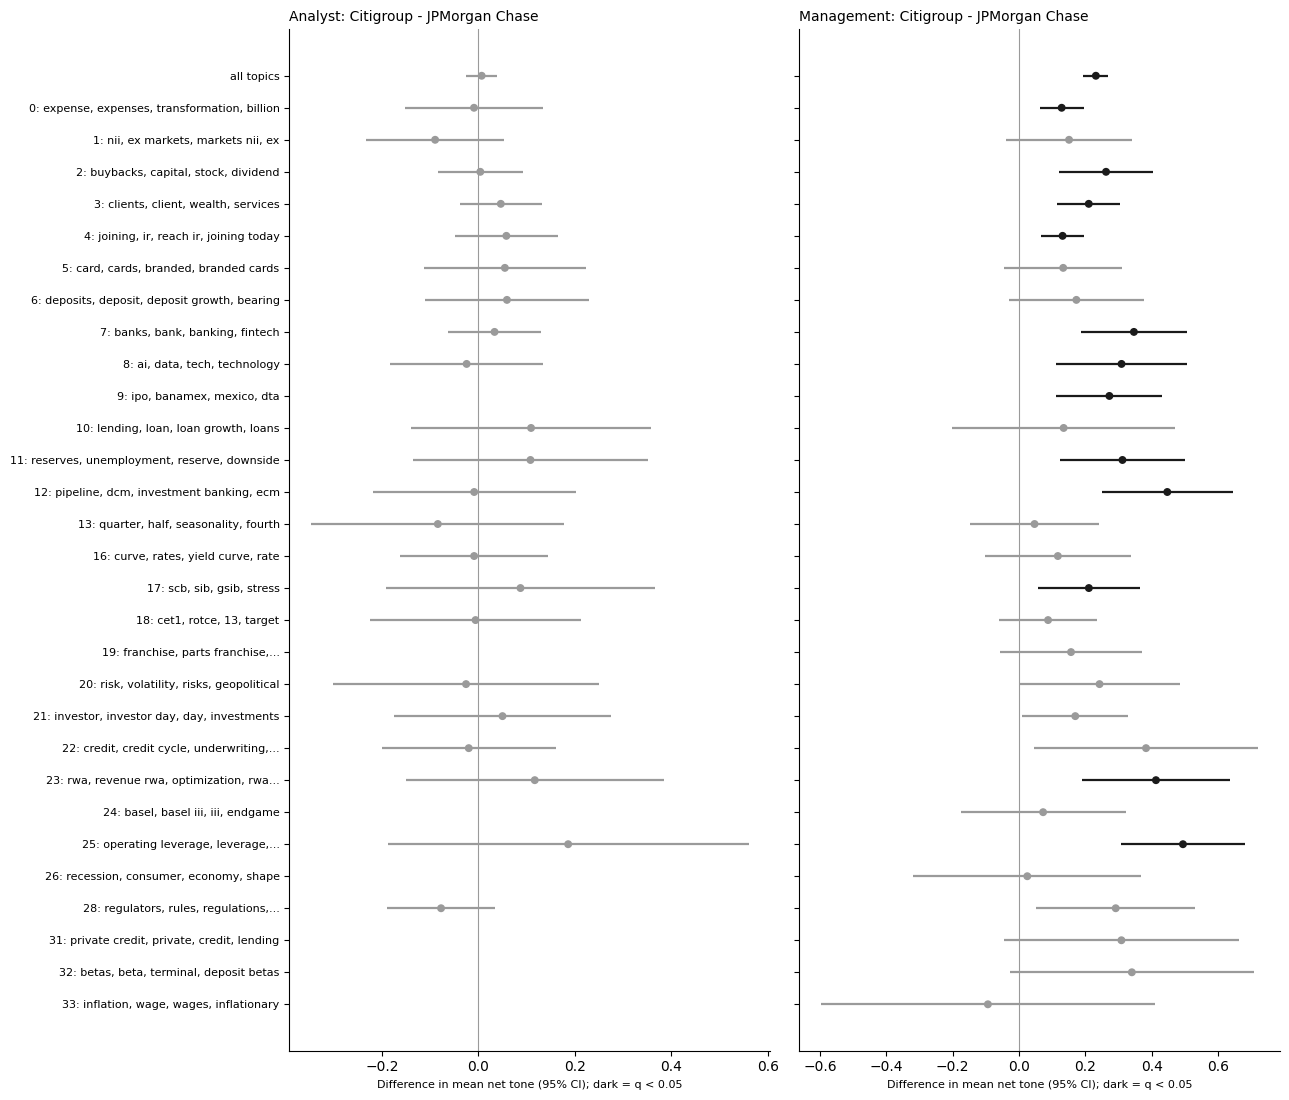

In [18]:
# ------------------------------------------------------------------
# 9.2 TONE ACROSS BANKS
# Chunks from the same call are not independent, so each call contributes
# one value: its mean net tone (per speaker type, and per topic).
# Banks are compared with Welch's t-test on these call means (no equal-
# variance assumption); differences are reported with 95% CIs and
# Benjamini-Hochberg q-values across all tests.
# a) overall tone per bank and speaker type
# b) per topic and speaker type: difference between banks (forest plot)
# ------------------------------------------------------------------
from scipy.stats import t as t_dist, ttest_ind

MIN_CALLS_TONE = 5     # a bank needs at least 5 calls with the topic for a comparison


def welch(a, b):
    """Difference in means (a - b), its 95% confidence interval and the Welch t-test p-value."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    diff = a.mean() - b.mean()
    if not se > 0:
        return diff, np.nan, np.nan, np.nan
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    half = t_dist.ppf(0.975, df) * se
    return diff, diff - half, diff + half, ttest_ind(a, b, equal_var=False).pvalue


call_tone = corpus.groupby(['bank', 'doc_id', 'speaker_type'])['net_tone'].mean().rename('net_tone').reset_index()
overall = call_tone.groupby(['bank', 'speaker_type'])['net_tone'].apply(mean_ci).unstack()
print('a) Mean net tone per bank (mean of call means, 95% CI half-width, number of calls):')
display(overall.style.format({'mean': '{:+.2f}', 'ci95': '{:.2f}', 'n': '{:.0f}'}))

call_topic_tone = (corpus[corpus['topic'] >= 0]
                   .groupby(['topic_label', 'speaker_type', 'bank', 'doc_id'])['net_tone'].mean()
                   .rename('net_tone').reset_index())
rows = []
for bank_a, bank_b in itertools.combinations(tested_banks, 2):
    for speaker in ['analyst', 'management']:
        a_all = call_tone[(call_tone['bank'] == bank_a) & (call_tone['speaker_type'] == speaker)]['net_tone']
        b_all = call_tone[(call_tone['bank'] == bank_b) & (call_tone['speaker_type'] == speaker)]['net_tone']
        tests = [('all topics', a_all, b_all)]
        for label in TOPIC_ORDER:
            g = call_topic_tone[(call_topic_tone['topic_label'] == label) & (call_topic_tone['speaker_type'] == speaker)]
            tests.append((label, g.loc[g['bank'] == bank_a, 'net_tone'], g.loc[g['bank'] == bank_b, 'net_tone']))
        for label, a, b in tests:
            if len(a) >= MIN_CALLS_TONE and len(b) >= MIN_CALLS_TONE:
                diff, lo, hi, p = welch(a, b)
                rows.append({'comparison': f'{bank_a} - {bank_b}', 'speaker_type': speaker, 'topic_label': label,
                             'calls_a': len(a), 'calls_b': len(b), 'mean_a': a.mean(), 'mean_b': b.mean(),
                             'difference': diff, 'ci_low': lo, 'ci_high': hi, 'p_value': p})
tone_differences = pd.DataFrame(rows)
if len(tone_differences):
    tone_differences['q_value'] = bh_adjust(tone_differences['p_value'])
    print(f'b) Differences in mean net tone between banks (call level; tests: {len(tone_differences)}):')
    display(tone_differences.sort_values('q_value')
            .style.format({c: '{:+.2f}' for c in ['mean_a', 'mean_b', 'difference', 'ci_low', 'ci_high']}
                          | {'p_value': '{:.3f}', 'q_value': '{:.3f}'}, na_rep='–'))

    first = tone_differences['comparison'].iloc[0]
    shown = tone_differences[tone_differences['comparison'] == first]
    order = ['all topics'] + [label for label in TOPIC_ORDER if label in set(shown['topic_label'])]
    y_of = {label: len(order) - 1 - k for k, label in enumerate(order)}      # same rows in both panels
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(order) + 1.5), sharey=True)
    for ax, speaker in zip(axes, ['analyst', 'management']):
        d = shown[shown['speaker_type'] == speaker]
        y = d['topic_label'].map(y_of).to_numpy()
        colours = np.where(d['q_value'] < ALPHA, '#1a1a1a', '#9a9a9a')
        ax.hlines(y, d['ci_low'], d['ci_high'], color=colours, linewidth=1.6)
        ax.scatter(d['difference'], y, color=colours, zorder=3, s=22)
        ax.axvline(0, color='#9a9a9a', linewidth=0.8)
        ax.set_yticks(list(y_of.values()), [textwrap.shorten(label, 45, placeholder='...') for label in y_of], fontsize=8)
        ax.set_title(f'{speaker.capitalize()}: {first}', fontsize=10, loc='left')
        ax.set_xlabel('Difference in mean net tone (95% CI); dark = q < 0.05', fontsize=8)
        ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'tone_differences_between_banks.png', dpi=200, bbox_inches='tight')
    plt.show()


**Tone across banks (9.2).** Mean net tone per call (mean of call means; 95% CI):

| Bank | Analysts | Management |
|---|---|---|
| Citigroup (22 calls) | +0.05 (±0.02) | +0.27 (±0.03) |
| JPMorgan Chase (22 calls) | +0.05 (±0.02) | +0.03 (±0.02) |
| Bank of America (2 calls, descriptive) | +0.21 (±0.13) | +0.24 (±0.11) |

*Management.* Management tone was higher at Citigroup than at JPMorgan Chase overall (difference +0.23, 95% CI +0.19 to +0.27, q < 0.001; Welch's t-test on call means, Benjamini–Hochberg correction over 53 tests).
- *Within topics:* the difference was significant in 13 topics, all in the same direction. These included operating leverage (+0.49), the investment-banking pipeline (+0.45), RWA optimisation (+0.41), banks and fintech (+0.35), reserves/CECL (+0.31; Citigroup +0.17, JPMorgan Chase −0.14), AI and technology (+0.31), Banamex (+0.27), buybacks (+0.26), clients and services (+0.21), the stress capital buffer (+0.21) and expenses (+0.13).

*Analysts.* Analyst tone did not differ between the banks, overall (+0.01, q = 0.83) or in any topic (all q ≥ 0.32).

*Interpretation.*
- *Source of the difference:* the gap lies in management's answers, not in analysts' questions.
- *Not a topic-mix effect:* the difference persists within topics, including topics unrelated to Citigroup's strategy (reserves, stress capital buffer).
- *Possible explanations:* differences in communication style between the management teams, including Citigroup's emphasis on progress against its transformation targets and more cautious language at JPMorgan Chase on the economic and credit outlook; the speaking styles of individual executives may also contribute.
- *Measurement note:* part of the difference in the operating-leverage topic reflects the phrase "positive operating leverage", which FinBERT scores as positive.

## 10. Themes
- *Grouping:* topics are grouped into broader themes with the same hierarchy as in 6.1. Topics are compared by their c-TF-IDF word profiles (distance = 1 − cosine similarity), joined with Ward linkage, and the tree is cut into five themes.
- *Review:* the grouping reflects shared vocabulary rather than meaning, so it is reviewed. After the first run, read the printed mapping, then name the themes, move topics or exclude non-substantive topics (for example, call openings by investor relations) in the settings at the top of 10.1, and re-run 10.1–10.2. These decisions are reported with the results.
- *Measures:* the measures of sections 7–9 are applied to themes, including the test of 7.2.
### 10.1 Themes from the topic hierarchy

In [24]:
# ------------------------------------------------------------------
# 10.1 THEMES: GROUP TOPICS USING THE TOPIC HIERARCHY
# Requires sections 1-9 in this session.
# - Same hierarchy as 6.1 c): topics compared by their c-TF-IDF words
#   (1 - cosine similarity), joined with Ward linkage.
# - The tree is cut into N_THEMES groups, so every topic belongs to one theme.
# - After reading the printed mapping, the researcher can:
#     name the themes            -> THEME_NAMES
#     move a topic to a theme    -> THEME_OVERRIDES
#     exclude procedural topics  -> EXCLUDE_TOPICS (e.g. call openings by investor relations)
#   and re-run 10.1-10.2. Topic numbers stay the same as long as the
#   settings in 1.1-5.1 are unchanged.
# ------------------------------------------------------------------
from collections import Counter

import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform
from sklearn.metrics.pairwise import cosine_similarity
N_THEMES        = 5
THEME_NAMES     = {1: 'Balance sheet, NII and revenue outlook',
                   2: 'Credit and macroeconomic risk',
                   3: 'Strategy, costs and franchise',
                   4: 'Regulatory remediation and regulation',
                   5: 'Capital: requirements and return',
                   6: 'Technology and digital'}
THEME_OVERRIDES = {2: 5,              # buybacks/dividends -> capital (with CET1, SCB, Basel, RWA)
                   7: 6, 8: 6, 14: 6} # banks/fintech, AI/data/tech, token services -> new technology theme
EXCLUDE_TOPICS  = [4]                 # call administration ('reach IR', 'joining today')

needed = ['topic_model', 'corpus', 'TOPICS', 'LABEL', 'tested_banks', 'classify', 'bh_adjust',
          'mean_ci', 'OUT_DIR', 'BANK_COLOURS', 'ROLL_QUARTERS', 'RECENT_QUARTERS', 'MIN_TOPIC_CHUNKS']
missing = [name for name in needed if name not in globals()]
assert not missing and 'net_tone' in corpus, f'Run sections 1-9 first. Missing: {missing or ["net_tone"]}'

# c-TF-IDF rows of the topics (the outlier row, if present, comes first and is skipped)
ctfidf = topic_model.c_tf_idf_
offset = ctfidf.shape[0] - len(TOPICS)
assert offset in (0, 1), 'Topic rows and topic list do not match: re-run 5.1'
distance = 1 - cosine_similarity(ctfidf[offset:])
distance = np.clip((distance + distance.T) / 2, 0, None)          # exactly symmetric, no negative rounding
np.fill_diagonal(distance, 0)
linkage = sch.linkage(squareform(distance, checks=False), 'ward', optimal_ordering=True)
theme_of = dict(zip(TOPICS, sch.fcluster(linkage, t=N_THEMES, criterion='maxclust').astype(int)))
theme_of.update(THEME_OVERRIDES)
for t in EXCLUDE_TOPICS:
    theme_of.pop(t, None)

THEME_IDS = sorted(set(theme_of.values()))


def theme_words(theme, n=5):
    """Most characteristic words of a theme: c-TF-IDF scores summed over its topics."""
    scores = Counter()
    for t, th in theme_of.items():
        if th == theme:
            for w, s in topic_model.get_topic(t)[:10]:
                if w:
                    scores[w] += s
    return ', '.join(w for w, _ in scores.most_common(n))


THEME_LABEL = {th: THEME_NAMES.get(th, f'Theme {th}: {theme_words(th)}') for th in THEME_IDS}
corpus['theme'] = corpus['topic'].map(theme_of).fillna(-1).astype(int)       # outliers/excluded -> -1
corpus['theme_label'] = corpus['theme'].map(THEME_LABEL).fillna('outliers or excluded')

mapping = (pd.DataFrame({'topic': list(theme_of), 'theme': list(theme_of.values())})
             .assign(theme_label=lambda d: d['theme'].map(THEME_LABEL),
                     topic_label=lambda d: d['topic'].map(LABEL),
                     chunks=lambda d: d['topic'].map(corpus['topic'].value_counts()).fillna(0).astype(int))
             .sort_values(['theme', 'topic']).reset_index(drop=True))
print(f'{len(THEME_IDS)} themes from {len(theme_of)} topics'
      + (f' ({len(EXCLUDE_TOPICS)} topics excluded: {EXCLUDE_TOPICS})' if EXCLUDE_TOPICS else ''))
for th, g in mapping.groupby('theme'):
    print(f'\n{THEME_LABEL[th]}  [{g["chunks"].sum():,} chunks]')
    for r in g.itertuples(index=False):
        print(f'   {r.topic_label}  ({r.chunks})')


6 themes from 33 topics (1 topics excluded: [4])

Balance sheet, NII and revenue outlook  [1,904 chunks]
   1: nii, ex markets, markets nii, ex  (365)
   5: card, cards, branded, branded cards  (291)
   6: deposits, deposit, deposit growth, bearing  (278)
   10: lending, loan, loan growth, loans  (214)
   12: pipeline, dcm, investment banking, ecm  (213)
   13: quarter, half, seasonality, fourth  (236)
   16: curve, rates, yield curve, rate  (204)
   29: qt, qe, rrp, tapering  (58)
   32: betas, beta, terminal, deposit betas  (45)

Credit and macroeconomic risk  [805 chunks]
   11: reserves, unemployment, reserve, downside  (152)
   20: risk, volatility, risks, geopolitical  (203)
   22: credit, credit cycle, underwriting, consumer credit  (120)
   26: recession, consumer, economy, shape  (118)
   27: stagflation, stay, hurts, broader market  (61)
   31: private credit, private, credit, lending  (64)
   33: inflation, wage, wages, inflationary  (87)

Strategy, costs and franchise  [2,1

6 themes were identified from 33 topics

### 10.2 Themes by bank, over time and in tone

a) % of each bank's Q&A chunks per theme:


bank,Bank of America,Citigroup,JPMorgan Chase
theme_label,,,
"Balance sheet, NII and revenue outlook",42.7,22.6,30.5
Credit and macroeconomic risk,11.9,6.0,16.6
"Strategy, costs and franchise",22.7,43.3,20.6
Regulatory remediation and regulation,1.0,2.7,1.7
Capital: requirements and return,6.6,11.0,13.1
Technology and digital,11.2,8.7,8.7
outliers or excluded,3.8,5.7,8.9


   Share of analyst questions per theme (all chunks: 29%):


,chunks,pct_questions
theme_label,,
"Balance sheet, NII and revenue outlook",1904,36
Credit and macroeconomic risk,805,27
"Strategy, costs and franchise",2154,22
Regulatory remediation and regulation,146,37
Capital: requirements and return,824,34
Technology and digital,609,27


b) Theme trajectories (same rules as 8.1):


,bank,theme_label,trajectory,first_quarter,peak_quarter,chunks,early_mean,recent_mean,slope_pp_per_quarter,tau,q_value
0,Citigroup,"Balance sheet, NII and revenue outlook",persistent,2021Q1,2023Q1,715,22.8,22.9,+0.08,+0.02,0.994
1,Citigroup,Credit and macroeconomic risk,persistent,2021Q1,2022Q4,188,6.2,4.7,-0.05,-0.06,0.984
2,Citigroup,"Strategy, costs and franchise",persistent,2021Q1,2024Q4,1367,42.9,44.9,+0.01,+0.00,1.000
3,Citigroup,Regulatory remediation and regulation,persistent,2021Q1,2024Q2,85,2.4,3.7,+0.11,+0.23,0.419
4,Citigroup,Capital: requirements and return,persistent,2021Q1,2021Q2,347,11.8,8.6,-0.18,-0.11,0.755
5,Citigroup,Technology and digital,persistent,2021Q1,2023Q3,274,8.2,9.4,+0.25,+0.28,0.419
6,JPMorgan Chase,"Balance sheet, NII and revenue outlook",persistent,2021Q1,2023Q2,1067,32.3,25.5,-0.33,-0.24,0.419
7,JPMorgan Chase,Credit and macroeconomic risk,persistent,2021Q1,2022Q3,583,16.5,17.6,-0.17,-0.12,0.736
8,JPMorgan Chase,"Strategy, costs and franchise",persistent,2021Q1,2026Q2,722,19.6,22.3,+0.06,+0.03,0.994
9,JPMorgan Chase,Regulatory remediation and regulation,persistent,2021Q1,2025Q1,58,1.6,2.0,+0.08,+0.31,0.419


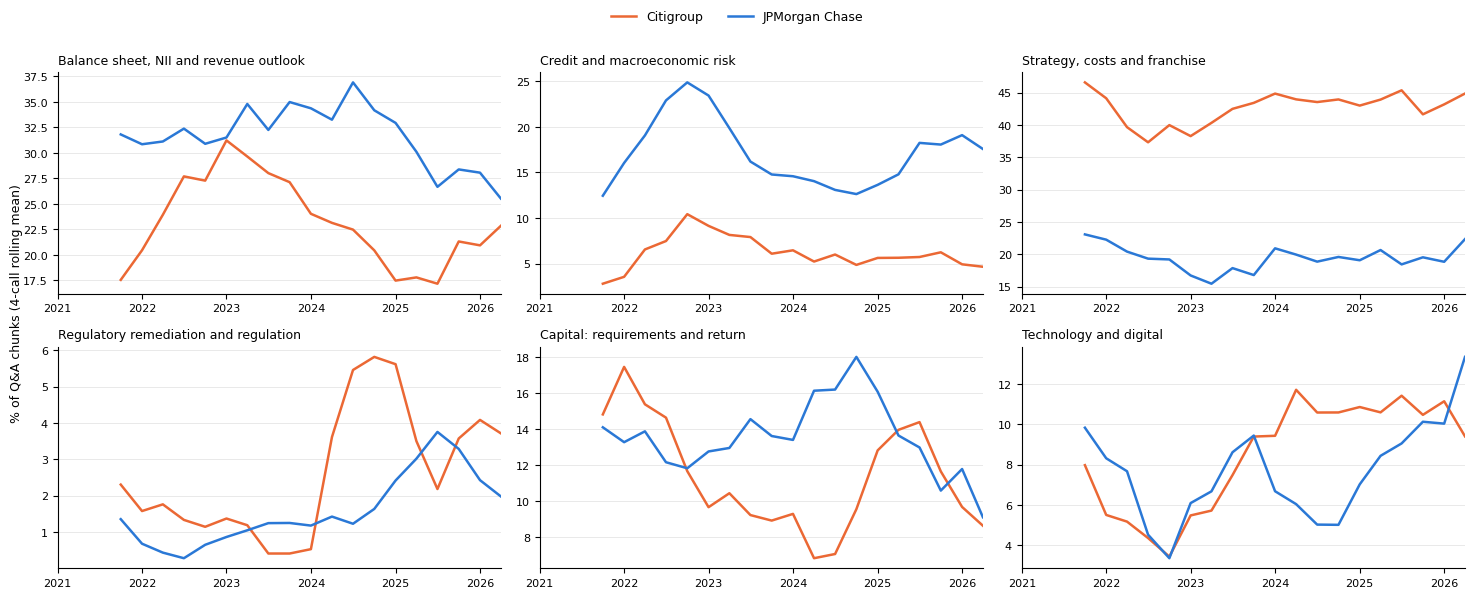

c) Mean net tone per theme (-1 negative ... +1 positive) and 95% confidence half-widths:


speaker_type,analyst,management,gap (management - analyst)
theme_label,,,
"Balance sheet, NII and revenue outlook",+0.06,+0.11,+0.06
Credit and macroeconomic risk,+0.00,-0.03,-0.03
"Strategy, costs and franchise",+0.06,+0.25,+0.19
Regulatory remediation and regulation,+0.03,+0.05,+0.02
Capital: requirements and return,+0.09,+0.16,+0.07
Technology and digital,+0.07,+0.18,+0.11


speaker_type,analyst,management
theme_label,,
"Balance sheet, NII and revenue outlook",0.03,0.03
Credit and macroeconomic risk,0.04,0.03
"Strategy, costs and franchise",0.03,0.02
Regulatory remediation and regulation,0.04,0.05
Capital: requirements and return,0.03,0.03
Technology and digital,0.04,0.03


   Bank of America: mean net tone per theme and year


year,2026
theme_label,
"Balance sheet, NII and revenue outlook",+0.21
Credit and macroeconomic risk,+0.17
"Strategy, costs and franchise",+0.29
Regulatory remediation and regulation,+0.02
Capital: requirements and return,+0.35
Technology and digital,+0.17


...

year,2021,2022,2023,2024,2025,2026
theme_label,,,,,,
"Balance sheet, NII and revenue outlook",+0.06,-0.01,+0.01,-0.01,+0.04,+0.11
Credit and macroeconomic risk,+0.03,-0.06,-0.11,-0.02,-0.11,-0.08
"Strategy, costs and franchise",+0.12,+0.10,+0.08,+0.10,+0.14,+0.14
Regulatory remediation and regulation,-0.12,+0.02,-0.01,+0.07,+0.01,+0.03
Capital: requirements and return,+0.11,+0.09,+0.05,+0.12,+0.04,+0.04
Technology and digital,+0.05,-0.01,+0.08,+0.13,+0.07,+0.04


d) Themes, Citigroup vs JPMorgan Chase: 22 common quarters | chi2 = 486.0, df = 5, p = 8.4e-103 | Cramer's V = 0.28 | critical |residual| = 2.87


bank,Citigroup,JPMorgan Chase
theme_label,,
"Balance sheet, NII and revenue outlook",24.0,33.4
Credit and macroeconomic risk,6.3,18.3
"Strategy, costs and franchise",45.9,22.6
Regulatory remediation and regulation,2.9,1.8
Capital: requirements and return,11.7,14.4
Technology and digital,9.2,9.5


bank,Citigroup,JPMorgan Chase
theme_label,,
"Balance sheet, NII and revenue outlook",-8.1,+8.1
Credit and macroeconomic risk,-14.2,+14.2
"Strategy, costs and franchise",+19.3,-19.3
Regulatory remediation and regulation,+2.7,-2.7
Capital: requirements and return,-3.1,+3.1
Technology and digital,-0.4,+0.4


   More than expected at Citigroup: Strategy, costs and franchise
   More than expected at JPMorgan Chase: Balance sheet, NII and revenue outlook; Credit and macroeconomic risk; Capital: requirements and return


In [25]:
# ------------------------------------------------------------------
# 10.2 THEMES BY BANK, OVER TIME AND IN TONE
# Same measures as for topics (7.1-9.1), applied to themes:
# a) % of each bank's chunks per theme and % of theme chunks that are questions
# b) share per call, trend test, trajectory class, and chart
# c) mean net tone per theme for analysts and management (95% CI),
#    and mean net tone per theme and year for each bank
# d) themes distinctive for each bank (test of 7.2)
# ------------------------------------------------------------------
def shares_by(df, col, ids, labels):
    """One row per bank x call x group (topic or theme): chunks, share (%) and smoothed share."""
    calls_ = (df.groupby(['bank', 'quarter', 'announcement_date']).size().rename('call_chunks').reset_index()
                .sort_values(['bank', 'announcement_date']))
    calls_['t'] = calls_.groupby('bank').cumcount()
    counts_ = (df[df[col].isin(ids)].groupby(['bank', 'quarter', col]).size().rename('chunks')
                 .reset_index().rename(columns={col: 'group'}))
    g = (calls_.merge(pd.DataFrame({'group': ids}), how='cross')
               .merge(counts_, on=['bank', 'quarter', 'group'], how='left').fillna({'chunks': 0}))
    g['chunks'] = g['chunks'].astype(int)
    g['share'] = 100 * g['chunks'] / g['call_chunks']
    g = g.sort_values(['bank', 'group', 't']).reset_index(drop=True)
    g['smoothed'] = (g.groupby(['bank', 'group'])['share']
                      .transform(lambda s: s.rolling(ROLL_QUARTERS, min_periods=ROLL_QUARTERS).mean()))
    g['label'] = g['group'].map(labels)
    return g


def trends_by(shares_df, labels):
    """Trend measures, q-values and trajectory per tested bank x group (same rules as 8.1)."""
    records = []
    for (bank, group), g in shares_df[shares_df['bank'].isin(tested_banks)].groupby(['bank', 'group']):
        g = g.sort_values('t')
        share, t, n_chunks = g['share'].to_numpy(), g['t'].to_numpy(), g['chunks'].to_numpy()
        varies = n_chunks.sum() > 0 and np.ptp(share) > 0
        tau, p = kendalltau(t, share) if varies else (np.nan, np.nan)
        present = g[g['chunks'] > 0]
        records.append({
            'bank': bank, 'group': group, 'label': labels[group], 'chunks': int(n_chunks.sum()),
            'first_quarter': str(present['quarter'].iloc[0]) if len(present) else None,
            'peak_quarter': str(g.loc[g['share'].idxmax(), 'quarter']) if len(present) else None,
            'presence': (n_chunks > 0).mean(),
            'early_mean': share[:-RECENT_QUARTERS].mean(), 'recent_mean': share[-RECENT_QUARTERS:].mean(),
            'peak_smoothed': g['smoothed'].max(),
            'top2_concentration': np.sort(n_chunks)[-2:].sum() / n_chunks.sum() if n_chunks.sum() else np.nan,
            'tau': tau, 'p_value': p,
            'slope_pp_per_quarter': float(theilslopes(share, t)[0]) + 0.0 if varies else 0.0,
        })
    out = pd.DataFrame(records)
    out['q_value'] = bh_adjust(out['p_value'].where(out['chunks'] >= MIN_TOPIC_CHUNKS))
    out['trajectory'] = out.apply(classify, axis=1)
    return out


in_theme = corpus[corpus['theme'] >= 0]

# a) Themes by bank and speaker type
theme_by_bank = (pd.crosstab(corpus['theme_label'], corpus['bank'], normalize='columns').mul(100)
                   .reindex([THEME_LABEL[th] for th in THEME_IDS] + ['outliers or excluded']).dropna(how='all'))
theme_by_role = (in_theme.groupby('theme_label')
                 .agg(chunks=('text', 'size'), pct_questions=('role', lambda s: 100 * s.eq('question').mean()))
                 .reindex([THEME_LABEL[th] for th in THEME_IDS]))
print("a) % of each bank's Q&A chunks per theme:")
display(theme_by_bank.style.background_gradient(cmap='Blues', axis=None).format('{:.1f}'))
print(f'   Share of analyst questions per theme (all chunks: {corpus["role"].eq("question").mean():.0%}):')
display(theme_by_role.style.format({'pct_questions': '{:.0f}'}))

# b) Trajectories
theme_shares = shares_by(corpus, 'theme', THEME_IDS, THEME_LABEL)
theme_trends = trends_by(theme_shares, THEME_LABEL).rename(columns={'group': 'theme', 'label': 'theme_label'})
print('b) Theme trajectories (same rules as 8.1):')
display(theme_trends[['bank', 'theme_label', 'trajectory', 'first_quarter', 'peak_quarter', 'chunks', 'early_mean',
                      'recent_mean', 'slope_pp_per_quarter', 'tau', 'q_value']]
        .style.format({'early_mean': '{:.1f}', 'recent_mean': '{:.1f}', 'slope_pp_per_quarter': '{:+.2f}',
                       'tau': '{:+.2f}', 'q_value': '{:.3f}'}, na_rep='–'))

ncols = min(3, len(THEME_IDS))
nrows = int(np.ceil(len(THEME_IDS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows), squeeze=False)
x_range = (theme_shares['quarter'].min().to_timestamp(), theme_shares['quarter'].max().to_timestamp())
for ax, th in zip(axes.flat, THEME_IDS):
    for bank in tested_banks:
        line = theme_shares[(theme_shares['bank'] == bank) & (theme_shares['group'] == th)]
        ax.plot(line['quarter'].dt.to_timestamp(), line['smoothed'], color=BANK_COLOURS.get(bank, '#6b6b6b'),
                linewidth=1.8, label=bank)
    ax.set_title(textwrap.fill(THEME_LABEL[th], 45), fontsize=9, loc='left')
    ax.set_xlim(x_range)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
    ax.tick_params(labelsize=8)
for ax in list(axes.flat)[len(THEME_IDS):]:
    ax.set_visible(False)
fig.supylabel(f'% of Q&A chunks ({ROLL_QUARTERS}-call rolling mean)', fontsize=9)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='upper center', ncol=len(tested_banks),
           frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(OUT_DIR / 'theme_share_over_time.png', dpi=200, bbox_inches='tight')
plt.show()

# c) Tone
theme_tone = in_theme.groupby(['theme_label', 'speaker_type'])['net_tone'].apply(mean_ci).unstack()
theme_tone_wide = (theme_tone['mean'].unstack().reindex(columns=['analyst', 'management'])
                   .reindex([THEME_LABEL[th] for th in THEME_IDS]))
theme_tone_wide['gap (management - analyst)'] = theme_tone_wide['management'] - theme_tone_wide['analyst']
theme_ci_wide = (theme_tone['ci95'].unstack().reindex(columns=['analyst', 'management'])
                 .reindex([THEME_LABEL[th] for th in THEME_IDS]))
print('c) Mean net tone per theme (-1 negative ... +1 positive) and 95% confidence half-widths:')
display(theme_tone_wide.style.background_gradient(cmap='RdBu', vmin=-1, vmax=1, axis=None)
                       .format('{:+.2f}', na_rep='–'))
display(theme_ci_wide.style.format('{:.2f}', na_rep='–'))

theme_tone_year = (in_theme.assign(year=in_theme['quarter'].dt.year)
                   .groupby(['bank', 'theme_label', 'year'])['net_tone'].mean().rename('net_tone').reset_index())
for bank, g in theme_tone_year.groupby('bank'):
    table = (g.pivot_table(index='theme_label', columns='year', values='net_tone')
              .reindex([THEME_LABEL[th] for th in THEME_IDS]).dropna(how='all'))
    print(f'   {bank}: mean net tone per theme and year')
    display(table.style.background_gradient(cmap='RdBu', vmin=-1, vmax=1, axis=None).format('{:+.2f}', na_rep='–'))

# d) Which themes are distinctive for each bank? (same test as 7.2)
prevalence_themes = prevalence_test(corpus, 'theme', [THEME_LABEL[th] for th in THEME_IDS], full_banks)
show_prevalence(prevalence_themes, f'd) Themes, {" vs ".join(full_banks)}')


**Themes (10).**

*Theme definition.*
- *Grouping:* the 34 topics were grouped by cutting the topic hierarchy into five themes and then adjusting the grouping after review.
- *Excluded:* call administration (topic 4: "joining, IR, reach IR"; 249 chunks), which is not a subject of discussion.
- *Moved:* buybacks and dividends (topic 2) to the capital theme, so that capital requirements and capital return form one theme.
- *New theme:* banks and fintech, AI and technology, and token services (topics 7, 8, 14) were separated from strategy as a technology theme.

| Theme | Topics | Chunks |
|---|---|---|
| Balance sheet, NII and revenue outlook | deposits, NII, yield curve, QT, deposit betas, cards, lending, IB pipeline, quarterly seasonality | 1,904 |
| Credit and macroeconomic risk | reserves, risk/geopolitics, credit cycle, recession, stagflation, private credit, inflation | 805 |
| Strategy, costs and franchise | expenses, clients/services, Banamex, earnings review, legacy franchises, investor day, operating leverage | 2,154 |
| Regulatory remediation and regulation | consent orders, regulation | 146 |
| Capital: requirements and return | buybacks, stress capital buffer, CET1/RoTCE targets, RWA, Basel III endgame | 824 |
| Technology and digital | banks/fintech, AI and technology, token services | 609 |

*Prevalence (22 common quarters; χ² = 486.0, df = 5, Cramér's V = 0.28).*
- *Citigroup:* strategy, costs and franchise was more frequent (45.9% vs 22.6%; residual +19.3).
- *JPMorgan Chase:* credit and macroeconomic risk (18.3% vs 6.3%; +14.2), the balance sheet (33.4% vs 24.0%; +8.1) and capital (14.4% vs 11.7%; +3.1) were more frequent.
- *No significant difference:* technology (9.5% vs 9.2%) and regulation.
- *Analysts vs management:* regulation, the balance sheet and capital were raised mainly in analyst questions (34–37% question chunks); strategy was developed mainly in management answers (22%).

*Trajectories.* No theme showed a significant trend (all q ≥ 0.42).
- *Tendencies:* technology increased at both banks (Citigroup 8.2% → 9.4%, τ = +0.28; JPMorgan Chase 7.1% → 13.3%, τ = +0.17). Capital decreased at both banks (τ = −0.11 and −0.20). The balance sheet decreased at JPMorgan Chase (32.3% → 25.5%, τ = −0.24).
- *Stability:* Citigroup's strategy theme was stable over the whole period (τ = 0.00).
- *Peaks:* the balance-sheet theme peaked in 1Q–2Q 2023 and the credit theme in 3Q–4Q 2022 at both banks; regulation at Citigroup peaked in 2Q 2024.

*Tone.*
- *Management vs analysts:* management tone exceeded analyst tone for strategy (+0.19), technology (+0.11), capital (+0.07) and the balance sheet (+0.06). It did not differ for regulation (+0.02) or credit and macroeconomic risk (−0.03).
- *Citigroup by year:* tone was positive in every theme and almost every year. The exceptions were credit and macroeconomic risk in 2022 (−0.08) and regulation in 2024 (+0.02).
- *JPMorgan Chase by year:* tone on credit and macroeconomic risk was negative in every year from 2022 to 2026 (−0.02 to −0.11).

*Shape of the trajectories (4-call rolling means).*
- *Shared turning points:* the credit and macroeconomic risk theme peaked at both banks in late 2022, at different levels (about 25% at JPMorgan Chase, about 10% at Citigroup). The balance-sheet theme converged at about 31% at both banks in early 2023. Technology reached its lowest share at both banks in early 2023 and increased thereafter.
- *Stable bank profiles:* the strategy theme remained 20–25 percentage points higher at Citigroup, and credit higher at JPMorgan Chase, throughout the period.
- *Bank-specific episodes:* regulation at Citigroup (2024), capital at Citigroup (2022) and JPMorgan Chase (late 2024), and credit at JPMorgan Chase (2025–26).
- *Reading the series:* the theme series consist mainly of episodes lasting a few quarters rather than monotonic trends, which is consistent with the absence of significant Mann–Kendall trends. Because of the rolling window, peaks lag the underlying calls by up to three quarters.

## 11. Unusual calls
Each bank is compared with its own history; banks with fewer than eight calls are excluded.
- **Method A, departure from the previous four calls (11.2).**
  - *Topic novelty:* the Jensen–Shannon distance between the call's topic mix and the pooled mix of the previous four calls.
  - *Tone change:* the change in mean analyst and management tone against the previous four calls.
  - *Flag:* modified z-scores within the bank, flagged above 3.5 in absolute value (Iglewicz and Hoaglin, 1993).
- **Method B, Isolation Forest (11.3).**
  - *Features:* the centred log-ratio of topic proportions (pseudocount 0.5), reduced to three principal components, plus mean analyst and management tone.
  - *Model:* 500 trees, with scores averaged over five seeds.
  - *Flag:* the top 10% of each bank's calls.
- **Explanation and cross-bank view (11.4).** The topics that rose and fell in each flagged call, a sample of chunks to read, the quarters in which several banks have flagged calls, and the correlation of topic novelty between banks.

A flag is a statistical signal. Its explanation is established by reading the sample and checking external events.
### 11.1 Settings and call-level features

In [26]:
# ------------------------------------------------------------------
# 11.1 UNUSUAL CALLS - SETTINGS AND CALL-LEVEL FEATURES
# Requires sections 1-9 in this session (corpus with topics and tone,
# shares, TOPICS, LABEL, tested_banks). Each call is described by:
#   - its topic mix: chunks per topic (outliers excluded)
#   - its tone: mean net tone of analyst chunks and of management chunks
# Banks with fewer than MIN_QUARTERS calls (BAC) are excluded.
# ------------------------------------------------------------------
from scipy.spatial.distance import jensenshannon
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

BASELINE_CALLS = 4        # 'recent average' = the bank's previous 4 calls (one year)
MZ_THRESHOLD   = 3.5      # modified z-score above which a value counts as unusual (Iglewicz & Hoaglin)
PCA_COMPONENTS = 3        # topic-mix dimensions given to the Isolation Forest
PSEUDOCOUNT    = 0.5      # added to every topic count before taking logs (log 0 is undefined)
IF_SEEDS       = [0, 1, 2, 3, 4]   # Isolation Forest is random: scores are averaged over 5 seeds
IF_SHARE       = 0.10     # share of each bank's calls flagged by the Isolation Forest (top-ranked)

needed = ['corpus', 'shares', 'TOPICS', 'LABEL', 'tested_banks', 'OUT_DIR', 'SEED', 'BANK_COLOURS']
missing = [name for name in needed if name not in globals()]
assert not missing and 'net_tone' in corpus, f'Run sections 1-9 first. Missing: {missing or ["net_tone"]}'

# Topic counts: one row per bank x call, one column per topic, in date order
counts = (shares[shares['bank'].isin(tested_banks)]
          .pivot_table(index=['bank', 'quarter'], columns='topic', values='chunks', aggfunc='sum')
          .reindex(columns=TOPICS, fill_value=0)
          .sort_index())

tone_call = (corpus[corpus['bank'].isin(tested_banks)]
             .pivot_table(index=['bank', 'quarter'], columns='speaker_type', values='net_tone', aggfunc='mean')
             .reindex(columns=['analyst', 'management'])
             .add_prefix('tone_'))
period_of = corpus.drop_duplicates(['bank', 'quarter']).set_index(['bank', 'quarter'])['reporting_period']

calls = (counts.sum(axis=1).rename('assigned_chunks').to_frame()
               .join(tone_call)
               .assign(reporting_period=lambda d: d.index.map(period_of)))
print(f'{len(calls)} calls from {len(tested_banks)} banks; {len(TOPICS)} topics per call')
display(calls.groupby(level='bank').agg(calls=('assigned_chunks', 'size'),
                                        median_chunks=('assigned_chunks', 'median'),
                                        mean_tone_analyst=('tone_analyst', 'mean'),
                                        mean_tone_management=('tone_management', 'mean')).round(2))


44 calls from 2 banks; 34 topics per call


,calls,median_chunks,mean_tone_analyst,mean_tone_management
bank,,,,
Citigroup,22,137.0,0.05,0.27
JPMorgan Chase,22,151.5,0.05,0.03


### 11.2 Method A: departure from the bank's recent calls

In [27]:
# ------------------------------------------------------------------
# 11.2 METHOD A - DEPARTURE FROM THE BANK'S RECENT CALLS
# - Topic novelty = Jensen-Shannon distance between the call's topic mix
#   and the pooled topic mix of the bank's previous BASELINE_CALLS calls
#   (0 = identical mix, 1 = no topic in common).
# - Tone change = call's mean net tone minus the mean of the previous
#   BASELINE_CALLS calls, separately for analysts and management.
# - Each measure is converted to a modified z-score within the bank;
#   |z| > MZ_THRESHOLD is flagged (topic novelty: high values only).
# The first BASELINE_CALLS calls of each bank have no baseline.
# ------------------------------------------------------------------
def modified_z(x):
    """Robust z-score: 0.6745 x (x - median) / median absolute deviation (NaN if MAD = 0)."""
    x = pd.Series(x, dtype=float)
    mad = (x - x.median()).abs().median()
    return 0.6745 * (x - x.median()) / mad if mad > 0 else x * np.nan


novelty = []
for bank, c in counts.groupby(level='bank'):
    c = c.droplevel('bank')
    for i, quarter in enumerate(c.index):
        baseline = c.iloc[i - BASELINE_CALLS:i].sum() if i >= BASELINE_CALLS else None
        value = (jensenshannon(c.iloc[i], baseline, base=2)          # inputs are normalised by scipy
                 if baseline is not None and c.iloc[i].sum() > 0 and baseline.sum() > 0 else np.nan)
        novelty.append({'bank': bank, 'quarter': quarter, 'topic_novelty': value})
calls = calls.join(pd.DataFrame(novelty).set_index(['bank', 'quarter']))

for speaker in ['analyst', 'management']:
    col = f'tone_{speaker}'
    recent = calls.groupby(level='bank')[col].transform(
        lambda s: s.shift(1).rolling(BASELINE_CALLS, min_periods=BASELINE_CALLS).mean())
    calls[f'tone_change_{speaker}'] = calls[col] - recent

for col in ['topic_novelty', 'tone_change_analyst', 'tone_change_management']:
    calls[f'z_{col}'] = calls.groupby(level='bank')[col].transform(modified_z)

calls['flag_topic_novelty'] = calls['z_topic_novelty'] > MZ_THRESHOLD
calls['flag_tone_change'] = (calls[['z_tone_change_analyst', 'z_tone_change_management']].abs() > MZ_THRESHOLD).any(axis=1)

print(f'Method A: {calls["flag_topic_novelty"].sum()} calls with unusual topic novelty, '
      f'{calls["flag_tone_change"].sum()} with an unusual tone change (|modified z| > {MZ_THRESHOLD})')
# Highest value per bank, flagged or not, to show how close the most unusual call is to the threshold
for bank, d in calls.groupby(level='bank'):
    top = d['z_topic_novelty'].idxmax() if d['z_topic_novelty'].notna().any() else None
    if top is not None:
        print(f'  {bank}: highest topic novelty in {d.loc[top, "reporting_period"]} '
              f'(JS distance {d.loc[top, "topic_novelty"]:.2f}, modified z {d.loc[top, "z_topic_novelty"]:.1f})')
SHOW_A = ['reporting_period', 'topic_novelty', 'z_topic_novelty', 'tone_change_analyst',
          'z_tone_change_analyst', 'tone_change_management', 'z_tone_change_management']
display(calls[SHOW_A].style.format({c: '{:+.2f}' for c in SHOW_A[1:]}, na_rep='–')
        .apply(lambda r: ['background-color: #fde2d0' if (calls.loc[r.name, 'flag_topic_novelty']
                                                          or calls.loc[r.name, 'flag_tone_change']) else ''] * len(r),
               axis=1))


Method A: 0 calls with unusual topic novelty, 0 with an unusual tone change (|modified z| > 3.5)
  Citigroup: highest topic novelty in 1Q 2022 (JS distance 0.47, modified z 1.9)
  JPMorgan Chase: highest topic novelty in 3Q 2024 (JS distance 0.37, modified z 1.3)


### 11.3 Method B: Isolation Forest within each bank

In [28]:
# ------------------------------------------------------------------
# 11.3 METHOD B - ISOLATION FOREST WITHIN EACH BANK
# Compares each call with ALL other calls of the same bank (not only recent).
# Features per call:
#   - topic mix: centred log-ratio (CLR) of topic proportions, the standard
#     transform for proportions, reduced to PCA_COMPONENTS with PCA
#   - tone: mean net tone of analysts and of management (standardised)
# The forest isolates calls by random splits; calls isolated in fewer
# splits are more unusual. Scores are averaged over IF_SEEDS, and the top
# IF_SHARE of each bank's calls are flagged.
# ------------------------------------------------------------------
def clr(count_table):
    """Centred log-ratio of topic proportions (PSEUDOCOUNT avoids log of zero)."""
    p = count_table + PSEUDOCOUNT
    log_p = np.log(p.div(p.sum(axis=1), axis=0))
    return log_p.sub(log_p.mean(axis=1), axis=0)


def standardise(a):
    """Centre and scale columns to unit variance (columns with no variation become 0)."""
    a = np.asarray(a, dtype=float)
    sd = a.std(axis=0)
    return (a - a.mean(axis=0)) / np.where(sd > 0, sd, 1)


if_rows, seed_checks = [], []
for bank in tested_banks:
    c = counts.xs(bank, level='bank')
    pca = PCA(n_components=min(PCA_COMPONENTS, len(c) - 1), random_state=SEED)
    topic_part = standardise(pca.fit_transform(clr(c)))
    tone = calls.xs(bank, level='bank')[['tone_analyst', 'tone_management']]
    features = np.hstack([topic_part, standardise(tone.fillna(tone.mean()))])

    per_seed = np.array([-IsolationForest(n_estimators=500, random_state=s).fit(features).score_samples(features)
                         for s in IF_SEEDS])                     # higher = more unusual
    score = per_seed.mean(axis=0)
    n_flag = max(1, int(round(IF_SHARE * len(c))))
    flagged = np.zeros(len(c), dtype=bool)
    flagged[np.argsort(-score)[:n_flag]] = True
    if_rows.append(pd.DataFrame({'bank': bank, 'quarter': c.index, 'if_score': score,
                                 'if_rank': pd.Series(-score).rank(method='min').astype(int).to_numpy(),
                                 'flag_isolation_forest': flagged}))
    seed_corr = pd.DataFrame(per_seed.T).corr(method='spearman').to_numpy()
    seed_checks.append({'bank': bank, 'calls': len(c),
                        'topic variance explained by PCA': pca.explained_variance_ratio_.sum(),
                        'min rank correlation between seeds': seed_corr[np.triu_indices(len(IF_SEEDS), 1)].min()})

calls = calls.drop(columns=['if_score', 'if_rank', 'flag_isolation_forest'], errors='ignore') \
             .join(pd.concat(if_rows).set_index(['bank', 'quarter']))
print('Isolation Forest checks (rank correlation near 1 = the ranking does not depend on the seed):')
display(pd.DataFrame(seed_checks).style.format({'topic variance explained by PCA': '{:.0%}',
                                                'min rank correlation between seeds': '{:.2f}'}))

# Combined view: which methods flag each call
FLAGS = {'flag_topic_novelty': 'topic novelty', 'flag_tone_change': 'tone change',
         'flag_isolation_forest': 'isolation forest'}
calls['flagged_by'] = calls[list(FLAGS)].apply(lambda r: ', '.join(FLAGS[k] for k in FLAGS if r[k]), axis=1)
calls['n_methods'] = calls[list(FLAGS)].sum(axis=1)
unusual = calls[calls['n_methods'] > 0].sort_values(['n_methods', 'if_score'], ascending=False)
print(f'{len(unusual)} unusual calls (flagged by at least one method):')
display(unusual[['reporting_period', 'flagged_by', 'n_methods', 'topic_novelty', 'tone_change_analyst',
                 'tone_change_management', 'if_rank']]
        .style.format({'topic_novelty': '{:.2f}', 'tone_change_analyst': '{:+.2f}',
                       'tone_change_management': '{:+.2f}'}, na_rep='–'))


Isolation Forest checks (rank correlation near 1 = the ranking does not depend on the seed):


,bank,calls,topic variance explained by PCA,min rank correlation between seeds
0,Citigroup,22,43%,0.98
1,JPMorgan Chase,22,42%,0.96


4 unusual calls (flagged by at least one method):


**Unusual calls (11).**

*Method A (departure from the previous four calls):* no call was flagged. No modified z-score of topic novelty or tone change exceeded 3.5 at either bank.

*Method B (Isolation Forest, top 10% per bank):* four calls were identified as the most distinctive.
- *Stability:* the ranking was stable across seeds (minimum rank correlation 0.98 at Citigroup, 0.96 at JPMorgan Chase).
- *Coverage:* three principal components captured 42–43% of the variation in topic mix.

| Call | Rank | Main topic shift | Tone change (analyst / management) |
|---|---|---|---|
| Citigroup 2Q 2022 | 2 | recession and economy up; expenses and transformation down | −0.10 / −0.04 |
| JPMorgan Chase 3Q 2022 | 1 | yield curve and rates, reserves up; buybacks down | −0.12 / −0.11 |
| Citigroup 2Q 2024 | 1 | consent orders up (+11 percentage points against the previous four calls) | −0.03 / −0.10 |
| JPMorgan Chase 1Q 2026 | 2 | private credit and lending up; cards down | +0.04 / +0.01 |

*Interpretation.*
- *Mid-2022:* the 2022 calls of both banks, in consecutive quarters, were distinguished by macroeconomic and credit topics, consistent with the peak of the credit theme in late 2022.
- *Citigroup 2Q 2024:* distinguished by a firm-specific regulatory topic, coinciding with the largest agenda distance between the banks (8.2).
- *JPMorgan Chase 1Q 2026:* distinguished by private credit.
- *Tone:* three of the four calls showed lower tone than the preceding four calls.

The flagged calls are the most distinctive within each bank's history rather than statistical anomalies; explanations are confirmed against the review sample (`unusual_calls_review`).

### 11.4 What makes each flagged call unusual, and quarters shared across banks

a) Topic shifts in each flagged call; c) 16 chunks selected for review:


,bank,reporting_period,flagged_by,rose vs previous calls,fell vs previous calls,rose vs bank average,fell vs bank average
0,JPMorgan Chase,3Q 2022,isolation forest,"16: curve, rates, yield curve, rate (+5 pp); 1...","5: card, cards, branded, branded cards (-6 pp)...","11: reserves, unemployment, reserve, downside ...","2: buybacks, capital, stock, dividend (-5 pp);..."
1,Citigroup,2Q 2024,isolation forest,"30: consent, consent order, order, orders (+11...","3: clients, client, wealth, services (-8 pp); ...","30: consent, consent order, order, orders (+10...","3: clients, client, wealth, services (-6 pp); ..."
2,Citigroup,2Q 2022,isolation forest,"26: recession, consumer, economy, shape (+7 pp...","0: expense, expenses, transformation, billion ...","26: recession, consumer, economy, shape (+6 pp...","0: expense, expenses, transformation, billion ..."
3,JPMorgan Chase,1Q 2026,isolation forest,"31: private credit, private, credit, lending (...","5: card, cards, branded, branded cards (-4 pp)...","31: private credit, private, credit, lending (...","16: curve, rates, yield curve, rate (-4 pp); 1..."


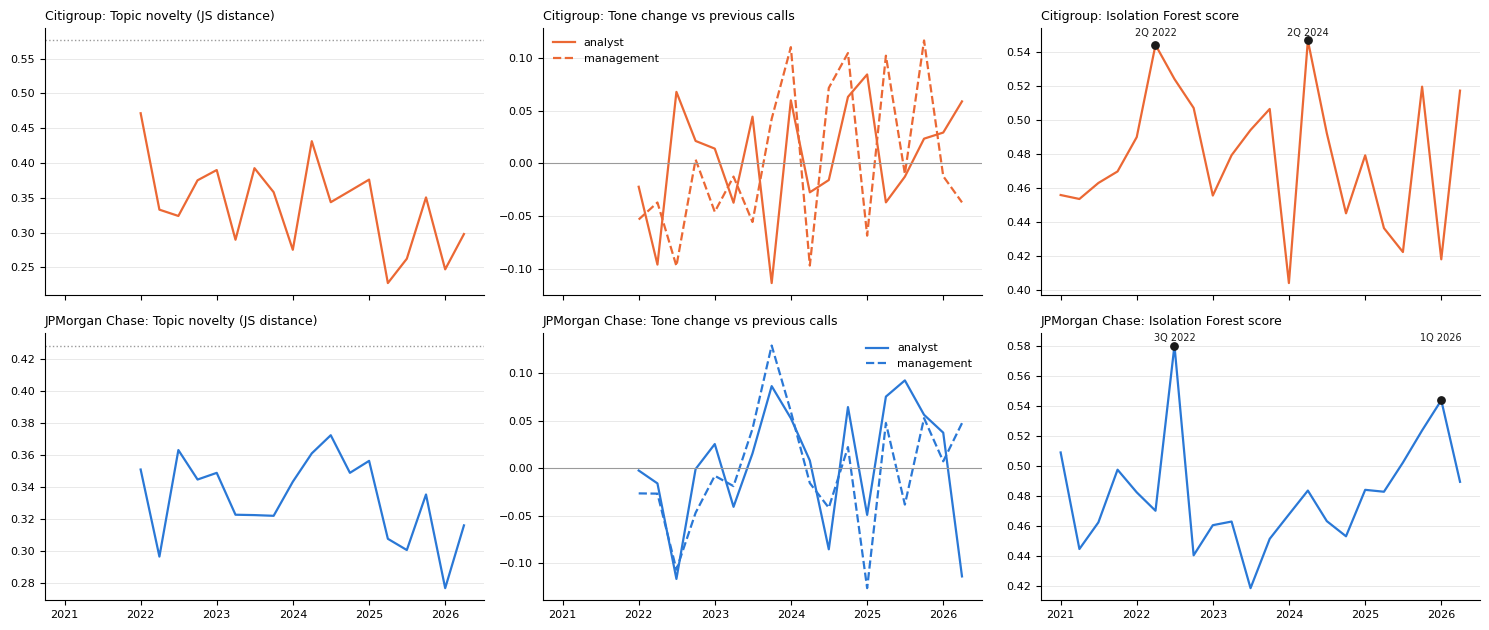

d) Quarters with flagged calls at more than one bank: 0
   Topic novelty, Citigroup vs JPMorgan Chase: Spearman rho +0.57 (p = 0.013, 18 quarters)


In [29]:
# ------------------------------------------------------------------
# 11.4 WHAT MAKES EACH FLAGGED CALL UNUSUAL, CHART, REVIEW SAMPLE, CROSS-BANK VIEW
# a) Topics with the largest rise and fall in share (percentage points
#    of assigned chunks) versus the previous BASELINE_CALLS calls and
#    versus the bank's average over all other calls
# b) Chart per bank: topic novelty, tone change, Isolation Forest score
# c) Review sample: 2 chunks from each of the 2 topics that rose most
# d) Quarters with flagged calls at more than one bank
# ------------------------------------------------------------------
call_share = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100


def topic_moves(bank, quarter, reference, n=3):
    """Largest rises and falls in topic share (pp) of one call against a reference period."""
    s = call_share.xs(bank, level='bank')
    pos = s.index.get_loc(quarter)
    if reference == 'recent':
        if pos < BASELINE_CALLS:
            return '–', '–', []
        base = s.iloc[pos - BASELINE_CALLS:pos].mean()
    else:
        base = s.drop(index=quarter).mean()
    diff = (s.iloc[pos] - base).sort_values()
    fmt = lambda items: '; '.join(f'{LABEL[t]} ({d:+.0f} pp)' for t, d in items)
    ups = [(t, d) for t, d in diff[::-1].items() if d > 0][:n]
    downs = [(t, d) for t, d in diff.items() if d < 0][:n]
    return fmt(ups), fmt(downs), [t for t, _ in ups]


explain_rows, review_rows = [], []
for (bank, quarter), r in unusual.iterrows():
    up_recent, down_recent, top_recent = topic_moves(bank, quarter, 'recent')
    up_all, down_all, top_all = topic_moves(bank, quarter, 'all')
    explain_rows.append({'bank': bank, 'reporting_period': r['reporting_period'], 'flagged_by': r['flagged_by'],
                         'rose vs previous calls': up_recent, 'fell vs previous calls': down_recent,
                         'rose vs bank average': up_all, 'fell vs bank average': down_all})
    for t in (top_recent or top_all)[:2]:                           # topics that rose most
        pool = corpus[(corpus['bank'] == bank) & (corpus['quarter'] == quarter) & (corpus['topic'] == t)]
        for _, chunk in pool.sample(min(2, len(pool)), random_state=SEED).iterrows():
            review_rows.append({'bank': bank, 'reporting_period': r['reporting_period'],
                                'flagged_by': r['flagged_by'], 'topic_label': LABEL[t],
                                'role': chunk['role'], 'net_tone': chunk['net_tone'], 'text': chunk['text']})

explain = pd.DataFrame(explain_rows)
unusual_review = pd.DataFrame(review_rows).assign(reviewer_explanation='', external_event='', notes='')
print(f'a) Topic shifts in each flagged call; c) {len(unusual_review)} chunks selected for review:')
display(explain)

# b) Chart: one row per bank; flagged calls marked in black
fig, axes = plt.subplots(len(tested_banks), 3, figsize=(15, 3.2 * len(tested_banks)), squeeze=False, sharex=True)
for row, bank in zip(axes, tested_banks):
    d = calls.xs(bank, level='bank')
    x = d.index.to_timestamp()
    colour = BANK_COLOURS.get(bank, '#6b6b6b')
    novelty_cut = d['topic_novelty'].median() + MZ_THRESHOLD * (d['topic_novelty'] - d['topic_novelty'].median()).abs().median() / 0.6745
    panels = [('Topic novelty (JS distance)', [('topic_novelty', '-')], 'flag_topic_novelty', novelty_cut),
              ('Tone change vs previous calls', [('tone_change_analyst', '-'), ('tone_change_management', '--')],
               'flag_tone_change', None),
              ('Isolation Forest score', [('if_score', '-')], 'flag_isolation_forest', None)]
    for ax, (title, series, flag, cut) in zip(row, panels):
        for col, style in series:
            ax.plot(x, d[col], linestyle=style, color=colour, linewidth=1.6,
                    label=col.replace('tone_change_', '') if len(series) > 1 else None)
            ax.scatter(x[d[flag]], d.loc[d[flag], col], color='#1a1a1a', zorder=3, s=28)
        if cut is not None and np.isfinite(cut):
            ax.axhline(cut, color='#9a9a9a', linestyle=':', linewidth=1)
        if len(series) > 1:
            ax.axhline(0, color='#9a9a9a', linewidth=0.8)
            ax.legend(frameon=False, fontsize=8)
        for xi, label in zip(x[d[flag]], d.loc[d[flag], 'reporting_period']):
            ax.annotate(label, (xi, ax.get_ylim()[1]), fontsize=7, ha='center', va='top', color='#1a1a1a')
        ax.set_title(f'{bank}: {title}', fontsize=9, loc='left')
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', color='#e5e5e5', linewidth=0.6)
        ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / 'unusual_calls.png', dpi=200, bbox_inches='tight')
plt.show()

# d) Across banks: quarters in which more than one bank has a flagged call, and
#    how closely topic novelty moves together across banks (Spearman correlation)
flagged_calls = calls[calls['n_methods'] > 0].reset_index()
synchronised = (flagged_calls.groupby('quarter')
                .agg(banks=('bank', lambda s: ', '.join(sorted(s))), n_banks=('bank', 'nunique'),
                     flagged_by=('flagged_by', lambda s: ' | '.join(s)))
                .query('n_banks > 1'))
print(f'd) Quarters with flagged calls at more than one bank: {len(synchronised)}')
if len(synchronised):
    display(synchronised)
novelty_wide = calls['topic_novelty'].unstack('bank')
for bank_a, bank_b in itertools.combinations(tested_banks, 2):
    both = novelty_wide[[bank_a, bank_b]].dropna()
    if len(both) >= 3:
        rho, p = spearmanr(both[bank_a], both[bank_b])
        print(f'   Topic novelty, {bank_a} vs {bank_b}: Spearman rho {rho:+.2f} (p = {p:.3f}, {len(both)} quarters)')


*Across banks.*
- *Flags:* no quarter had flagged calls at both banks.
- *Timing of change:* topic novelty was positively correlated between the banks (Spearman ρ = +0.57, p = 0.013, 18 quarters). Quarters in which one bank's Q&A departed from its previous four calls tended to be quarters of change at the other bank.
- *Shared timing, different content:* together with the shared turning points of the theme shares (section 10), this indicates that changes in the Q&A agenda are timed by common external conditions, while each bank's topic profile remains distinct.
- *Caution on the p-value:* because consecutive novelty values share part of their four-call baseline, the p-value is approximate.

## 12. Manual review samples
### 12.1 Chunks for naming topics and checking FinBERT labels

In [30]:
# ------------------------------------------------------------------
# 12.1 SAMPLES FOR MANUAL REVIEW
# a) Topics: the 3 representative chunks chosen by BERTopic plus 3
#    random chunks per topic, to name each topic and check its content
# b) FinBERT: REVIEW_PER_LABEL random chunks per predicted label, to
#    check the tone scores against a reader's judgement
# Random draws use the fixed seed; empty columns are for the reviewer.
# ------------------------------------------------------------------
representative = topic_model.get_representative_docs()
topic_rows = []
for t in TOPICS:
    for text in representative.get(t, [])[:3]:
        topic_rows.append({'topic_label': LABEL[t], 'source': 'representative', 'text': text})
    pool = corpus[corpus['topic'] == t]
    for text in pool.sample(min(3, len(pool)), random_state=SEED)['text']:
        topic_rows.append({'topic_label': LABEL[t], 'source': 'random', 'text': text})
topic_review = pd.DataFrame(topic_rows).assign(reviewer_topic_name='', fits_topic='', notes='')

finbert_review = (pd.concat([g.sample(min(REVIEW_PER_LABEL, len(g)), random_state=SEED)
                             for _, g in corpus.groupby('finbert_label')], ignore_index=True)
                    [['bank', 'quarter', 'speaker_type', 'finbert_label', 'net_tone', 'text']]
                    .assign(quarter=lambda d: d['quarter'].astype(str), reviewer_label='', notes=''))
print(f'a) {len(topic_review)} chunks for topic review | b) {len(finbert_review)} chunks for FinBERT review')
for r in topic_review.head(4).itertuples(index=False):           # preview; full lists are saved in 13.1
    print(f'\n[{r.topic_label} | {r.source}]')
    print(textwrap.fill(r.text, 110))


a) 204 chunks for topic review | b) 30 chunks for FinBERT review

[0: expense, expenses, transformation, billion | representative]
But the transformation over time will deliver efficiencies, will reduce the manual touchpoints, will drive
straight through processing, and therefore, will allow for us to bring our expenses down. And the final piece
that I'll mention is the strategy, and so Jane mentioned in our strategy a focus on core T R A N S C R I P T
Citi Fourth Quarter 2021 Earnings Review Friday, January 14, 2022 businesses, and that's going to allow for us
to look at the organizational structure and identify more simplification opportunities in the way we manage
and run the firm. We do about $300 million to $400 million of productivity savings a quarter.

[0: expense, expenses, transformation, billion | representative]
I also hope that you would then see that as we deliver on the expense target that we have a path to continuing
to deliver on the medium-term expense target, the dri

## 13. Save outputs
### 13.1 All results to `cross_bank_qa/`

In [31]:
# ------------------------------------------------------------------
# 13.1 SAVE ALL OUTPUTS to cross_bank_qa/
# Figures were saved by the cells that drew them.
# ------------------------------------------------------------------
as_str = lambda d: d.assign(quarter=d['quarter'].astype(str)) if 'quarter' in d else d

corpus.pipe(as_str).to_parquet(OUT_DIR / 'qa_chunks_topics_tone.parquet', index=False)
topic_table.to_csv(OUT_DIR / 'topic_info.csv', index=False)
shares.pipe(as_str).to_parquet(OUT_DIR / 'topic_share_by_call.parquet', index=False)
trends.to_csv(OUT_DIR / 'topic_trends.csv', index=False)
mapping.to_csv(OUT_DIR / 'theme_mapping.csv', index=False)
calls_out = calls.reset_index().pipe(as_str)
calls_out.to_parquet(OUT_DIR / 'call_features_unusual.parquet', index=False)
topic_trends_by_theme = (trends.assign(theme=trends['topic'].map(theme_of))
                               .assign(theme_label=lambda d: d['theme'].map(THEME_LABEL))
                               .sort_values(['theme', 'bank', 'topic']))

sheets = {
    'topics': topic_table, 'model_selection': grid, 'stability': stability,
    'topics_by_bank': by_bank.reset_index(), 'topics_by_role': by_role.reset_index(),
    'prevalence_residuals': prevalence_full['residuals'].reset_index(),
    'topic_trends': trends, 'cross_bank_trajectories': cross_trajectories, 'cross_bank_patterns': cross_patterns,
    'agenda_distance': agenda_distance.pipe(as_str),
    'tone_by_topic': tone_topic.reset_index(), 'tone_by_call': tone_time.pipe(as_str),
    'tone_bank_differences': tone_differences,
    'theme_mapping': mapping, 'themes_by_bank': theme_by_bank.reset_index(), 'theme_trends': theme_trends,
    'topic_trends_by_theme': topic_trends_by_theme, 'tone_by_theme': theme_tone.reset_index(),
    'unusual_all_calls': calls_out, 'unusual_flagged': explain,
    'unusual_synchronised': synchronised.reset_index().pipe(as_str),
    'isolation_forest_checks': pd.DataFrame(seed_checks),
}
with pd.ExcelWriter(OUT_DIR / 'cross_bank_results.xlsx', engine='openpyxl') as writer:
    for name, table in sheets.items():
        table.to_excel(writer, sheet_name=name[:31], index=False)
with pd.ExcelWriter(OUT_DIR / 'review_samples.xlsx', engine='openpyxl') as writer:
    topic_review.to_excel(writer, sheet_name='topic_review', index=False)
    finbert_review.to_excel(writer, sheet_name='finbert_review', index=False)
    unusual_review.to_excel(writer, sheet_name='unusual_calls_review', index=False)

topic_model.save(OUT_DIR / 'bertopic_model', serialization='safetensors',
                 save_ctfidf=True, save_embedding_model=EMBEDDING_MODEL)
print(f'Saved to {OUT_DIR.name}/: cross_bank_results.xlsx ({len(sheets)} sheets), review_samples.xlsx, '
      f'chunk/share/trend files, theme mapping, fitted model and figures')


Saved to cross_bank_qa/: cross_bank_results.xlsx (22 sheets), review_samples.xlsx, chunk/share/trend files, theme mapping, fitted model and figures


## 14. Retrieval-augmented generation (RAG)
**Purpose.** To answer questions about the corpus, for example how two banks discussed a subject in a given period, with every statement linked to the transcript passages it is based on. The RAG supports the qualitative interpretation of sections 7–11 and illustrates how supervisors could query disclosures across banks. It does not replace the quantitative analysis.

**Index (14.2).**
- *Content:* the Q&A chunks of section 2, with bank, quarter, speaker type, topic, theme and tone.
- *Dense index:* the embeddings of section 3.
- *Sparse index:* BM25 on lower-case words and numbers, so exact terms such as "CET1" or "G-SIB" are found even where embeddings are less precise.

**Retrieval (14.3).**
- *Filters:* bank, period, speaker type, topic and theme select the chunks to search.
- *Ranking:* dense search and BM25 each rank the chunks, and the two rankings are combined by reciprocal rank fusion (k = 60).
- *Re-ranking:* a cross-encoder (`ms-marco-MiniLM-L-6-v2`) re-scores the fused candidates.
- *Context:* each retrieved chunk is shown with its neighbouring chunks, and an answer chunk also shows the start of the analyst's question. Overlapping passages are removed.
- *Cross-bank questions:* the same number of sources is retrieved from each bank, so that no bank dominates the evidence.

**Generation (14.4–14.5).**
- *Model:* `Qwen2.5-7B-Instruct`, an open model (Apache 2.0) loaded in 4-bit on a Colab GPU. Without a GPU, a smaller model is used for testing only.
- *Instructions:* answer only from the numbered sources, cite a source after every statement, describe each bank separately before comparing, distinguish analysts from management, and state when the sources are insufficient.
- *Decoding:* greedy, so the same question and sources always give the same answer.
- *Automatic checks:* for each answer, citations to non-existent sources and the share of sentences that carry a citation.

**Evaluation (14.6).**
- *Retrieval:* a test set of questions with keywords that a relevant chunk must contain. Each retrieval mode (dense, BM25, hybrid, hybrid with re-ranker) is scored on hit@k and precision@k. Keyword matching is a transparent but approximate measure of relevance, and the example test set should be replaced with questions whose answers are known from reading the transcripts.
- *Generation:* all answers are exported with their sources for manual review of support, completeness and correct attribution to banks.

**Limitations.**
- Answers can omit relevant passages that were not retrieved, or misstate a source.
- The 4-bit open model follows citation instructions less reliably than larger models.
- Quotations used in reporting are checked against the transcripts.
### 14.1 Setup

In [33]:
   !nvidia-smi --query-gpu=memory.used,memory.total --format=csv

memory.used [MiB], memory.total [MiB]
451 MiB, 15360 MiB


In [32]:
# ------------------------------------------------------------------
# 14.1 RAG SETUP: libraries and settings
# Retrieval-augmented generation over the Q&A corpus: a question retrieves
# the most relevant chunks, and an open language model answers ONLY from
# them, citing each source as [S1], [S2] ...
# Requires sections 1-10 in this session (corpus with topics, themes and
# tone, and the chunk embeddings from 3.1).
# GPU runtime recommended (Runtime -> Change runtime type -> T4 GPU).
# If Colab asks to restart the session after the install, restart and re-run sections 1-10.
# ------------------------------------------------------------------
!pip install -q rank_bm25 bitsandbytes "transformers>=4.51"   # Qwen3 needs transformers 4.51 or later

from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

LLM_MODEL_GPU  = 'Qwen/Qwen3-8B'                # open licence (Apache 2.0); loaded in 4-bit (~6 GB on a T4)
LLM_MODEL_CPU  = 'Qwen/Qwen3-1.7B'              # fallback without GPU: slow and weaker, for testing only
THINKING       = False                          # Qwen3 'thinking' mode off: direct, cited answers
RERANKER_MODEL = 'cross-encoder/ms-marco-MiniLM-L-6-v2'   # re-scores (question, chunk) pairs
USE_RERANKER   = True
CANDIDATES     = 50     # chunks taken from each retriever before fusion and re-ranking
TOP_K          = 8      # sources given to the language model
PER_BANK       = 4      # sources per bank for cross-bank questions
WINDOW         = 1      # neighbouring chunks added on each side of a retrieved chunk
RRF_K          = 60     # reciprocal rank fusion constant (standard value)
MAX_NEW_TOKENS = 500    # maximum length of an answer
MAX_PROMPT_TOKENS = 4000   # sources are dropped from the end if the prompt is longer (limits GPU memory)

needed = ['corpus', 'embeddings', 'embedder', 'docs', 'OUT_DIR', 'DEVICE', 'SEED']
missing = [name for name in needed if name not in globals()]
assert not missing and 'net_tone' in corpus, f'Run sections 1-10 first. Missing: {missing or ["net_tone"]}'

RAG_DIR = OUT_DIR / 'rag'
RAG_DIR.mkdir(exist_ok=True)
print(f'Device: {DEVICE} | language model: {LLM_MODEL_GPU if DEVICE == "cuda" else LLM_MODEL_CPU}')

Device: cuda | language model: Qwen/Qwen3-8B


### 14.2 Index

In [34]:
# ------------------------------------------------------------------
# 14.2 INDEX: the Q&A chunks with their metadata
# - Dense index: the embeddings computed in 3.1 (same row order as corpus)
# - Sparse index: BM25 on lower-case words and numbers, so exact terms such
#   as 'CET1', 'SCB' or 'G-SIB' are matched even when embeddings miss them
# - Context: each retrieved chunk is shown with WINDOW neighbouring chunks
#   of the same question or answer; answer chunks also show the start of
#   the analyst's question they respond to
# ------------------------------------------------------------------
rag = corpus.reset_index(drop=True)
assert len(rag) == len(embeddings) and rag['text'].tolist() == docs, 'Index and embeddings do not match: re-run 2.1-3.1'

TOKEN = re.compile(r"[a-z0-9]+(?:[-'][a-z0-9]+)*")


def tokenize(text):
    """Lower-case words and numbers (keeps 'cet1', 'g-sib') for BM25."""
    return TOKEN.findall(text.lower())


bm25 = BM25Okapi([tokenize(t) for t in rag['text']])
groups = rag.groupby(['doc_id', 'exchange', 'role'], sort=False).indices          # rows of each question/answer
question_start = rag[rag['role'] == 'question'].groupby(['doc_id', 'exchange'])['text'].first().to_dict()
reranker = CrossEncoder(RERANKER_MODEL, device=DEVICE) if USE_RERANKER else None

has_theme = 'theme' in rag
print(f'Index: {len(rag):,} chunks | {rag["bank"].nunique()} banks | {rag["quarter"].nunique()} quarters | '
      f'themes available: {has_theme} | re-ranker: {RERANKER_MODEL if USE_RERANKER else "off"}')


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Index: 6,945 chunks | 3 banks | 22 quarters | themes available: True | re-ranker: cross-encoder/ms-marco-MiniLM-L-6-v2


### 14.3 Retrieval

In [35]:
# ------------------------------------------------------------------
# 14.3 RETRIEVAL
# 1. Filters (bank, period, speaker type, topic, theme) select the chunks to search.
# 2. Dense search (cosine similarity of embeddings) and BM25 each rank the chunks.
# 3. Reciprocal rank fusion combines the two rankings: score = sum 1 / (RRF_K + rank).
# 4. The cross-encoder re-ranks the fused candidates (if USE_RERANKER).
# 5. Overlapping context windows are removed, so each source adds new text.
# For cross-bank questions the same number of sources is taken from each bank.
# ------------------------------------------------------------------
def filter_mask(banks=None, start=None, end=None, speaker=None, topics=None, themes=None):
    """Boolean mask of chunks matching the filters (start/end as '2023Q1'; None = no filter)."""
    m = pd.Series(True, index=rag.index)
    if banks:
        m &= rag['bank'].isin(banks)
    if start:
        m &= rag['quarter'] >= pd.Period(start, 'Q')
    if end:
        m &= rag['quarter'] <= pd.Period(end, 'Q')
    if speaker:
        m &= rag['speaker_type'].eq(speaker)
    if topics is not None:
        m &= rag['topic'].isin(topics)
    if themes is not None and has_theme:
        m &= rag['theme'].isin(themes)
    return m.to_numpy()


def search(query, mask, n=TOP_K, mode='hybrid', rerank=USE_RERANKER):
    """Rank the chunks in `mask` for `query`; mode = 'dense', 'bm25' or 'hybrid'. Returns row numbers."""
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        return []
    rankings = []
    if mode in ('dense', 'hybrid'):
        q = embedder.encode([query], normalize_embeddings=True)[0]
        dense = embeddings[idx] @ q
        rankings.append(idx[np.argsort(-dense)[:CANDIDATES]])
    if mode in ('bm25', 'hybrid'):
        sparse = bm25.get_scores(tokenize(query))[idx]
        order = np.argsort(-sparse)[:CANDIDATES]
        rankings.append(idx[order[sparse[order] > 0]])            # only chunks sharing a query word
    fused = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking):
            fused[i] = fused.get(i, 0.0) + 1.0 / (RRF_K + rank + 1)
    candidates = sorted(fused, key=fused.get, reverse=True)[:CANDIDATES]
    if rerank and reranker is not None and candidates:
        scores = reranker.predict([(query, rag.at[i, 'text']) for i in candidates])
        candidates = [candidates[j] for j in np.argsort(-np.asarray(scores))]
    chosen, covered = [], set()
    for i in candidates:                                           # skip chunks inside an already chosen window
        key = (rag.at[i, 'doc_id'], rag.at[i, 'exchange'], rag.at[i, 'role'])
        pos = list(groups[key]).index(i)
        if (key, pos) in covered:
            continue
        chosen.append(i)
        covered |= {(key, p) for p in range(pos - 2 * WINDOW, pos + 2 * WINDOW + 1)}
        if len(chosen) == n:
            break
    return chosen


def retrieve(query, banks=None, compare_banks=False, **filters):
    """Sources for a question; with compare_banks, PER_BANK sources from each bank."""
    if compare_banks:
        hits = []
        for bank in (banks or sorted(rag['bank'].unique())):
            hits += search(query, filter_mask(banks=[bank], **filters), PER_BANK)
        return hits
    return search(query, filter_mask(banks=banks, **filters), TOP_K)


def source_block(i, number):
    """Header and text of one source: the chunk with its neighbouring chunks (and question context)."""
    r = rag.loc[i]
    key = (r['doc_id'], r['exchange'], r['role'])
    pos_list = list(groups[key])
    k = pos_list.index(i)
    text = ' '.join(rag.loc[pos_list[max(0, k - WINDOW):k + WINDOW + 1], 'text'])
    if r['role'] == 'answer' and (r['doc_id'], r['exchange']) in question_start:
        text = f"(Analyst asked: {textwrap.shorten(question_start[(r['doc_id'], r['exchange'])], 250)}) {text}"
    header = f"[S{number}] {r['bank']} | {r['reporting_period']} | {r['speaker_type']} | topic {r['topic_label']}"
    return header, text


hits = retrieve('Basel III endgame capital requirements', compare_banks=True)
print('Retrieval check (no language model yet):')
for n, i in enumerate(hits, 1):
    header, text = source_block(i, n)
    print(f'{header}\n   {textwrap.shorten(text, 160)}')


Retrieval check (no language model yet):
[S1] Bank of America | 1Q 2026 | management | topic 24: basel, basel iii, iii, endgame
   (Analyst asked: Thank you. Good morning. In terms of capital, with the peak at the new proposals, how are you thinking about a capital target as you [...]
[S2] Bank of America | 1Q 2026 | analyst | topic 2: buybacks, capital, stock, dividend
   Thank you. Good morning. In terms of capital, with the peak at the new proposals, how are you thinking about a capital target as you strive towards your [...]
[S3] Bank of America | 1Q 2026 | management | topic 13: quarter, half, seasonality, fourth
   (Analyst asked: Great. And then the popular question this quarter has been durability of trading revenues. I'm interested in how you see the potential of [...]
[S4] Bank of America | 1Q 2026 | analyst | topic 33: inflation, wage, wages, inflationary
   Got it. And just a very technical question on some of the capital reform proposals. And this sort of came to everyone'

### 14.4 Language model and prompt

In [36]:
!pip install -q rank_bm25 bitsandbytes "transformers>=4.51"   # Qwen3 needs transformers 4.51 or later

In [37]:
# ------------------------------------------------------------------
# 14.4 LANGUAGE MODEL AND PROMPT
# The model receives numbered sources and must answer only from them,
# citing a source after each statement. Greedy decoding (no sampling)
# gives the same answer every time for the same question and sources.
# ------------------------------------------------------------------
import gc
import sys

LLM_MODEL = LLM_MODEL_GPU if DEVICE == 'cuda' else LLM_MODEL_CPU

# Free GPU memory held by a language model loaded earlier in this session
# (e.g. before LLM_MODEL_GPU was changed); otherwise the new model does not fit.
# A failed load also keeps its tensors alive through the stored error traceback.
for name in ['llm', 'tokenizer']:
    globals().pop(name, None)
sys.last_type = sys.last_value = sys.last_traceback = None
gc.collect()

if DEVICE == 'cuda':
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f'GPU: {torch.cuda.get_device_name(0)} | free memory {free / 1e9:.1f} of {total / 1e9:.1f} GB '
          f'(Qwen3-8B in 4-bit needs about 7 GB)')

tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)
if DEVICE == 'cuda':
    quantisation = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                      bnb_4bit_compute_dtype=torch.float16,
                                      bnb_4bit_use_double_quant=True)          # saves about 0.4 GB
    llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, quantization_config=quantisation,
                                               device_map={'': 0})            # whole model on the GPU
else:
    print('No GPU: using the small fallback model. Answers will be slow and less reliable.')
    llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, torch_dtype=torch.float32)
llm.eval()

SYSTEM_PROMPT = (
    'You assist banking supervisors. Answer ONLY from the numbered sources, which are excerpts from the '
    'question-and-answer sections of bank earnings calls. After every statement, cite the source(s) in square '
    'brackets, for example [S2] or [S1][S4]. When the question concerns more than one bank, describe each bank '
    'separately and then compare them. Distinguish what analysts asked from what management said. Quote figures '
    'exactly as written. If the sources do not answer the question, say so. Do not use outside knowledge.')


def build_messages(question, sources):
    """Chat messages: instructions, then the numbered sources and the question."""
    blocks = '\n\n'.join(f'{header}\n{text}' for header, text in sources)
    return [{'role': 'system', 'content': SYSTEM_PROMPT},
            {'role': 'user', 'content': f'Sources:\n\n{blocks}\n\nQuestion: {question}\n\nAnswer with citations:'}]


def generate(messages):
    """Deterministic answer from the language model (Qwen3 thinking mode switched off by THINKING)."""
    prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False,
                                           enable_thinking=THINKING)
    inputs = tokenizer(prompt, return_tensors='pt').to(llm.device)
    with torch.no_grad():
        output = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                              temperature=None, top_p=None, top_k=None,
                              repetition_penalty=1.05,          # greedy decoding can repeat phrases
                              pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(output[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    del inputs, output                                          # release GPU memory before the next question
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    return re.sub(r'<think>.*?</think>', '', text, flags=re.S).strip()      # drop any reasoning block


def prompt_tokens(messages):
    """Number of tokens in the prompt built from `messages`."""
    prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False,
                                           enable_thinking=THINKING)
    return len(tokenizer(prompt)['input_ids'])


print(f'Loaded {LLM_MODEL}')

GPU: Tesla T4 | free memory 15.3 of 15.6 GB (Qwen3-8B in 4-bit needs about 7 GB)


Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

Loaded Qwen/Qwen3-8B


### 14.5 Ask questions
Change the example questions or add your own `ask(...)` calls; filters are listed in the cell.

In [38]:
# ------------------------------------------------------------------
# 14.5 ASK QUESTIONS
# ask() retrieves sources, generates an answer and checks its citations:
#   - cited sources that do not exist (invalid)
#   - share of sentences that carry at least one citation
# Every question is logged for the manual review in 14.6.
# Filters: banks=[...], compare_banks=True, start='2023Q1', end='2023Q4',
#          speaker='analyst' or 'management', topics=[...], themes=[...]
# ------------------------------------------------------------------
rag_log = []


def ask(question, show=True, **filters):
    """Answer a question from the Q&A corpus with cited sources; returns the logged record."""
    hits = retrieve(question, **filters)
    if not hits:
        print('No chunks match these filters.')
        return None
    sources = [source_block(i, n) for n, i in enumerate(hits, 1)]
    while len(sources) > 1 and prompt_tokens(build_messages(question, sources)) > MAX_PROMPT_TOKENS:
        sources.pop()                                           # keep the prompt within MAX_PROMPT_TOKENS
    answer = generate(build_messages(question, sources))
    cited = sorted({int(c) for c in re.findall(r'\[S(\d+)\]', answer)})
    sentences = [s for s in re.split(r'(?<=[.!?])\s+', answer) if len(s.split()) > 3]
    record = {'question': question, 'filters': str(filters), 'answer': answer,
              'sources': '\n'.join(f'{h}: {t}' for h, t in sources),
              'n_sources': len(sources), 'cited_sources': ', '.join(f'S{c}' for c in cited),
              'invalid_citations': ', '.join(f'S{c}' for c in cited if c > len(sources)),
              'uncited_sources': len(sources) - len([c for c in cited if c <= len(sources)]),
              'pct_sentences_cited': 100 * np.mean([bool(re.search(r'\[S\d+\]', s)) for s in sentences])
                                     if sentences else 0.0}
    rag_log.append(record)
    if show:
        print(f'QUESTION: {question}  {filters if filters else ""}\n')
        print(textwrap.fill(answer, 110, replace_whitespace=False))
        print(f"\nCitation check: cited {record['cited_sources'] or 'none'} | invalid: {record['invalid_citations'] or 'none'}"
              f" | sentences with a citation: {record['pct_sentences_cited']:.0f}%")
        print('\nSOURCES')
        for header, text in sources:
            print(f'{header}\n   {textwrap.shorten(text, 220)}')
        print('\n' + '-' * 110)
    return record


# Cross-bank example questions (change or add your own)
ask('How did analysts question JPMorgan Chase and Citigroup about deposit costs and deposit betas, '
    'and how did management respond?', compare_banks=True, start='2023Q1', end='2023Q4')
ask('What did management say about the Basel III endgame proposal and its effect on capital?', compare_banks=True)
ask('Which credit risks did analysts raise most often in 2025-2026?', compare_banks=True, speaker='analyst',
    start='2025Q1')


QUESTION: How did analysts question JPMorgan Chase and Citigroup about deposit costs and deposit betas, and how did management respond?  {'compare_banks': True, 'start': '2023Q1', 'end': '2023Q4'}

Analysts questioned both JPMorgan Chase and Citigroup about deposit costs and deposit betas, and management
responded as follows:

For **JPMorgan Chase**, analysts asked about the implications of non-interest-bearing
deposits increasing to 28% of total deposits and whether this indicated a shift toward more interest-bearing
deposits or simply a repricing of existing interest-bearing deposits [S5]. Management responded by discussing
the concept of deposit betas and noted that the way the number was previously constructed assumed through-the-
cycle betas on all deposits, which would not have accounted for deposit beta acceleration. They explained that
the current approach recognizes that the reprice predicted by beta would not be instantaneous, leading to
mathematical consequences, but caution

{'question': 'Which credit risks did analysts raise most often in 2025-2026?',
 'filters': "{'compare_banks': True, 'speaker': 'analyst', 'start': '2025Q1'}",
 'answer': 'Analysts raised credit risks related to consumer credit, the credit cycle, and underwriting standards most often in 2025-2026. Specifically, they questioned the resilience of consumers amid inflation, the potential for a credit cycle downturn, and the impact of macroeconomic uncertainties on credit losses [S2][S3][S11]. Additionally, there were concerns about the implications of a potential rise in unemployment on credit risk [S5]. These topics were discussed across multiple quarters and institutions, highlighting the ongoing focus on credit risk in the banking sector during this period.',
 'sources': "[S1] Bank of America | 1Q 2026 | analyst | topic 17: scb, sib, gsib, stress: Got it. And just a very technical question on some of the capital reform proposals. And this sort of came to everyone's attention when one of 

### 14.6 Evaluation

In [42]:
# ------------------------------------------------------------------
# 14.6 EVALUATION
# a) Retrieval: a test set of questions with keywords that a relevant chunk
#    must contain (a transparent proxy for relevance). For each retrieval
#    mode: hit@k (at least one relevant chunk in the top k) and
#    precision@k (share of the top k that is relevant).
#    The test set below is an example: replace or extend it with questions
#    whose answers you know from your own reading of the transcripts.
# b) Generation: citation checks from 14.5, and a sheet for manual review
#    (is every statement supported by the cited source? is the answer complete?)
# ------------------------------------------------------------------
EVAL_SET = [
    {'question': 'Basel III endgame capital requirements', 'keywords': ['basel', 'endgame']},
    {'question': 'progress on consent orders and regulatory remediation', 'keywords': ['consent order']},
    {'question': 'deposit betas and deposit pricing', 'keywords': ['beta', 'betas']},
    {'question': 'credit card net charge-offs', 'keywords': ['charge-off', 'charge-offs', 'charge off', 'nco', 'ncos']},
    {'question': 'share buybacks and capital return', 'keywords': ['buyback', 'buybacks', 'repurchase']},
    {'question': 'reserve build and CECL allowance', 'keywords': ['reserve', 'reserves', 'cecl', 'allowance']},
    {'question': 'investment in artificial intelligence and technology', 'keywords': ['ai', 'artificial intelligence']},
    {'question': 'private credit and lending to non-bank financial institutions',
     'keywords': ['private credit', 'nbfi', 'non-bank']},
]


def relevant(i, keywords):
    """A chunk is relevant if it contains any keyword as a whole word or phrase."""
    text = rag.at[i, 'text'].lower()
    return any(re.search(rf'\b{re.escape(k)}\b', text) for k in keywords)


MODES = {'dense': dict(mode='dense', rerank=False), 'bm25': dict(mode='bm25', rerank=False),
         'hybrid': dict(mode='hybrid', rerank=False), 'hybrid + re-ranker': dict(mode='hybrid', rerank=True)}
if reranker is None:
    MODES.pop('hybrid + re-ranker')

eval_rows = []
everything = np.ones(len(rag), dtype=bool)
for item in EVAL_SET:
    for name, kwargs in MODES.items():
        top = search(item['question'], everything, TOP_K, **kwargs)
        rel = [relevant(i, item['keywords']) for i in top]
        eval_rows.append({'question': item['question'], 'mode': name,
                          f'hit@{TOP_K}': float(any(rel)), f'precision@{TOP_K}': np.mean(rel) if rel else 0.0})
retrieval_eval = pd.DataFrame(eval_rows)
print(f'a) Retrieval quality on {len(EVAL_SET)} test questions (mean over questions):')
display(retrieval_eval.groupby('mode', sort=False)[[f'hit@{TOP_K}', f'precision@{TOP_K}']].mean()
        .style.format('{:.2f}'))
display(retrieval_eval.pivot_table(index='question', columns='mode', values=f'precision@{TOP_K}', sort=False)
        .style.background_gradient(cmap='Blues', vmin=0, vmax=1, axis=None).format('{:.2f}'))

log = pd.DataFrame(rag_log)
if len(log):
    print(f"b) Generation: {len(log)} answers | mean % sentences with a citation: {log['pct_sentences_cited'].mean():.0f}% | "
          f"answers with invalid citations: {(log['invalid_citations'] != '').sum()}")

review_cols = dict(supported_by_sources='', complete='', correct_bank_attribution='', reviewer_notes='')
with pd.ExcelWriter(RAG_DIR / 'rag_evaluation.xlsx', engine='openpyxl') as writer:
    retrieval_eval.to_excel(writer, sheet_name='retrieval_eval', index=False)
    log.assign(**review_cols).to_excel(writer, sheet_name='answers_for_review', index=False)
    pd.DataFrame([{'setting': k, 'value': str(v)} for k, v in
                  {'LLM_MODEL': LLM_MODEL, 'EMBEDDING_MODEL': EMBEDDING_MODEL, 'RERANKER_MODEL': RERANKER_MODEL,
                   'USE_RERANKER': USE_RERANKER, 'TOP_K': TOP_K, 'PER_BANK': PER_BANK, 'WINDOW': WINDOW,
                   'CANDIDATES': CANDIDATES, 'RRF_K': RRF_K, 'MAX_NEW_TOKENS': MAX_NEW_TOKENS}.items()]) \
      .to_excel(writer, sheet_name='settings', index=False)
print(f'Saved {RAG_DIR.relative_to(OUT_DIR.parent)}/rag_evaluation.xlsx (retrieval results, answers for review, settings)')


a) Retrieval quality on 8 test questions (mean over questions):


,hit@8,precision@8
mode,,
dense,1.00,0.92
bm25,1.00,0.80
hybrid,1.00,0.86
hybrid + re-ranker,1.00,0.91


mode,dense,bm25,hybrid,hybrid + re-ranker
question,,,,
Basel III endgame capital requirements,1.00,1.00,1.00,1.00
progress on consent orders and regulatory remediation,0.62,0.50,0.50,0.62
deposit betas and deposit pricing,1.00,0.62,0.88,1.00
credit card net charge-offs,0.75,1.00,0.88,1.00
share buybacks and capital return,1.00,1.00,1.00,1.00
reserve build and CECL allowance,1.00,1.00,1.00,1.00
investment in artificial intelligence and technology,1.00,0.25,0.75,0.75
private credit and lending to non-bank financial institutions,1.00,1.00,0.88,0.88


b) Generation: 4 answers | mean % sentences with a citation: 63% | answers with invalid citations: 0
Saved cross_bank_qa/rag/rag_evaluation.xlsx (retrieval results, answers for review, settings)


In [43]:
# Inspect the 8 passages retrieved for the consent-order question (hybrid + re-ranker)
q = 'progress on consent orders and regulatory remediation'
for n, i in enumerate(search(q, np.ones(len(rag), dtype=bool), TOP_K, mode='hybrid', rerank=True), 1):
    r = rag.loc[i]
    print(f"[{n}] {r['bank']} | {r['reporting_period']} | {r['speaker_type']} | "
          f"keyword match: {relevant(i, ['consent order', 'consent orders'])}")
    print('    ', textwrap.shorten(r['text'], 300))

[1] Citigroup | 2Q 2024 | management | keyword match: True
     T R A N S C R I P T Citi Second Quarter 2024 Earnings Call Yeah, and so as Jane says, the progress that we've made, it spans multiple parts of the consent order and transformation work. Remember, that consent order and transformation work includes risk, it includes controls, it includes [...]
[2] Citigroup | 2Q 2026 | management | keyword match: True
     In terms of the timing of the removal of the consent orders, that is fully at the discretion of our regulators, both in terms of reviewing the work that we’ve done as we hand it over, and then going through their closure process, and that takes time. But I do re-emphasize for our investors, [...]
[3] Citigroup | 4Q 2025 | analyst | keyword match: True
     You talked about the progress and the consent order amendment getting lifted, and Jane, you talked earlier about as you hit your target end state, expenses come off. As we think about the entirety of the consent order l

## 15. Findings

**Corpus and model.**
- *Corpus:* 46 calls (JPM 22, Citi 22, BAC 2: 1Q–2Q 2026), 1,166 exchanges and 6,945 Q&A chunks; 29% of chunks are analyst questions.
- *Model:* minimum topic size 40 (size 60 had the highest coherence; size 80 was degenerate); 34 topics.
- *Outliers:* 34.6% before reassignment, 3.7% after (minimum cosine similarity 0.39).
- *Quality:* coherence (NPMI) −0.005; diversity 0.96.
- *Reproducibility and stability:* same seed ARI = 1.00; other seeds 34–40 topics, mean ARI 0.66 (moderate).

**Topics across banks (7).** Over 22 common quarters, the topic mixes of Citigroup and JPMorgan Chase differed (χ² = 1030.5, df = 33, p < 0.001; Cramér's V = 0.40). Topics discussed more than expected (adjusted residual > 3.38, Bonferroni):

| Bank | Distinctive topics (residual) | Interpretation (to confirm in review) |
|---|---|---|
| Citigroup | earnings review (+12.3), token services (+11.0), Banamex/IPO (+10.6), clients/wealth/services (+7.6), consent orders (+6.7), expenses/transformation (+5.5), investor day (+4.9), legacy franchises (+4.7) | Firm-specific restructuring: cost and transformation programme, divestments, consent-order remediation, strategic targets and the services business |
| JPMorgan Chase | lending (+8.9), stagflation (+6.8), inflation (+6.6), recession (+6.4), deposits (+6.3), banks/fintech (+6.2), risk/geopolitics (+5.8), QT/QE (+5.1), private credit (+5.1), yield curve (+4.5), credit cycle (+4.5), Basel III endgame (+4.3) | Macroeconomic conditions, balance sheet, credit and capital regulation |
| Bank of America (2026 only, descriptive) | NII ex markets (+6.4) | Net interest income outlook |

*Shared ground:* NII, the investment-banking pipeline, reserves and the stress capital buffer did not differ between the banks.

*Speaker type:* analyst questions concentrated on guidance and constraints (NII, capital targets, Basel, consent orders); management answers dominated strategy, technology and macroeconomic commentary.

**Trajectories across banks (8).** One significant trend after correction: AI and technology at Citigroup (1.7% → 4.1% of chunks; τ = +0.55, q = 0.031). Other changes are tendencies (q > 0.05). In the lag column, negative values mean the topic appeared first at JPM.

| Topic | JPM | Citi | Pattern | Lag in first appearance | Correlation (ρ) |
|---|---|---|---|---|---|
| AI and technology | rising (n.s.) | emerging | shared increase | 0 | +0.48 |
| Private credit | rising (n.s., q = 0.09) | episodic | shared; both from 4Q 2022 | 0 | +0.86 |
| Deposit betas | peak 2Q 2023 | peak 1Q 2023 | shared (2023) | −3 | +0.85 |
| Recession | persistent, peak 2Q 2022 | episodic, peak 2Q 2022 | shared timing, higher at JPM | 0 | +0.68 |
| Reserves/CECL | persistent, declining (n.s.) | no consistent pattern | shared | 0 | +0.67 |
| Basel III endgame | persistent, declining (n.s.) | no consistent pattern | JPM earlier | −7 | +0.36 |
| CET1/RoTCE targets | persistent | persistent | bank-specific timing | −1 | −0.48 |
| Legacy franchises | no consistent pattern | persistent, declining (n.s.) | Citigroup-specific | 0 | −0.53 |
| Buybacks | persistent | persistent, declining (n.s.) | bank-specific timing | 0 | +0.05 |

*Shared vs bank-specific timing:* market and credit topics moved together at both banks, while capital targets, capital return and restructuring followed bank-specific timing.

*Agenda distance:* mean 0.52 per quarter (range about 0.39–0.61); trend τ = −0.11 (p = 0.50), i.e. no clear change: the agendas neither converged nor diverged. The largest distance was in 2Q 2024 (0.60):
- *Citigroup:* consent orders 11.0% vs 0.0% at JPM; expenses 18.4% vs 4.5%.
- *JPMorgan Chase:* buybacks 16.1% vs 8.1% at Citi; CET1 targets 5.4% vs 0.0%.

**Tone across banks (9).** FinBERT classified 73.7% of chunks as neutral, 17.7% as positive and 8.6% as negative.
- *Management:* tone was higher at Citigroup than at JPMorgan Chase: +0.27 vs +0.03, difference +0.23 (95% CI +0.19 to +0.27; q < 0.001).
- *Analysts:* tone did not differ (+0.05 vs +0.05; difference +0.01, q = 0.83).
- *Topics with q < 0.05 (all management, all higher at Citigroup):* operating leverage (+0.49), IB pipeline (+0.45), RWA (+0.41), banks/fintech (+0.35), reserves/CECL (+0.31), AI and technology (+0.31), Banamex (+0.27), buybacks (+0.26), clients and services (+0.21), stress capital buffer (+0.21), expenses (+0.13), call administration (+0.13).
- *Not a topic-mix effect:* the difference persists within topics, including topics unrelated to Citigroup's strategy.
- *Credit and macro topics:* negative for both speaker types.

**Themes (10).**
- *Grouping:* topics were grouped by cutting the hierarchy into five themes, with one topic excluded (call administration) and four reassigned (buybacks → capital; banks/fintech, AI and technology, token services → a new technology theme).
- *Themes (chunks):* balance sheet, NII and revenue outlook (1,904); credit and macroeconomic risk (805); strategy, costs and franchise (2,154); regulatory remediation and regulation (146); capital: requirements and return (824); technology and digital (609).
- *Prevalence (χ² = 486.0, df = 5, Cramér's V = 0.28):*
  - Citigroup: strategy (45.9% vs 22.6%; +19.3).
  - JPMorgan Chase: credit and macro risk (18.3% vs 6.3%; +14.2), balance sheet (33.4% vs 24.0%; +8.1) and capital (14.4% vs 11.7%; +3.1).
  - No difference: technology (9.2% vs 9.5%) and regulation.
- *Trajectories:* no significant trends.
  - Tendencies: technology rising at both banks; capital declining at both; balance sheet declining at JPM.
  - Shared turning points: credit peaked in late 2022, the balance sheet converged in early 2023, and technology was at its lowest in early 2023 at both banks.
- *Tone:* management exceeded analysts for strategy (+0.19), technology (+0.11) and capital (+0.07); JPM tone on credit and macro risk was negative in every year from 2022 to 2026.

**Unusual calls (11).**
- *Method A:* no call exceeded the modified z-score threshold.
- *Method B:* the Isolation Forest identified the most distinctive calls (seed rank correlation ≥ 0.96):
  - Citigroup 2Q 2022: recession up, expenses down;
  - JPMorgan Chase 3Q 2022: rates and reserves up, buybacks down;
  - Citigroup 2Q 2024: consent orders +11 pp;
  - JPMorgan Chase 1Q 2026: private credit up.
- *Explanation after review:* [to complete].
- *Across banks:* no quarter had flags at both banks; the 2022 calls fell in consecutive quarters. Topic novelty was correlated between the banks (ρ = +0.57, p = 0.013), indicating common timing of agenda changes.

**RAG (14).**
- *Configuration:* Qwen3-8B (4-bit, thinking mode off, greedy decoding); hybrid retrieval (embeddings + BM25, reciprocal rank fusion, cross-encoder re-ranking); equal sources per bank for cross-bank questions; prompt limited to 4,000 tokens.
- *Retrieval (8 test questions; a chunk is relevant if it contains a question keyword):* every mode retrieved at least one relevant chunk for every question (hit@8 = 1.00). Mean precision@8:

| Mode | Dense | BM25 | Hybrid | Hybrid + re-ranker |
|---|---|---|---|---|
| precision@8 | 0.92 | 0.80 | 0.86 | 0.91 |

- *Complementarity of retrievers:*
  - BM25 performed poorly on AI and technology (0.25), where the question wording ("artificial intelligence") differs from the transcripts ("AI").
  - Dense retrieval was weaker on credit card net charge-offs (0.75), where exact terms matter.
  - Hybrid retrieval with re-ranking reached 0.75–1.00 on seven of the eight questions, including 1.00 on charge-offs and 0.75 on AI and technology.
- *Configuration retained:* hybrid retrieval with re-ranking. Its mean precision equalled that of dense retrieval (0.91 vs 0.92), and it showed no question-specific failures.
- *Manual review of answers:* supported / complete / correctly attributed: [to complete].
- *Example answers used in the report, with sources:* [to complete].
 - *Consent orders:* the initial score for this question (0.50–0.62) reflected a keyword check limited to the singular "consent order". With the plural included, all eight passages retrieved by hybrid retrieval with re-ranking were relevant (precision@8 = 1.00). They were all from Citigroup, included two analyst questions and six management answers, and covered the issue from 2Q 2024 to 2Q 2026: progress across remediation work, the regulatory action on data for regulatory reporting, the amended portion of the orders, and the regulators' discretion over their removal.
- *Generation (4 answers):* no invalid citations; 63% of sentences carried a citation. Uncited sentences are reviewed to establish whether they are summaries of cited statements or unsupported claims [to complete].

**Limitations specific to these results.**
- *Topic stability:* moderate (mean ARI 0.66), and 31% of chunks were reassigned from outliers at a similarity of 0.39; fine distinctions between neighbouring topics are interpreted with caution.
- *Statistical power:* with 22 calls per bank and about 60 tests, trend tests detect only strong changes; "persistent" indicates presence, not stability.
- *Independence:* chi-square tests treat chunks as independent, so p-values are understated; Cramér's V and the residual rankings are the main evidence.
- *Tone:* FinBERT scores wording, not intent; phrases such as "positive operating leverage" raise scores mechanically.
- *Themes:* themes include researcher decisions (one exclusion, four reassignments); topic 8 combines AI investment with regulatory data work at Citigroup in 2024.
- *Bank of America:* two calls, described but not tested.
- *Events:* links to external events are hypotheses checked against the transcripts, not causal findings.
- *RAG evaluation:* the retrieval evaluation uses eight questions and keyword matching as an approximation of relevance; it does not assess answer quality, which depends on the manual review.

# RAG questions

In [40]:
   ask('what is the most important topic that management discussed?', compare_banks=True, start='2024Q1')

QUESTION: what is the most important topic that management discussed?  {'compare_banks': True, 'start': '2024Q1'}

The most important topic that management discussed, based on the provided sources, is **client services and
client relationships**, particularly in the context of serving clients well, building technology, and
maintaining a focus on high-touch interactions. This theme is emphasized across multiple sources, especially
in discussions about the importance of relationship managers, the role of AI in enhancing customer
interaction, and the strategic focus on wealth management and client-centric services.

For example:
- In
**Bank of America**'s 1Q 2026 call, management emphasized the importance of the "high-touch piece" in client
relationships and the integration of AI to support this [S2].
- In **Citigroup**'s 2Q 2025 call, management
highlighted the importance of "serving our clients well" and building technology as a key priority [S10].
- In
**JPMorgan Chase**'s 1Q 2025 call

{'question': 'what is the most important topic that management discussed?',
 'filters': "{'compare_banks': True, 'start': '2024Q1'}",
 'answer': 'The most important topic that management discussed, based on the provided sources, is **client services and client relationships**, particularly in the context of serving clients well, building technology, and maintaining a focus on high-touch interactions. This theme is emphasized across multiple sources, especially in discussions about the importance of relationship managers, the role of AI in enhancing customer interaction, and the strategic focus on wealth management and client-centric services.\n\nFor example:\n- In **Bank of America**\'s 1Q 2026 call, management emphasized the importance of the "high-touch piece" in client relationships and the integration of AI to support this [S2].\n- In **Citigroup**\'s 2Q 2025 call, management highlighted the importance of "serving our clients well" and building technology as a key priority [S10].\n

In [44]:
ask('How did Citigroup describe progress on its consent orders over time?', banks=['Citigroup'])

QUESTION: How did Citigroup describe progress on its consent orders over time?  {'banks': ['Citigroup']}

Citigroup described progress on its consent orders over time as "meaningful progress" across multiple areas
including risk, controls, compliance, and data [S1]. The company emphasized that the transformation work spans
multiple parts of the consent order and includes efforts in risk, controls, compliance, and data-related
regulatory reporting [S1]. 

In the third quarter of 2024, management noted that they were working closely
with regulators, incorporating their feedback, and increasing investments where they fell behind in specific
areas of the consent orders [S2]. They clarified that the issues were related to regulatory reporting, not
client data or financial information [S2].

By the fourth quarter of 2025, Citigroup indicated that over 80%
of its progress with the transformation was at the target state or near target state, with significant
acceleration in data progress aided

{'question': 'How did Citigroup describe progress on its consent orders over time?',
 'filters': "{'banks': ['Citigroup']}",
 'answer': 'Citigroup described progress on its consent orders over time as "meaningful progress" across multiple areas including risk, controls, compliance, and data [S1]. The company emphasized that the transformation work spans multiple parts of the consent order and includes efforts in risk, controls, compliance, and data-related regulatory reporting [S1]. \n\nIn the third quarter of 2024, management noted that they were working closely with regulators, incorporating their feedback, and increasing investments where they fell behind in specific areas of the consent orders [S2]. They clarified that the issues were related to regulatory reporting, not client data or financial information [S2].\n\nBy the fourth quarter of 2025, Citigroup indicated that over 80% of its progress with the transformation was at the target state or near target state, with significant 

In [46]:
!cp "/content/drive/MyDrive/<path where you saved README.md>" "/content/drive/MyDrive/Colab_Git/saad-muddasser/CamDS2026_EmpProj_Team7/README.md"
%cd /content/drive/MyDrive/Colab_Git/saad-muddasser/CamDS2026_EmpProj_Team7
!git add README.md
!git commit -m "Add project README"

cp: cannot stat '/content/drive/MyDrive/<path where you saved README.md>': No such file or directory
/content/drive/MyDrive/Colab_Git/saad-muddasser/CamDS2026_EmpProj_Team7
On branch feature_gulnaz
Your branch is ahead of 'origin/feature_gulnaz' by 3 commits.
  (use "git push" to publish your local commits)

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   Git_runner.ipynb
	modified:   notebooks/EmProject/Gulnaz_EP_N1.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	data/speaker_turns.parquet
	notebooks/Cam_Project_Stock_Market_Analysis_Daniel.ipynb
	notebooks/EmProject/README.md
	notebooks/EmProject/Untitled0.ipynb
	notebooks/EmProject/all_qa_chunk_embeddings_271bf05db5fe8622.npy
	notebooks/EmProject/all_qa_chunk_finbert_287533bce5dacad8.parquet
	notebooks/EmProject/cross_bank_qa/
	notebooks/EmProject/cross_bank_qa_ana